# 🚨 **Disaster Tweets Classification**

### *A Binary NLP Classifier Distinguishing Genuine Disaster Tweets from Non-Disaster Tweets*

---

**Author**  : Yousuf S. R. Sakkaf

**Status**  : Completed

**Dataset** : twitter_disaster.csv

**File**    : disaster_tweet_classification.ipynb

**Project** : NHIS_Project7

**Date**    : 11th October 2026

---

## 📌 Introduction

<div style="margin-left: 20px; max-width: 90%">

Social media platforms like Twitter play a central role in disseminating information during emergencies, but distinguishing genuine disaster reports from unrelated or metaphorical use of disaster-related language is
challenging even for humans - a tweet mentioning "fire" or "flood" may describe a real emergency, or may not.

This project builds an end-to-end NLP pipeline that classifies tweets as disaster-related or not, using a hand-labeled dataset of 7,613 tweets, and deploys the result as a live classification tool.

</div>

## ❓ Problem Statement

<div style="margin-left: 20px; max-width: 90%">

Automated disaster detection from social media requires discerning true intent behind nuanced context-dependent language - slang, abbreviations, and figurative use of disaster terms all complicate a naive keyword-based approach. Without a model that captures both surface-level signals and deeper linguistic context, automated monitoring risks both false alarms and missed genuine emergencies.

</div>

## 🎯 Objectives

<div style="margin-left: 20px; max-width: 90%">

- Explore and clean the raw tweet dataset, auditing missing values across `keyword` and `location`.
- Conduct exploratory data analysis covering class balance, tweet structure, keyword/location frequency, and disaster-type distribution.
- Engineer structural, sentiment, keyword-presence, and disaster-type features, and compare vectorization strategies (BoW, TF-IDF, n-grams, Word2Vec, GloVe, FastText).
- Train and genuinely compare three model tiers: classical machine learning (Linear SVM, Multinomial NB, Random Forest, LightGBM), a BiLSTM sequence model, and a fine-tuned DistilBERT transformer.
- Select and defend a primary evaluation metric, validate generalization, and deploy the strongest model via a Streamlit dashboard.

</div>

## 🎯 Expected Outcomes

<div style="margin-left: 20px; max-width: 90%">

Upon completion of this notebook, we expect to:

- Have a fully cleaned, feature-engineered dataset ready for modeling, with disaster-type as an added analytical dimension.
- Understand which structural and semantic signals most reliably separate genuine disaster tweets from non-disaster ones.
- Have an honest, multi-tier model comparison - classical vs. sequence vs. transformer - with a defended primary metric and full supplementary metrics for every model.
- Hand off the winning serialized model to a live Streamlit dashboard for real-time tweet classification.

</div>

## 📌Environment Setup

<div style="margin-left: 20px; max-width: 90%">

Initializing logging, the data-loading cascade, visualization defaults, and every library used across the notebook - all in one place since this is a single-notebook project.

Also confirming GPU availability up front, since the BiLSTM and DistilBERT tiers both need it and switching runtime type mid-notebook would force a full rerun from here.

</div>

In [1]:
import importlib.metadata as md

_required = {"gensim": "4.4.0","vaderSentiment": "3.3.2","yake": "0.4.8","nltk": "3.9.1","transformers": "4.57.6","accelerate": "1.13.0","huggingface_hub": "0.36.0","spacy": "3.8.14"}

def _already_installed():
    for pkg, ver in _required.items():
        try:
            if md.version(pkg) != ver:
                return False
        except md.PackageNotFoundError:
            return False
    return True

if _already_installed():
    print("✅ Already installed — skipping.")
else:
    !pip install -q gensim==4.4.0 vaderSentiment==3.3.2 yake==0.4.8 nltk==3.9.1 transformers==4.57.6 accelerate==1.13.0 huggingface_hub==0.36.0 spacy==3.8.14 2>/dev/null

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 61.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.7/383.7 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.8/32.8 MB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 360.4/360.4 kB 15.9 MB/s eta 0:00:00


In [2]:
import os
import urllib.request

PREREQUISITES_GITHUB_URL = "https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/prerequisites.py"

if not os.path.exists("prerequisites.py"):
    print("🌐 prerequisites.py not found locally — downloading from GitHub...")
    urllib.request.urlretrieve(PREREQUISITES_GITHUB_URL, "prerequisites.py")
    print("💾 prerequisites.py downloaded and saved for this session.")
else:
    print("✅ prerequisites.py found locally.")

🌐 prerequisites.py not found locally — downloading from GitHub...
💾 prerequisites.py downloaded and saved for this session.


In [69]:
# The Colab GPU failed to initialise; set to False on a machine with a working GPU
FORCE_CPU = True
if FORCE_CPU:
    os.environ["CUDA_VISIBLE_DEVICES"] = ""

# === Shared utilities (logging, HTML boxes, cascade, diagnostics) ===
from prerequisites import *
import subprocess
import html
import re

# === Logging ===
logger = setup_logging(log_dir="logs")
logging.getLogger("torchao").setLevel(logging.ERROR)

# === Visualization defaults ===
set_global_visualization_settings(palette="viridis")


# === Classical ML ===
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV,cross_validate
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (f1_score,accuracy_score,precision_score,recall_score,confusion_matrix,roc_curve,
    precision_recall_curve,classification_report,roc_auc_score,average_precision_score)

# === Deep learning (BiLSTM) ===
import gc
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# === Transformer (DistilBERT, via Hugging Face) ===
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer,EarlyStoppingCallback)
from transformers.trainer_utils import get_last_checkpoint
from huggingface_hub import HfApi

# === NLP: tokenization, stopwords, lemmatization ===
import spacy
import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# === NLP: embeddings ===
from gensim.models import Word2Vec, FastText
from gensim.models import KeyedVectors  # for loading pretrained GloVe vectors
import gensim.downloader as api

# === NLP: sentiment, keyword extraction, word clouds ===
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import yake
from yake import KeywordExtractor

success_box("Environment setup complete")
logger.info("Environment setup complete")

2026-10-12 18:22:03,589 - disaster_classification - INFO - Logging initialized -> logs/YS_disaster_classification_2026-10-12.log


2026-10-12 18:22:04,125 - disaster_classification - INFO - Environment setup complete


In [4]:
# === GPU check ===
tf_gpu = len(tf.config.list_physical_devices('GPU')) > 0
torch_gpu = torch.cuda.is_available()

if tf_gpu and torch_gpu:
    success_box(f"GPU detected — TensorFlow: {tf.config.list_physical_devices('GPU')[0].name}, PyTorch: {torch.cuda.get_device_name(0)}")
elif tf_gpu or torch_gpu:
    warning_box("GPU detected by only one framework — check runtime type (Runtime > Change runtime type > GPU) before the BiLSTM/DistilBERT tiers.")
else:
    warning_box("No GPU detected — switch runtime type to GPU now (Runtime > Change runtime type) before proceeding past feature engineering.")

logger.info(f"Environment initialized — TF GPU: {tf_gpu}, Torch GPU: {torch_gpu}")

2026-10-12 17:16:44,775 - disaster_classification - INFO - Environment initialized — TF GPU: False, Torch GPU: False


### 📌Cascade Setup — Local / Drive / GitHub

<div style="margin-left: 20px; max-width: 90%">

Creating the local `Assets` folder if it doesn't exist, mounting Google Drive, and confirming the exact Drive path to use before any data loading happens.

</div>

In [12]:
# === Persistent Storage Configuration ===

os.makedirs("Assets", exist_ok=True)
os.makedirs("Assets/models", exist_ok=True)

DRIVE_ROOT = "/content/drive/MyDrive"
DRIVE_PATH = None

try:
    from google.colab import drive
    drive.mount("/content/drive")

    if os.path.isdir(DRIVE_ROOT):
        PROJECT_DRIVE_PATH = os.path.join(DRIVE_ROOT,"NHIS_Project","Project 7","Assets")

        if os.path.isdir(PROJECT_DRIVE_PATH):
            DRIVE_PATH = PROJECT_DRIVE_PATH
            success_box(f"Google Drive mounted successfully. Project Assets path verified: {DRIVE_PATH}")
            logger.info(f"Google Drive mounted and project path verified: {DRIVE_PATH}")

        else:
            warning_box("Google Drive mounted successfully, but the expected Project 7 Assets folder was not found.\nDrive fallback will remain disabled until the path is verified.")
            logger.warning(f"Drive mounted, but project path was not found: {PROJECT_DRIVE_PATH}")

    else:
        warning_box("Google Drive mount was reported, but the mounted filesystem could not be verified.\nDrive fallback is disabled.")
        logger.warning("Drive mount reported success, but /content/drive/MyDrive could not be verified.")

except ImportError:
    info_box("Not running in Google Colab. Google Drive fallback is disabled.")
    logger.info("Google Colab unavailable — Drive fallback disabled.")

except Exception as e:
    warning_box(f"Google Drive mount failed ({e}). Drive fallback is disabled for this session.")
    logger.warning(f"Google Drive mount failed: {e}")


# Public GitHub asset location
GITHUB_RAW_BASE = ("https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets")

if DRIVE_PATH:
    success_box(f"Persistent storage ready — Local: Assets/ | Drive: {DRIVE_PATH} | GitHub: {GITHUB_RAW_BASE}")

else:
    info_box(f"Persistent storage ready — Local: Assets/ | Drive: unavailable | GitHub: {GITHUB_RAW_BASE}")

logger.info(f"Persistent storage configuration complete — DRIVE_PATH={DRIVE_PATH}")

2026-10-12 17:24:53,016 - disaster_classification - WARNING - Google Drive mount failed: Error: credential propagation was unsuccessful


2026-10-12 17:24:53,019 - disaster_classification - INFO - Persistent storage configuration complete — DRIVE_PATH=None


## 01. Importing & Inspecting the Data

<div style="margin-left: 20px; max-width: 90%">

Loading the raw tweet dataset via the Local → Drive → GitHub cascade, then a first structural look — shape, dtypes, sample rows, and a quick class-balance check — before any cleaning or transformation begins.

</div>

### 📌 Raw Data Structure & Class Balance

<div style="margin-left: 20px; max-width: 90%">

First look at the raw file: its shape and sample rows, column data types with missing counts, and the target class balance before any cleaning.

</div>

In [13]:
section_header("Importing and Inspecting the Data")

df = load_data_file("twitter_disaster.csv",local_dir="Assets",drive_path=DRIVE_PATH,github_raw_base=GITHUB_RAW_BASE,dataset_name="disaster_tweets")

subsection_header("Raw Dataset — Structural Overview")
info_box(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
centered_table(df.head(10))

2026-10-12 17:25:01,075 - disaster_classification - INFO - [disaster_tweets] Loaded locally: Assets/twitter_disaster.csv


id,keyword,location,text,target
1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1
6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1
8,NaN,NaN,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,1
10,NaN,NaN,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",1
13,NaN,NaN,I'm on top of the hill and I can see a fire in the woods...,1
14,NaN,NaN,There's an emergency evacuation happening now in the building across the street,1
15,NaN,NaN,I'm afraid that the tornado is coming to our area...,1


In [14]:
subsection_header("Data Types & Missing Overview")

structure_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null_count": df.notnull().sum(),
    "null_count": df.isnull().sum()}).reset_index().rename(columns={"index": "column"})
centered_table(structure_summary)
logger.debug(f"Column structure computed: {structure_summary.to_dict()}")


column,dtype,non_null_count,null_count
id,int64,7613,0
keyword,object,7552,61
location,object,5079,2534
text,object,7613,0
target,int64,7613,0


2026-10-12 17:25:05,416 - disaster_classification - DEBUG - Column structure computed: {'column': {0: 'id', 1: 'keyword', 2: 'location', 3: 'text', 4: 'target'}, 'dtype': {0: 'int64', 1: 'object', 2: 'object', 3: 'object', 4: 'int64'}, 'non_null_count': {0: 7613, 1: 7552, 2: 5079, 3: 7613, 4: 7613}, 'null_count': {0: 0, 1: 61, 2: 2534, 3: 0, 4: 0}}


In [15]:
subsection_header("Class Balance (target) — Pre-Cleaning" )

df["target_label"] = df["target"].map({0: "Non-Disaster", 1: "Disaster"})
logger.debug("target_label column created — mapping 0->Non-Disaster, 1->Disaster")

target_summary = pd.DataFrame({
    "count": df["target_label"].value_counts(),
    "pct": (df["target_label"].value_counts(normalize=True) * 100).round(2)})
centered_table(target_summary.reset_index().rename(columns={"index": "target_label"}))

info_box(
    f"Class balance: {target_summary.loc['Disaster', 'count']} disaster ({target_summary.loc['Disaster', 'pct']}%) vs. "
    f"{target_summary.loc['Non-Disaster', 'count']} non-disaster ({target_summary.loc['Non-Disaster', 'pct']}%)")

logger.info(f"Raw data loaded — shape={df.shape}, target distribution={target_summary['count'].to_dict()}")

2026-10-12 17:25:08,593 - disaster_classification - DEBUG - target_label column created — mapping 0->Non-Disaster, 1->Disaster


target_label,count,pct
Non-Disaster,4342,57.0300
Disaster,3271,42.9700


2026-10-12 17:25:08,607 - disaster_classification - INFO - Raw data loaded — shape=(7613, 6), target distribution={'Non-Disaster': 4342, 'Disaster': 3271}


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Class Balance:**

- The dataset carries a mild imbalance — **57.03% non-disaster** (4,342 tweets) vs. **42.97% disaster** (3,271 tweets). Not severe enough but real enough that Accuracy should be read alongside F1, Precision and Recall.
- This split also means a trivial "always predict non-disaster" baseline would already score ~57% accuracy — any real model needs to clear that bar meaningfully to demonstrate actual signal, not just class-frequency guessing.

<hr style="width:45%; margin:auto;">

</div>

## 02. Data Cleaning

<div style="margin-left: 20px; max-width: 90%">

Auditing and resolving structural issues before any exploratory work begins — duplicate rows, and the missing values already flagged in `keyword` (61 rows) and `location` (~33% missing).

</div>

### 📌Duplicate & Conflicting-Label Check

<div style="margin-left: 20px; max-width: 90%">

Checked on content, not `id` — `id` is unique per row, so including it would never surface a real duplicate. Three passes: exact duplicates (same keyword, location, text and label), texts carrying conflicting labels, and any remaining repeats of a text already kept.

</div>

In [16]:
section_header("Data Cleaning")
subsection_header("Duplicate Check")

rows_start = len(df)
cleaning_frame = []

duplicate_cols = [col for col in df.columns if col != "id"]
exact_dupes = duplicate_check(df, subset=duplicate_cols, dataset_name="disaster_tweets")
df = df.drop_duplicates(subset=duplicate_cols, keep="first").reset_index(drop=True)
cleaning_frame.append(("Exact duplicates (same keyword, location, text and label)", int(exact_dupes), len(df)))

logger.debug(f"Dropped {exact_dupes} exact duplicate rows (id excluded)")
success_box(f"Dropped {exact_dupes} exact duplicate rows (id excluded)")


2026-10-12 17:25:15,856 - disaster_classification - INFO - [disaster_tweets] Duplicate rows found: 52
2026-10-12 17:25:15,870 - disaster_classification - DEBUG - Dropped 52 exact duplicate rows (id excluded)


In [17]:
subsection_header("Conflicting-Label Check")

text_groups = df.groupby("text")["target"]
label_mean = text_groups.transform("mean")
n_labels = text_groups.transform("nunique")
conflict_texts = df.loc[n_labels > 1, "text"].nunique()

keep = (n_labels == 1) | (label_mean != 0.5)
majority_mask = (n_labels > 1) & keep
rows_before = len(df)

df["target"] = df["target"].where(~majority_mask, (label_mean > 0.5).astype(int))
df = df[keep].reset_index(drop=True)
df["target_label"] = df["target"].map({0: "Non-Disaster", 1: "Disaster"})
cleaning_frame.append((f"Conflicting labels ({conflict_texts} texts: ties dropped, majority label kept)", rows_before - len(df), len(df)))
logger.debug(f"Resolved {conflict_texts} conflicting-label texts, dropped {rows_before - len(df)} rows")
info_box(f"Resolved {conflict_texts} conflicting-label texts, dropped {rows_before - len(df)} rows")

rows_before = len(df)
df = df.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)
cleaning_frame.append(("Repeats of an already-kept text", rows_before - len(df), len(df)))
logger.debug(f"Dropped {rows_before - len(df)} repeated texts")
info_box(f"Dropped {rows_before - len(df)} repeated texts")

centered_table(pd.DataFrame(cleaning_frame, columns=["step", "rows_removed", "rows_remaining"]))

total_removed = rows_start - len(df)
success_box(f"<b>{total_removed}</b> rows removed in total ({total_removed / rows_start:.1%} of {rows_start}) — {len(df)} unique, consistently labeled tweets remain.")
logger.info(f"Duplicate handling complete — shape={df.shape}, rows_removed={total_removed}")

2026-10-12 17:25:26,265 - disaster_classification - DEBUG - Resolved 18 conflicting-label texts, dropped 26 rows


2026-10-12 17:25:26,276 - disaster_classification - DEBUG - Dropped 45 repeated texts


step,rows_removed,rows_remaining
"Exact duplicates (same keyword, location, text and label)",52,7561
"Conflicting labels (18 texts: ties dropped, majority label kept)",26,7535
Repeats of an already-kept text,45,7490


2026-10-12 17:25:26,288 - disaster_classification - INFO - Duplicate handling complete — shape=(7490, 6), rows_removed=123


### 📌 Missing-Value Audit

<div style="margin-left: 20px; max-width: 90%">

Counting missing values per column after duplicate and label resolution. This step only reports; treatment follows.

</div>

In [18]:
subsection_header("Missing-Value Audit")
audit = missing_value_audit(df, dataset_name="disaster_tweets")
centered_table(audit)
logger.debug(f"Missing-value audit: {audit.to_dict()}")

2026-10-12 17:25:41,897 - disaster_classification - INFO - [disaster_tweets] Missing-value audit: 2 columns affected


column,missing_count,missing_pct
location,2476,33.0600
keyword,56,0.7500


2026-10-12 17:25:41,904 - disaster_classification - DEBUG - Missing-value audit: {'column': {0: 'location', 1: 'keyword'}, 'missing_count': {0: 2476, 1: 56}, 'missing_pct': {0: 33.06, 1: 0.75}}


### 📌Missing-Value Treatment

<div style="margin-left: 20px; max-width: 90%">

`keyword` is missing in a small fraction of rows — too few to drop, too useful a feature to leave null.

</div>

In [19]:
subsection_header("Missing-Value Treatment")

expected_missing_cols = {"keyword", "location"}
actual_missing_cols = set(audit["column"])
unexpected = actual_missing_cols - expected_missing_cols
if unexpected:
    warning_box(f"Unexpected columns with missing values not covered by this treatment step: {unexpected} — review before proceeding.")
else:
    logger.debug("Missing-value schema check passed — only expected columns (keyword, location) have missing values")

before_keyword = df["keyword"].isnull().sum()
df["keyword"] = df["keyword"].fillna("unknown")
logger.debug("Filled missing 'keyword' values with 'unknown'")
after_keyword = df["keyword"].isnull().sum()

success_box(f"<b>keyword: {before_keyword} missing values</b> filled with 'unknown' (now {after_keyword} missing).")

2026-10-12 17:26:08,227 - disaster_classification - DEBUG - Missing-value schema check passed — only expected columns (keyword, location) have missing values
2026-10-12 17:26:08,238 - disaster_classification - DEBUG - Filled missing 'keyword' values with 'unknown'


### 📌 Location Recovery via Named-Entity Recognition

<div style="margin-left: 20px; max-width: 90%">

`location` is missing in ~33% of rows — too large a fraction to drop, and unlike `keyword`, filling with a placeholder would throw away real information: many tweets with a missing `location` field still name a real place inside `text` itself.

Before falling back to a placeholder, this step runs named-entity recognition over `text` for every row with a missing `location`, recovering a real place name where one genuinely exists.

</div>

In [20]:
# Setup of NER
subsection_header("Location Recovery (NER)")

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    import subprocess
    subprocess.run(["python", "-m", "spacy", "download", "en_core_web_sm"], check=True)
    nlp = spacy.load("en_core_web_sm")

def extract_place(text):
    doc = nlp(str(text))
    for ent in doc.ents:
        if ent.label_ in ("GPE", "LOC"):
            place = ent.text.strip()
            if len(place.split()) <= 3 and place.isascii() and not any(ch in place for ch in "#@/|-–—"):
                return place
    return None

logger.debug("Named-entity recognition model loaded")
success_box("Named-entity recognition model loaded")

2026-10-12 17:26:34,927 - disaster_classification - DEBUG - Named-entity recognition model loaded


In [21]:
# DataFrame Operations
location_missing_mask = df["location"].isna()
extracted = df.loc[location_missing_mask, "text"].apply(extract_place)

df["location_source"] = "Original"
df.loc[location_missing_mask, "location_source"] = "Unknown"
df.loc[location_missing_mask & extracted.notna(), "location"] = extracted
df.loc[location_missing_mask & extracted.notna(), "location_source"] = "Extracted"
df["location"] = df["location"].fillna("unknown")

logger.debug(f"NER recovered {(df['location_source']=='Extracted').sum()} location values from text")
success_box(f"<b>{(df['location_source']=='Extracted').sum()} location values</b> recovered from text via NER")

2026-10-12 17:28:08,034 - disaster_classification - DEBUG - NER recovered 412 location values from text


In [22]:
# Output and Visualization

source_counts = df["location_source"].value_counts().rename_axis("location_source").reset_index(name="count")
centered_table(source_counts)

success_box(
    f"<b>{(df['location_source']=='Extracted').sum()}</b> location values recovered from text via NER, "
    f"<b>{(df['location_source']=='Unknown').sum()}</b> remain genuinely unknown (filled with 'unknown').\n"
    f"Remaining NaN in location: <b>{df['location'].isnull().sum()}</b>."
)

location_source,count
Original,5014
Unknown,2064
Extracted,412


### 📌 Data Type Correction

<div style="margin-left: 20px; max-width: 90%">

Casting the categorical columns now that they're complete and stable.

</div>

In [23]:
subsection_header("Data Type Correction")

for col in ["keyword", "location_source", "target_label"]:
    df[col] = df[col].astype("category")
    logger.debug(f"Cast '{col}' to category dtype — {df[col].nunique()} unique values")

info_box(
    "<b>keyword</b>, <b>location_source</b> and <b>target_label</b> cast to category.\n<b>id/target</b> stay as-is (identifier, binary flag).\n"
    "text/location stay object (too high-cardinality). <b>disaster_type</b> will be cast once created in Feature Engineering."
)

dtype_summary = pd.DataFrame({"dtype": df.dtypes.astype(str)}).reset_index().rename(columns={"index": "column"})
centered_table(dtype_summary)

2026-10-12 17:31:29,540 - disaster_classification - DEBUG - Cast 'keyword' to category dtype — 222 unique values
2026-10-12 17:31:29,548 - disaster_classification - DEBUG - Cast 'location_source' to category dtype — 3 unique values
2026-10-12 17:31:29,557 - disaster_classification - DEBUG - Cast 'target_label' to category dtype — 2 unique values


column,dtype
id,int64
keyword,category
location,object
text,object
target,int64
target_label,category
location_source,category


### 📌Post-Cleaning Validation

<div style="margin-left: 20px; max-width: 90%">

A final consistency check before treating the data as clean — no missing values, `target`/`target_label` still aligned after the label-conflict resolution above, no repeated texts.

</div>

In [24]:
subsection_header("Post-Cleaning Validation")

total_nulls = int(df.isnull().sum().sum())
label_mismatch = int((df["target"].map({0: "Non-Disaster", 1: "Disaster"}) != df["target_label"].astype(str)).sum())
duplicate_texts = int(df.duplicated(subset=["text"]).sum())

validation_summary = pd.DataFrame({"check": ["Missing values (all columns)", "target / target_label mismatches", "Repeated texts"],"result": [total_nulls, label_mismatch, duplicate_texts]})
centered_table(validation_summary)

if total_nulls == 0 and label_mismatch == 0 and duplicate_texts == 0:
    success_box(f"Validation passed — <b>{df.shape[0]} rows × {df.shape[1]} columns</b>, no missing values, labels consistent, no repeated texts.")
else:
    warning_box("Validation found remaining issues — review the table above before continuing.")
logger.info(f"Post-cleaning validation — nulls={total_nulls}, label_mismatch={label_mismatch}, repeated_texts={duplicate_texts}")

check,result
Missing values (all columns),0
target / target_label mismatches,0
Repeated texts,0


2026-10-12 17:32:28,645 - disaster_classification - INFO - Post-cleaning validation — nulls=0, label_mismatch=0, repeated_texts=0


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Data Cleaning:**

- Duplicate handling was judged on content, not `id` (unique per row, so it would never surface a duplicate) — **52 exact duplicates**, **18 conflicting-label texts** (dropping 26 rows: ties dropped, majority label kept), and **45 further repeats** were removed: 123 rows total (1.6%), leaving **7,490** uniquely labeled tweets.
- **`keyword`** (56 missing, 0.75%): filled with an explicit `"unknown"` category — inventing a specific value would fabricate information the text doesn't support.
- **`location`** (2,476 missing, 33.06%): named-entity recognition recovered 412 real place mentions from `text` itself rather than assuming nothing was recoverable; 2,064 remain genuinely unknown, filled with `"unknown"` rather than left as NaN. `location_source` preserves which is which.
- Post-cleaning validation confirms zero missing values, no label mismatches, no repeated texts — the dataset is modeling-ready.

<hr style="width:45%; margin:auto;">

</div>

### 📌Checkpoint

<div style="margin-left: 20px; max-width: 90%">

Creating a working copy before EDA and feature engineering begin, preserving `df` (cleaned but otherwise untouched) for reference.

</div>

In [25]:
subsection_header("Checkpoint")

df_refined = df.copy()
centered_table(df_refined.head(5))
logger.info(f"Checkpoint created — df_refined shape={df_refined.shape}")
success_box(f"<b>Checkpoint created</b>:\n df_refined <b>({df_refined.shape[0]} rows × {df_refined.shape[1]} columns</b>, dtypes unchanged from above) — all EDA and feature engineering from here on uses df_refined")

id,keyword,location,text,target,target_label,location_source
1,unknown,unknown,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,Disaster,Unknown
4,unknown,Canada,Forest fire near La Ronge Sask. Canada,1,Disaster,Extracted
5,unknown,unknown,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,Disaster,Unknown
6,unknown,California,"13,000 people receive #wildfires evacuation orders in California",1,Disaster,Extracted
7,unknown,Alaska,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,Disaster,Extracted


2026-10-12 17:35:08,310 - disaster_classification - INFO - Checkpoint created — df_refined shape=(7490, 7)


In [26]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:#2E8B57;"><b>✅ Checkpoint: Data Cleaning Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        Repeated and conflicting-label tweets resolved, missing keyword and location values treated
        (location partly recovered from the tweet text), data types corrected — <b>{df_refined.shape[0]} tweets</b>
        across <b>{df_refined.shape[1]} columns</b> with no missing values.<br>
        df_refined is the working copy for Feature Engineering ahead; df remains untouched for reference.
    </p>
    <hr style="width:45%;">
</div>"""))

## 03. Feature Engineering — Scalar Features

<div style="margin-left: 20px; max-width: 90%">

Creating additional analytical features from the cleaned tweet dataset. These features capture tweet structure, sentiment, disaster-related categories, and a normalized text representation.

The scalar features are created first so that they can be examined during EDA. Text vectorization and embedding methods such as `BoW`, `TF-IDF`, `Word2Vec`, `GloVe`, and `FastText` will be introduced later as modeling representations rather than permanent scalar columns.

</div>

### 📌 Structural Features

<div style="margin-left: 20px; max-width: 90%">

Structural features capture observable properties of each tweet without requiring a machine-learning model, including character and word length, average word length, hashtags, mentions, URLs, uppercase usage, punctuation, and digits.

</div>

In [27]:
section_header("Feature Engineering")
subsection_header("Structural Features")

df_refined["char_count"] = df_refined["text"].str.len()
df_refined["word_count"] = df_refined["text"].str.split().str.len()
df_refined["avg_word_length"] = df_refined["text"].str.split().apply(lambda words: np.mean([len(w) for w in words]))
df_refined["hashtag_count"] = df_refined["text"].apply(count_hashtags)
df_refined["mention_count"] = df_refined["text"].apply(count_mentions)
df_refined["url_count"] = df_refined["text"].apply(count_urls)
df_refined["uppercase_ratio"] = df_refined["text"].apply(lambda t: sum(c.isupper() for c in t)) / df_refined["char_count"]
df_refined["punctuation_count"] = df_refined["text"].str.count(r"[^\w\s]")
df_refined["digit_count"] = df_refined["text"].str.count(r"\d")

structural_cols = ["char_count", "word_count", "avg_word_length", "hashtag_count", "mention_count","url_count", "uppercase_ratio", "punctuation_count", "digit_count"]
for col in structural_cols:
    logger.debug(f"Created '{col}' — mean={df_refined[col].mean():.2f}, max={df_refined[col].max():.2f}")

structural_summary = df_refined[structural_cols].describe().T
structural_summary["count"] = structural_summary["count"].astype(int)
centered_table(structural_summary.reset_index().rename(columns={"index": "feature"}))

success_box(f"<b>{len(structural_cols)}</b> structural features created on df_refined — {int(df_refined[structural_cols].isnull().sum().sum())} missing (avg_word_length is the one column that could produce a null, for a zero-word tweet after splitting — checked and confirmed clean).")
logger.info(f"Structural features complete — df_refined shape={df_refined.shape}")

2026-10-12 17:36:53,029 - disaster_classification - DEBUG - Created 'char_count' — mean=100.88, max=157.00
2026-10-12 17:36:53,037 - disaster_classification - DEBUG - Created 'word_count' — mean=14.88, max=31.00
2026-10-12 17:36:53,045 - disaster_classification - DEBUG - Created 'avg_word_length' — mean=6.13, max=19.33
2026-10-12 17:36:53,049 - disaster_classification - DEBUG - Created 'hashtag_count' — mean=0.43, max=13.00
2026-10-12 17:36:53,053 - disaster_classification - DEBUG - Created 'mention_count' — mean=0.36, max=8.00
2026-10-12 17:36:53,057 - disaster_classification - DEBUG - Created 'url_count' — mean=0.63, max=4.00
2026-10-12 17:36:53,062 - disaster_classification - DEBUG - Created 'uppercase_ratio' — mean=0.10, max=1.00
2026-10-12 17:36:53,065 - disaster_classification - DEBUG - Created 'punctuation_count' — mean=6.83, max=57.00
2026-10-12 17:36:53,071 - disaster_classification - DEBUG - Created 'digit_count' — mean=2.04, max=39.00


feature,count,mean,std,min,25%,50%,75%,max
char_count,7490,100.8768,33.8201,7.0000,77.0000,107.0000,133.0000,157.0000
word_count,7490,14.8776,5.7348,1.0000,11.0000,15.0000,19.0000,31.0000
avg_word_length,7490,6.1295,1.6781,2.2500,4.8750,5.9375,7.0588,19.3333
hashtag_count,7490,0.4315,1.0788,0.0000,0.0000,0.0000,0.0000,13.0000
mention_count,7490,0.3602,0.7181,0.0000,0.0000,0.0000,1.0000,8.0000
url_count,7490,0.6254,0.6637,0.0000,0.0000,1.0000,1.0000,4.0000
uppercase_ratio,7490,0.1000,0.1081,0.0000,0.0388,0.0752,0.1259,1.0000
punctuation_count,7490,6.8334,4.6332,0.0000,3.0000,6.0000,10.0000,57.0000
digit_count,7490,2.0427,3.0149,0.0000,0.0000,1.0000,3.0000,39.0000


2026-10-12 17:36:53,135 - disaster_classification - INFO - Structural features complete — df_refined shape=(7490, 16)


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Structural Features:**

- Tweet length is relatively compact: the median tweet contains **107 characters** and **15 words**, with maximum values of 157 characters and 31 words.
- Hashtags, mentions, URLs, and digits are generally sparse. For example, the mean hashtag count is only **0.43**, while the mean mention count is **0.36** per tweet.
- Several features show much larger maximum values than their typical values, particularly `hashtag_count`, `digit_count`, `punctuation_count`, and `uppercase_ratio`. This indicates that a small number of tweets contain unusually high concentrations of these structural signals.
- These features capture different aspects of tweet composition and can therefore complement the semantic information contained in the tweet text during later modeling.

<hr style="width:45%; margin:auto;">

</div>

### 📌Sentiment Features (VADER)

<div style="margin-left: 20px; max-width: 90%">

Sentiment scores from raw text, before preprocessing strips the punctuation/capitalization VADER partly relies on for tone.

</div>

In [28]:
subsection_header("Sentiment Features (VADER)")

analyzer = SentimentIntensityAnalyzer()
sentiment_scores = pd.DataFrame(df_refined["text"].apply(analyzer.polarity_scores).tolist(), index=df_refined.index)

df_refined["sentiment_neg"] = sentiment_scores["neg"]
df_refined["sentiment_neu"] = sentiment_scores["neu"]
df_refined["sentiment_pos"] = sentiment_scores["pos"]
df_refined["sentiment_compound"] = sentiment_scores["compound"]

compound = df_refined["sentiment_compound"]
df_refined["sentiment_label"] = np.select([compound >= 0.05, compound <= -0.05], ["Positive", "Negative"], default="Neutral")
df_refined["sentiment_label"] = df_refined["sentiment_label"].astype("category")
logger.debug("Created VADER sentiment scores and sentiment_label columns")
info_box("Created VADER sentiment scores and sentiment_label columns")

2026-10-12 17:37:12,841 - disaster_classification - DEBUG - Created VADER sentiment scores and sentiment_label columns


### 📌 Sentiment Summary & Label Distribution

<div style="margin-left: 20px; max-width: 90%">

Checking the four VADER scores for completeness and spread, then the distribution of the derived sentiment label.

</div>

In [29]:
subsection_header("Sentiment Summary")

sentiment_cols = ["sentiment_neg", "sentiment_neu", "sentiment_pos", "sentiment_compound"]
sentiment_summary = df_refined[sentiment_cols].describe().T
sentiment_summary["count"] = sentiment_summary["count"].astype(int)
centered_table(sentiment_summary.reset_index().rename(columns={"index": "feature"}))

logger.debug(f"Sentiment scores computed: {sentiment_summary.to_dict()}")
success_box(f"<b>{len(sentiment_cols)} sentiment scores</b> created on df_refined - {int(df_refined[sentiment_cols].isnull().sum().sum())} missing values.")

feature,count,mean,std,min,25%,50%,75%,max
sentiment_neg,7490,0.1487,0.1606,0.0000,0.0000,0.1250,0.2530,1.0000
sentiment_neu,7490,0.7702,0.1792,0.0000,0.6500,0.7760,0.9140,1.0000
sentiment_pos,7490,0.0811,0.1242,0.0000,0.0000,0.0000,0.1480,0.9010
sentiment_compound,7490,-0.1439,0.4645,-0.9883,-0.5423,0.0000,0.0772,0.9730


2026-10-12 17:37:30,706 - disaster_classification - DEBUG - Sentiment scores computed: {'count': {'sentiment_neg': 7490, 'sentiment_neu': 7490, 'sentiment_pos': 7490, 'sentiment_compound': 7490}, 'mean': {'sentiment_neg': 0.1486611481975968, 'sentiment_neu': 0.7701941255006677, 'sentiment_pos': 0.08114926568758345, 'sentiment_compound': -0.1439413217623498}, 'std': {'sentiment_neg': 0.16062623723542938, 'sentiment_neu': 0.17918781981074974, 'sentiment_pos': 0.12415981603296854, 'sentiment_compound': 0.4645467305685641}, 'min': {'sentiment_neg': 0.0, 'sentiment_neu': 0.0, 'sentiment_pos': 0.0, 'sentiment_compound': -0.9883}, '25%': {'sentiment_neg': 0.0, 'sentiment_neu': 0.65, 'sentiment_pos': 0.0, 'sentiment_compound': -0.5423}, '50%': {'sentiment_neg': 0.125, 'sentiment_neu': 0.776, 'sentiment_pos': 0.0, 'sentiment_compound': 0.0}, '75%': {'sentiment_neg': 0.253, 'sentiment_neu': 0.914, 'sentiment_pos': 0.148, 'sentiment_compound': 0.0772}, 'max': {'sentiment_neg': 1.0, 'sentiment_neu

In [30]:
subsection_header("Sentiment Label Distribution")

label_counts = df_refined["sentiment_label"].value_counts().rename_axis("sentiment_label").reset_index(name="count")
label_counts["pct"] = (label_counts["count"] / len(df_refined) * 100).round(2)
centered_table(label_counts)
logger.debug(f"Sentiment label distribution: {label_counts.to_dict()}")
logger.info(f"Sentiment features complete — df_refined shape={df_refined.shape}")
info_box(f"1 Sentiment label created. Sentiment features complete — df_refined shape=<b>{df_refined.shape}</b>")

sentiment_label,count,pct
Negative,3684,49.1900
Positive,1934,25.8200
Neutral,1872,24.9900


2026-10-12 17:38:00,985 - disaster_classification - DEBUG - Sentiment label distribution: {'sentiment_label': {0: 'Negative', 1: 'Positive', 2: 'Neutral'}, 'count': {0: 3684, 1: 1934, 2: 1872}, 'pct': {0: 49.19, 1: 25.82, 2: 24.99}}
2026-10-12 17:38:00,990 - disaster_classification - INFO - Sentiment features complete — df_refined shape=(7490, 21)


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Sentiment Features:**

- The sentiment distribution is weighted toward negative language. **49.19%** of tweets are classified as Negative, compared with **25.82% Positive** and **24.99% Neutral**.
- The mean compound sentiment score is approximately **-0.14**, indicating a mildly negative overall tone across the dataset.
- The negative skew in the overall sentiment is consistent with the nature of emergency-related social media content, where tweets may describe damage, danger, injuries, threats, or urgent situations.
- However, sentiment should be treated as a **supporting feature rather than a direct indicator of the target**. A negative tweet is not necessarily a genuine disaster report, and a disaster tweet can also have neutral or positive sentiment.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Disaster-Type Categorization

<div style="margin-left: 20px; max-width: 90%">

Creating a feature-only categorical dimension that groups tweets into broad disaster-related categories. The category is derived primarily from the cleaned `keyword`, with a text-based fallback when the keyword is `"unknown"`.

These categories are used for **exploration and feature engineering, not as a second ground-truth target**. Because they are generated using rule-based keyword matching, their distributions should be interpreted as analytical categories rather than independently verified labels.

</div>

In [31]:
subsection_header("Disaster-Type Categorization")

df_refined["keyword"] = (df_refined["keyword"].astype("string").str.replace("%20", " ", regex=False))

DISASTER_TYPE_RULES = [
    ("Earthquake & Seismic Events", ["earthquake", "aftershock", "seismic", "epicentre", "tsunami"]),
    ("Fire & Wildfire", ["fire", "blaze", "ablaze", "burn", "wildfire", "arson", "flame", "smoke", "hellfire"]),
    ("Flood", ["flood", "deluge", "inundat"]),
    ("Severe Weather", ["storm", "hurricane", "cyclone", "tornado", "typhoon", "twister", "blizzard", "hail","thunder", "lightning", "windstorm", "whirlwind", "snowstorm", "sandstorm"]),
    ("Explosion & Blast Events", ["explo", "bomb", "detonat", "nuclear", "meltdown", "radiation", "loud bang"]),
    ("Volcanic Activity", ["volcano", "lava", "erupt"]),
    ("Conflict & Terrorism", ["attack", "terroris", "terrorist", "hijack", "hostage", "war ", "war zone","military", "riot", "massacre", "mass murder", "weapon", "army", "battle"]),
    ("Accidents & Transportation", ["accident", "crash", "collide", "collision", "derail", "wreck","cliff fall", "sinking", "sunk", "drown"]),
    ("Structural Damage & Collapse", ["demolish", "destroy", "obliterat", "rubble", "ruin", "razed","flattened", "structural failure", "annihilat", "collapse","sinkhole", "avalanche", "mudslide", "landslide"]),
    ("Casualties & Injuries", ["dead", "death", "injur", "wound", "fatal", "casualt", "bleeding", "blood","electrocut", "crush"]),
    ("Environmental & Health Emergencies", ["drought", "famine", "heat wave", "oil spill", "outbreak","quarantine", "bioterror", "chemical emergency"]),
    ("Emergency Response", ["rescue", "evacuat", "ambulance", "police", "siren", "first responders", "emergency"]),]
OTHER_LABEL = "General Disaster & Emergency Language"

def classify_disaster_type(keyword, text):
    # Use tweet text when keyword is missing or marked unknown
    if pd.isna(keyword) or str(keyword).strip().lower() == "unknown":
        source = str(text).lower()
    else:
        source = str(keyword).lower()

    for label, subs in DISASTER_TYPE_RULES:
        if any(s in source for s in subs):
            return label
    return OTHER_LABEL

df_refined["disaster_type"] = df_refined.apply(lambda r: classify_disaster_type(r["keyword"], r["text"]), axis=1)
df_refined["disaster_type"] = df_refined["disaster_type"].astype("category")
logger.debug(f"disaster_type created — {df_refined['disaster_type'].nunique()} categories")

type_counts = df_refined["disaster_type"].value_counts().rename_axis("disaster_type").reset_index(name="count")
type_counts["pct"] = (type_counts["count"] / len(df_refined) * 100).round(2)
centered_table(type_counts)

success_box(f"disaster_type created — <b>{df_refined['disaster_type'].nunique()} categories.</b>")
logger.info(f"Disaster-type categorization complete — df_refined shape={df_refined.shape}")

2026-10-12 17:40:33,488 - disaster_classification - DEBUG - disaster_type created — 13 categories


disaster_type,count,pct
General Disaster & Emergency Language,1674,22.3500
Structural Damage & Collapse,697,9.3100
Casualties & Injuries,694,9.2700
Conflict & Terrorism,689,9.2000
Accidents & Transportation,686,9.1600
Severe Weather,676,9.0300
Fire & Wildfire,611,8.1600
Explosion & Blast Events,519,6.9300
Emergency Response,478,6.3800
Environmental & Health Emergencies,330,4.4100


2026-10-12 17:40:33,501 - disaster_classification - INFO - Disaster-type categorization complete — df_refined shape=(7490, 22)


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Disaster-Type Distribution:**

- The category-based feature produces **13 disaster-type categories** across the 7,490 cleaned tweets.
- `General Disaster & Emergency Language` is the largest category with **1,674 tweets (22.35%)**, followed by `Structural Damage & Collapse` at **9.31%**, `Casualties & Injuries` at **9.27%**, and `Conflict & Terrorism` at **9.20%**.
- Several other categories, including `Accidents & Transportation`, `Severe Weather`, and `Fire & Wildfire`, each represent approximately 8–9% of the dataset.
- Less frequent categories include `Earthquake & Seismic Events` (**2.00%**) and `Volcanic Activity` (**0.80%**). These smaller proportions reflect the frequency of the associated keyword groups rather than a deliberately balanced disaster categories.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Text Preprocessing (Tokenization, Stopwords, Lemmatization)

<div style="margin-left: 20px; max-width: 90%">

Cleaning and tokenizing text for the EDA charts that need it — word clouds and n-gram frequency by class — ahead of the main vectorization pass that comes later. Removes URLs and mentions, strips the `#` symbol (keeping the hashtag word itself), strips punctuation/numbers, lowercases, tokenizes, removes stopwords, and lemmatizes.

</div>

In [32]:
subsection_header("Text Preprocessing")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

CONTRACTIONS = {"gonna": "going to", "wanna": "want to", "gotta": "got to", "kinda": "kind of", "outta": "out of"}

def clean_and_tokenize(text):
    t = html.unescape(str(text))  # &gt; -> > , &amp; -> & , before anything else
    for informal, expanded in CONTRACTIONS.items():
        t = re.sub(rf"\b{informal}\b", expanded, t, flags=re.IGNORECASE)
    t = URL_PATTERN.sub("", t)
    t = MENTION_PATTERN.sub("", t)
    t = t.replace("#", " ")
    t = re.sub(r"[^a-zA-Z\s]", " ", t)
    t = t.lower()
    tokens = word_tokenize(t)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return [w for w in tokens if len(w) > 1]

df_refined["tokens"] = df_refined["text"].apply(clean_and_tokenize)
df_refined["text_clean"] = df_refined["tokens"].apply(lambda t: " ".join(t))

empty_token_rows = int((df_refined["tokens"].apply(len) == 0).sum())
logger.debug(f"Tokenization complete — {empty_token_rows} rows produced zero tokens after cleaning")

token_length_summary = df_refined["tokens"].apply(len).describe().to_frame(name="token_count").T
centered_table(token_length_summary)

if empty_token_rows > 0:
    warning_box(f"<b>{empty_token_rows} tweets</b> produced zero tokens after cleaning (all content was in a stripped @mention or punctuation) — kept, not dropped, since the label is still valid.")
else:
    success_box("Every tweet produced at least one token after cleaning.")

logger.info(f"Text preprocessing complete — df_refined shape=<b>{df_refined.shape}</b>")

2026-10-12 17:41:37,845 - disaster_classification - DEBUG - Tokenization complete — 2 rows produced zero tokens after cleaning


count,mean,std,min,25%,50%,75%,max
7490.0000,8.5437,3.4652,0.0000,6.0000,9.0000,11.0000,23.0000


2026-10-12 17:41:37,885 - disaster_classification - INFO - Text preprocessing complete — df_refined shape=<b>(7490, 24)</b>


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Text Preprocessing:**

- The cleaned tweets contain an average of approximately **8.6 retained tokens**, with a median of **9 tokens**.
- Only **2 tweets** produced zero tokens after preprocessing. These rows were intentionally retained because the original tweet labels remain valid even though no usable tokens remained after cleaning.
- The preprocessing creates both a token list (`tokens`) and a normalized text representation (`text_clean`) for downstream word-frequency analysis, n-gram analysis, and later NLP modeling.
- The original `text` column is preserved, allowing later features such as sentiment to continue using the raw tweet rather than the aggressively normalized representation.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Feature Validation

<div style="margin-left: 20px; max-width: 90%">

Confirming every scalar feature created in this section is complete before moving into EDA.

</div>

In [33]:
subsection_header("Feature Validation")

new_scalar_cols = structural_cols + sentiment_cols + ["sentiment_label", "disaster_type", "text_clean"]
total_nulls = int(df_refined[new_scalar_cols].isnull().sum().sum())
empty_tokens = int((df_refined["tokens"].apply(len) == 0).sum())

validation_summary = pd.DataFrame({"check": ["Missing values (all new scalar features)", "Tweets with zero tokens after cleaning"],"result": [total_nulls, empty_tokens]})
centered_table(validation_summary)
centered_table(df_refined[["text"] + new_scalar_cols].head(5))

if total_nulls == 0:
    success_box(f"Validation passed — <b>{df_refined.shape[0]} rows × {df_refined.shape[1]} columns</b>, no missing values across any newly created feature.")
else:
    warning_box("Validation found missing values in new features — review before continuing.")
logger.info(f"Feature Engineering (Scalar) validation — nulls={total_nulls}, empty_tokens={empty_tokens}")

check,result
Missing values (all new scalar features),0
Tweets with zero tokens after cleaning,2


text,char_count,word_count,avg_word_length,hashtag_count,mention_count,url_count,uppercase_ratio,punctuation_count,digit_count,sentiment_neg,sentiment_neu,sentiment_pos,sentiment_compound,sentiment_label,disaster_type,text_clean
Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,69,13,4.3846,1,0,0,0.1449,1,0,0.0000,0.8510,0.1490,0.2732,Positive,Earthquake & Seismic Events,deed reason earthquake may allah forgive
Forest fire near La Ronge Sask. Canada,38,7,4.5714,0,0,0,0.1316,1,0,0.2860,0.7140,0.0000,-0.3400,Negative,Fire & Wildfire,forest fire near la ronge sask canada
All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,133,22,5.0909,0,0,0,0.0150,3,0,0.0950,0.9050,0.0000,-0.2960,Negative,Emergency Response,resident asked shelter place notified officer evacuation shelter place order expected
"13,000 people receive #wildfires evacuation orders in California",65,8,7.1250,1,0,0,0.0154,2,5,0.0000,1.0000,0.0000,0.0000,Neutral,Fire & Wildfire,people receive wildfire evacuation order california
Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,87,16,4.5000,2,0,0,0.0345,2,0,0.0000,1.0000,0.0000,0.0000,Neutral,Fire & Wildfire,got sent photo ruby alaska smoke wildfire pours school


2026-10-12 17:42:23,710 - disaster_classification - INFO - Feature Engineering (Scalar) validation — nulls=0, empty_tokens=2


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Feature Validation:**

- The feature-engineering validation confirms that all newly created scalar features contain **zero missing values** across the 7,490 cleaned tweets.
- Only **2 tweets** contain zero retained tokens after preprocessing, and these rows were deliberately preserved rather than removed because their target labels remain valid.
- The engineered dataset is therefore structurally ready for exploratory analysis.

<hr style="width:45%; margin:auto;">

</div>

<div style="margin-left: 40px; max-width: 90%">

### **📊 Executive Summary — Feature Engineering:**

- The scalar feature-engineering stage expanded `df_refined` from **7 to 24 columns**, adding structural, sentiment, disaster-type, and cleaned-text representations.
- All newly created scalar features passed validation with **zero missing values**.
- The engineered features capture several complementary dimensions of the tweets: surface structure, sentiment, disaster-related terminology, and normalized lexical content.
- Importantly, feature creation does **not** imply predictive usefulness. The next EDA stage will examine whether these features show meaningful distributions and relationships with the target before they are used in modeling.

<hr style="width:45%; margin:auto;">

</div>

In [35]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:#2E8B57;"><b>✅ Checkpoint: Feature Engineering (Scalar Features) Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        Structural, sentiment, and disaster-type features created, text cleaned and tokenized —
        <b>{df_refined.shape[0]} tweets</b> across <b>{df_refined.shape[1]} columns</b>, all validated with zero missing values.<br>
        EDA is next, now with real material to chart.
    </p>
    <hr style="width:45%;">
</div>"""))

## 04. Exploratory Data Analysis

<div style="margin-left: 20px; max-width: 90%">

With the dataset cleaned and scalar features engineered, exploratory data analysis now examines the dataset from several perspectives.

The analysis progresses from **univariate distributions**, which describe individual variables, to **bivariate and multivariate relationships**, which examine how features behave across the disaster and non-disaster classes.

The objective is to identify meaningful patterns, class differences, distributional characteristics, and potential data-quality considerations before model development.

</div>

### 📌 Univariate Analysis

<div style="margin-left: 20px; max-width: 90%">

Univariate analysis examines individual variables independently to establish the basic structure of the dataset before investigating relationships between features.

The analysis begins with keyword frequency and target-class balance, followed by the distributions and outlier behavior of the engineered numeric features.

</div>

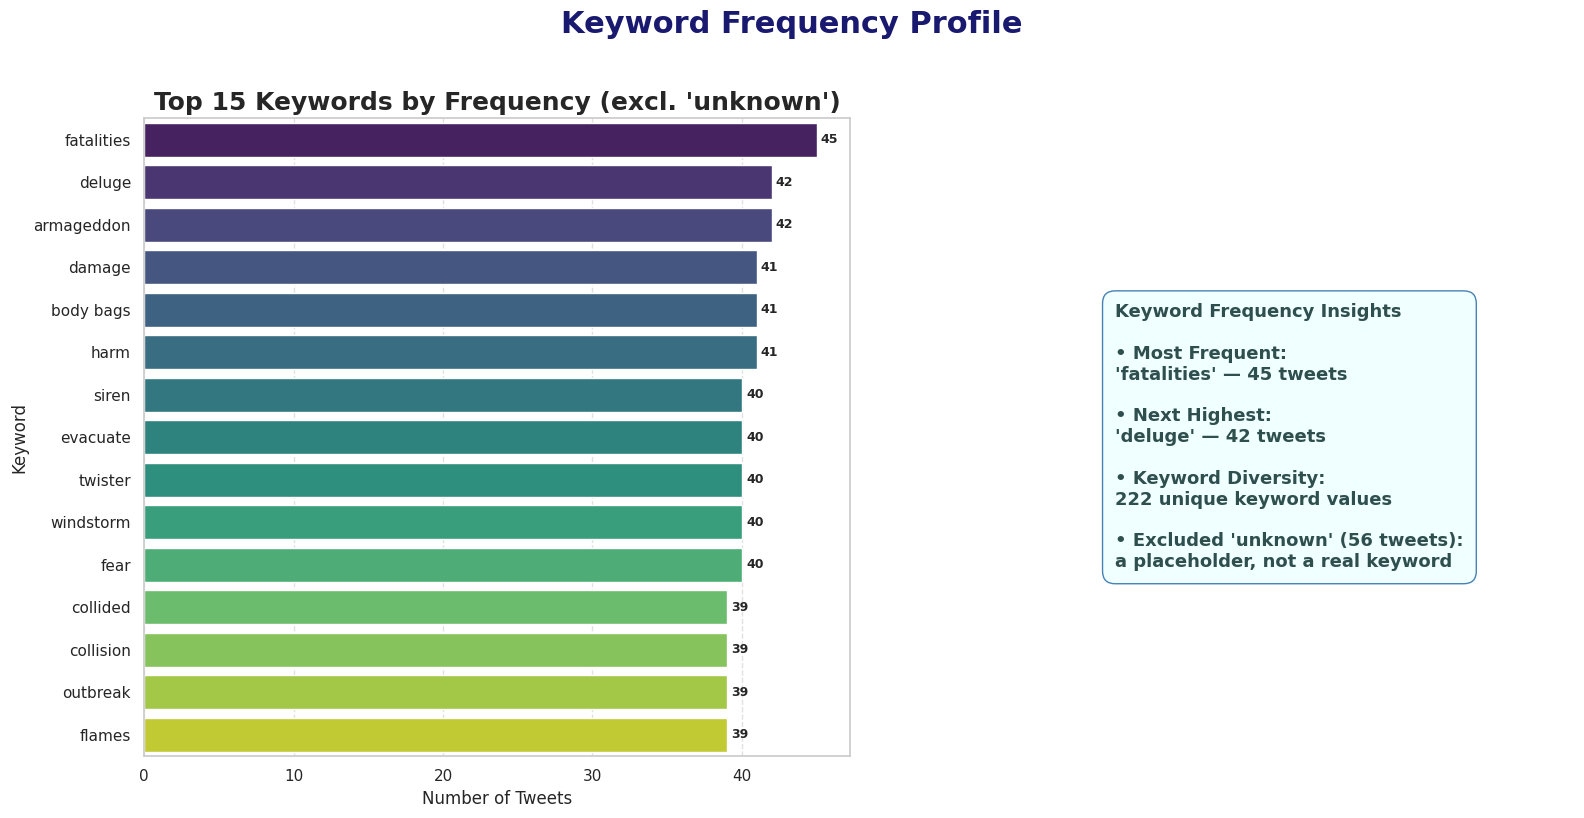

2026-10-12 17:44:40,495 - disaster_classification - INFO - Univariate keyword analysis plotted: top 15 keyword frequencies (excl. unknown) with insight summary


In [38]:
section_header("Exploratory Data Analysis")
subsection_header("Univariate Analysis — Keyword Profile")

top_keywords = (df_refined[df_refined["keyword"] != "unknown"]["keyword"].astype(str).value_counts().head(15))
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle("Keyword Frequency Profile",fontsize=22,fontweight="bold",y=1.02,color=PLOT_COLOR)
fig.subplots_adjust(wspace=0.3, hspace=0.4)

sns.barplot(x=top_keywords.values,y=top_keywords.index,hue=top_keywords.index,palette="viridis",legend=False,ax=axes[0])
axes[0].set_title("Top 15 Keywords by Frequency (excl. 'unknown')",fontweight="bold",fontsize=18)
axes[0].set_xlabel("Number of Tweets")
axes[0].set_ylabel("Keyword")
axes[0].grid(axis="x", linestyle="--", alpha=0.6)
axes[0].set_xlim(0, top_keywords.max() * 1.05)
for c in axes[0].containers:
    axes[0].bar_label(c,fmt="%d",padding=3,fontsize=9,fontweight="bold")

axes[1].axis("off")
top_keyword = top_keywords.index[0]
top_keyword_count = int(top_keywords.iloc[0])
second_keyword = top_keywords.index[1]
second_keyword_count = int(top_keywords.iloc[1])
unique_keywords = df_refined["keyword"].nunique()
unknown_count = (df_refined["keyword"].astype(str).str.lower().eq("unknown").sum())

insight_text = (
    "Keyword Frequency Insights\n\n"
    f"• Most Frequent:\n"
    f"'{top_keyword}' — {top_keyword_count:,} tweets\n\n"
    f"• Next Highest:\n"
    f"'{second_keyword}' — {second_keyword_count:,} tweets\n\n"
    f"• Keyword Diversity:\n"
    f"{unique_keywords:,} unique keyword values\n\n"
    f"• Excluded 'unknown' ({unknown_count:,} tweets):\n"
    f"a placeholder, not a real keyword"
)

axes[1].text(0.35,0.5,insight_text,transform=axes[1].transAxes,fontsize=13,va="center",ha="left",color="darkslategray",weight="bold",bbox=dict(boxstyle="round,pad=0.7",facecolor="azure",edgecolor="steelblue"))
plt.tight_layout()
plt.savefig("Assets/eda_univariate_keyword_profile.png",dpi=150,bbox_inches="tight")
plt.show()

logger.info("Univariate keyword analysis plotted: top 15 keyword frequencies (excl. unknown) with insight summary")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Keyword Frequency:**

- `unknown` is excluded from this ranking — it's a placeholder created during Missing-Value Treatment for the 56 tweets that had no original keyword, not a real disaster term, so it has no place competing for "most frequent keyword."
- Among genuine keywords, **`fatalities`** is the most frequent, appearing in **45 tweets**, followed by **`armageddon`** and **`deluge`**, tied at **42 tweets** each. This gap is modest, not dramatic — the top keywords cluster tightly together (39–45 tweets) rather than one term dominating.
- The dataset contains **222 unique keyword values** in total, showing considerable diversity even though a top-15 subset recurs more often than the rest.

This distribution also highlights why keyword information alone is insufficient for the classification task. A keyword can indicate a disaster-related concept without guaranteeing that the tweet describes an actual disaster — "armageddon," for instance, is frequently used metaphorically.

*The surrounding wording and context therefore remain essential for distinguishing genuine disaster reports from non-disaster uses of similar terminology.*

<hr style="width:45%; margin:auto;">

</div>

### 📌 Univariate Analysis — Class Balance

<div style="margin-left: 20px; max-width: 90%">

The target distribution on the cleaned dataset, to confirm the degree of imbalance the models must handle.

</div>

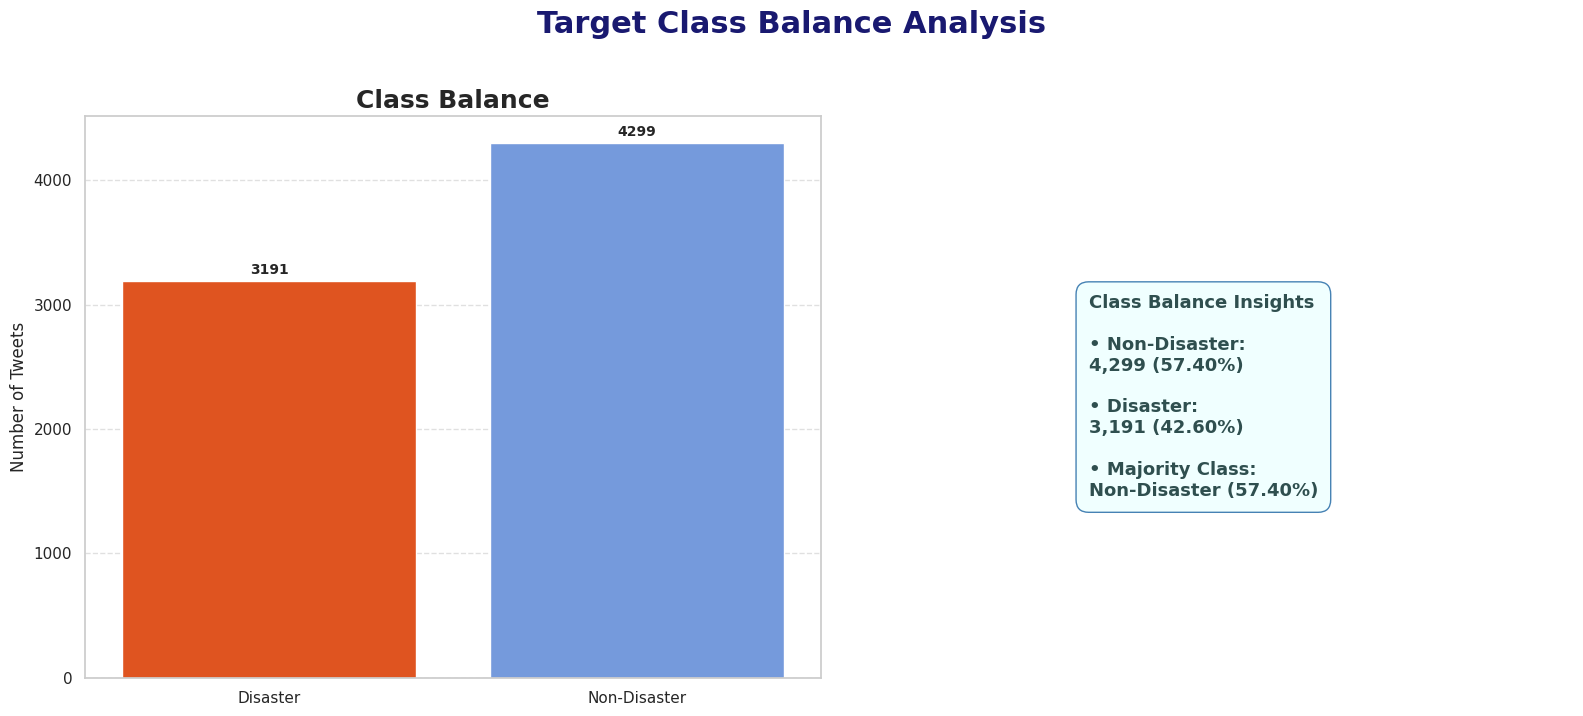

2026-10-12 17:45:59,780 - disaster_classification - INFO - Univariate distribution analysis plotted: class balance, tweet character/word length, and insight summary


In [39]:
subsection_header("Univariate Analysis — Class Balance")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Target Class Balance Analysis",fontsize=22,fontweight="bold",y=1.02,color=PLOT_COLOR)
fig.subplots_adjust(wspace=0.28,hspace=0.35)

class_palette = {"Disaster": "orangered","Non-Disaster": "cornflowerblue"}
class_counts = df_refined["target_label"].value_counts()
sns.countplot(data=df_refined,x="target_label",hue="target_label",palette=class_palette,legend=False,ax=axes[0])
axes[0].set_title("Class Balance",fontweight="bold",fontsize=18)
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of Tweets")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)
# Add count labels
for c in axes[0].containers:
    axes[0].bar_label(c,fmt="%d",padding=3,fontsize=10,fontweight="bold")
axes[0].set_ylim(0, class_counts.max() * 1.05)
axes[1].axis("off")

total_rows = len(df_refined)
disaster_count = int(class_counts.get("Disaster", 0))
non_disaster_count = int(class_counts.get("Non-Disaster", 0))
disaster_pct = disaster_count / total_rows * 100
non_disaster_pct = non_disaster_count / total_rows * 100

insight_text = (
    "Class Balance Insights\n\n"
    f"• Non-Disaster:\n"
    f"{non_disaster_count:,} ({non_disaster_pct:.2f}%)\n\n"
    f"• Disaster:\n"
    f"{disaster_count:,} ({disaster_pct:.2f}%)\n\n"
    f"• Majority Class:\n"
    f"Non-Disaster ({non_disaster_pct:.2f}%)"
)

axes[1].text(0.34,0.5,insight_text,transform=axes[1].transAxes,fontsize=13,va="center",ha="left",color="darkslategray",weight="bold",bbox=dict(boxstyle="round,pad=0.7",facecolor="azure",edgecolor="steelblue"))

plt.tight_layout()
plt.savefig("Assets/eda_univariate_class_balance.png",dpi=150,bbox_inches="tight")
plt.show()

logger.info("Univariate distribution analysis plotted: class balance, tweet character/word length, and insight summary")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Class Balance:**

The cleaned dataset contains **7,490 tweets**, of which **4,299 (57.40%)** are Non-Disaster and **3,191 (42.60%)** are Disaster.

The distribution shows a moderate difference in class representation, with Non-Disaster tweets forming the majority.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Univariate Analysis — Numeric Feature Distributions

<div style="margin-left: 20px; max-width: 90%">

All 13 scalar numeric features in one pass — no class split (that's Bivariate's job) — with skew, kurtosis, and IQR-based outlier counts for each.

</div>

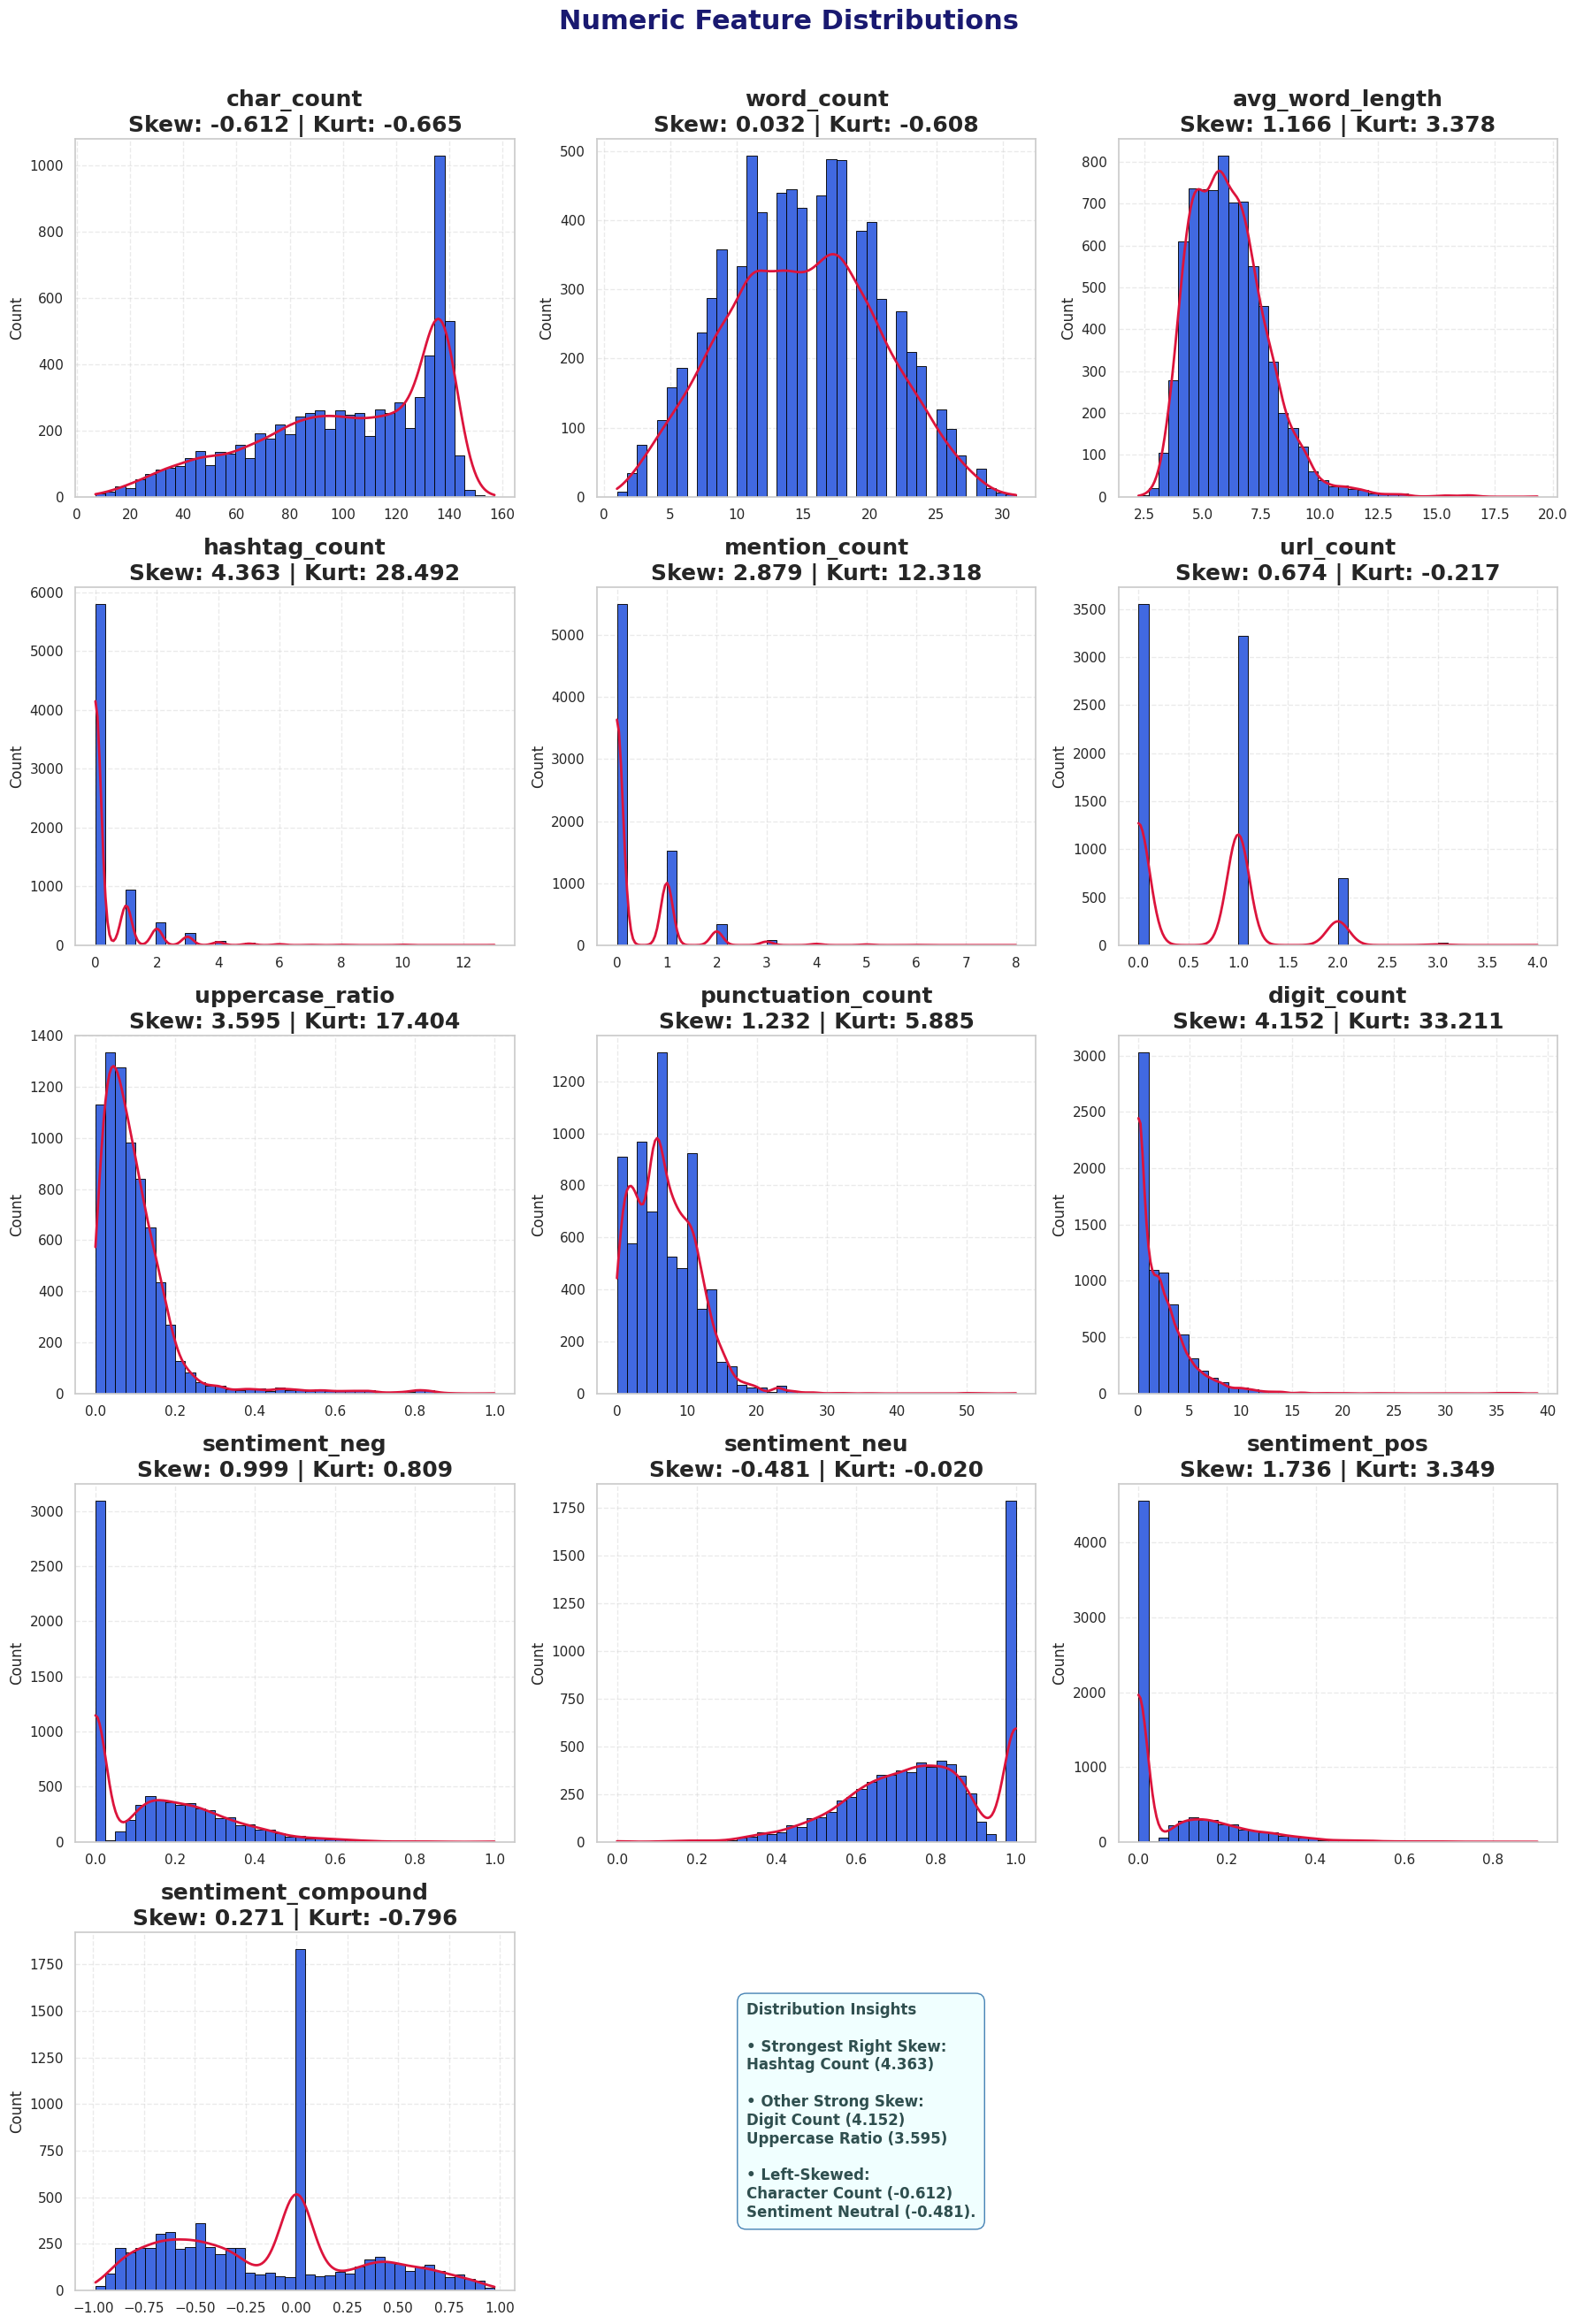

In [41]:
subsection_header("Univariate Analysis: Numeric Feature Distributions")

numeric_cols = df_refined.select_dtypes(include="number").drop(columns=["id", "target"]).columns.tolist()
info_box(f"<b>{len(numeric_cols)} numeric features</b> to display as histograms with skew/kurtosis values.")

outlier_rows = []
fig, axes = plt.subplots(5, 3, figsize=(18, 26))
fig.suptitle("Numeric Feature Distributions", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.01)
fig.subplots_adjust(wspace=0.3, hspace=0.5)
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    vals = df_refined[col].dropna()
    sk_val, kt_val = skew(vals), kurtosis(vals)
    sns.histplot(vals, kde=True, color="crimson", facecolor="royalblue", edgecolor="black", bins=40, ax=axes[i], line_kws={"linewidth": 2})
    axes[i].set_title(f"{col}\nSkew: {sk_val:.3f} | Kurt: {kt_val:.3f}", fontweight="bold", fontsize=18)
    axes[i].set_xlabel("")
    axes[i].grid(True, linestyle="--", alpha=0.4)

for j in range(len(numeric_cols), 15):
    axes[j].axis("off")

insight_text = (
    "Distribution Insights\n\n"
    "• Strongest Right Skew:\n"
    "Hashtag Count (4.363)\n\n"
    "• Other Strong Skew:\n"
    "Digit Count (4.152)\n"
    "Uppercase Ratio (3.595)\n\n"
    "• Left-Skewed:\n"
    "Character Count (-0.612)\n"
    "Sentiment Neutral (-0.481)."
)
axes[13].text(0.34, 0.5, insight_text, transform=axes[13].transAxes, fontsize=12, va="center", ha="left",color="darkslategray", weight="bold",bbox=dict(boxstyle="round,pad=0.6", facecolor="azure", edgecolor="steelblue"))

plt.tight_layout()
plt.savefig("Assets/eda_univariate_numeric_grid.png", dpi=150, bbox_inches="tight")
plt.show()

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Numeric Feature Distributions:**

- The strongest right-skewed features are `hashtag_count` with a skewness of **4.363**, `digit_count` with **4.152**, and `uppercase_ratio` with **3.595**. These values indicate that most tweets have relatively low values for these features, while a smaller number of tweets contain much larger values.
- Other structural features also show positive skewness. `mention_count` has a skewness of **2.879**, while `punctuation_count` has a skewness of **1.232**. These patterns indicate that count-based Twitter features tend to contain many observations near the lower end of their ranges.
- The sentiment features have different distributional shapes. `sentiment_pos` is positively skewed at **1.736**, whereas `sentiment_neu` is negatively skewed at **-0.481**. `char_count` is also negatively skewed at **-0.612**, while `word_count` is approximately symmetric with a skewness of only **0.032**.

These results show that the numeric features do not follow a common distributional pattern.

<hr style="width:45%; margin:auto;">

</div>


### 📌 Univariate Analysis — Outlier Severity (Boxplots)

<div style="margin-left: 20px; max-width: 90%">

The same 13 numeric features are examined using boxplots to assess the prevalence and spread of IQR-defined outliers.

The purpose is to identify unusual observations for further consideration—not to automatically remove or cap them. In tweet data, extreme values may reflect genuine usage patterns, such as unusually high hashtag, digit, punctuation, or uppercase counts.

</div>

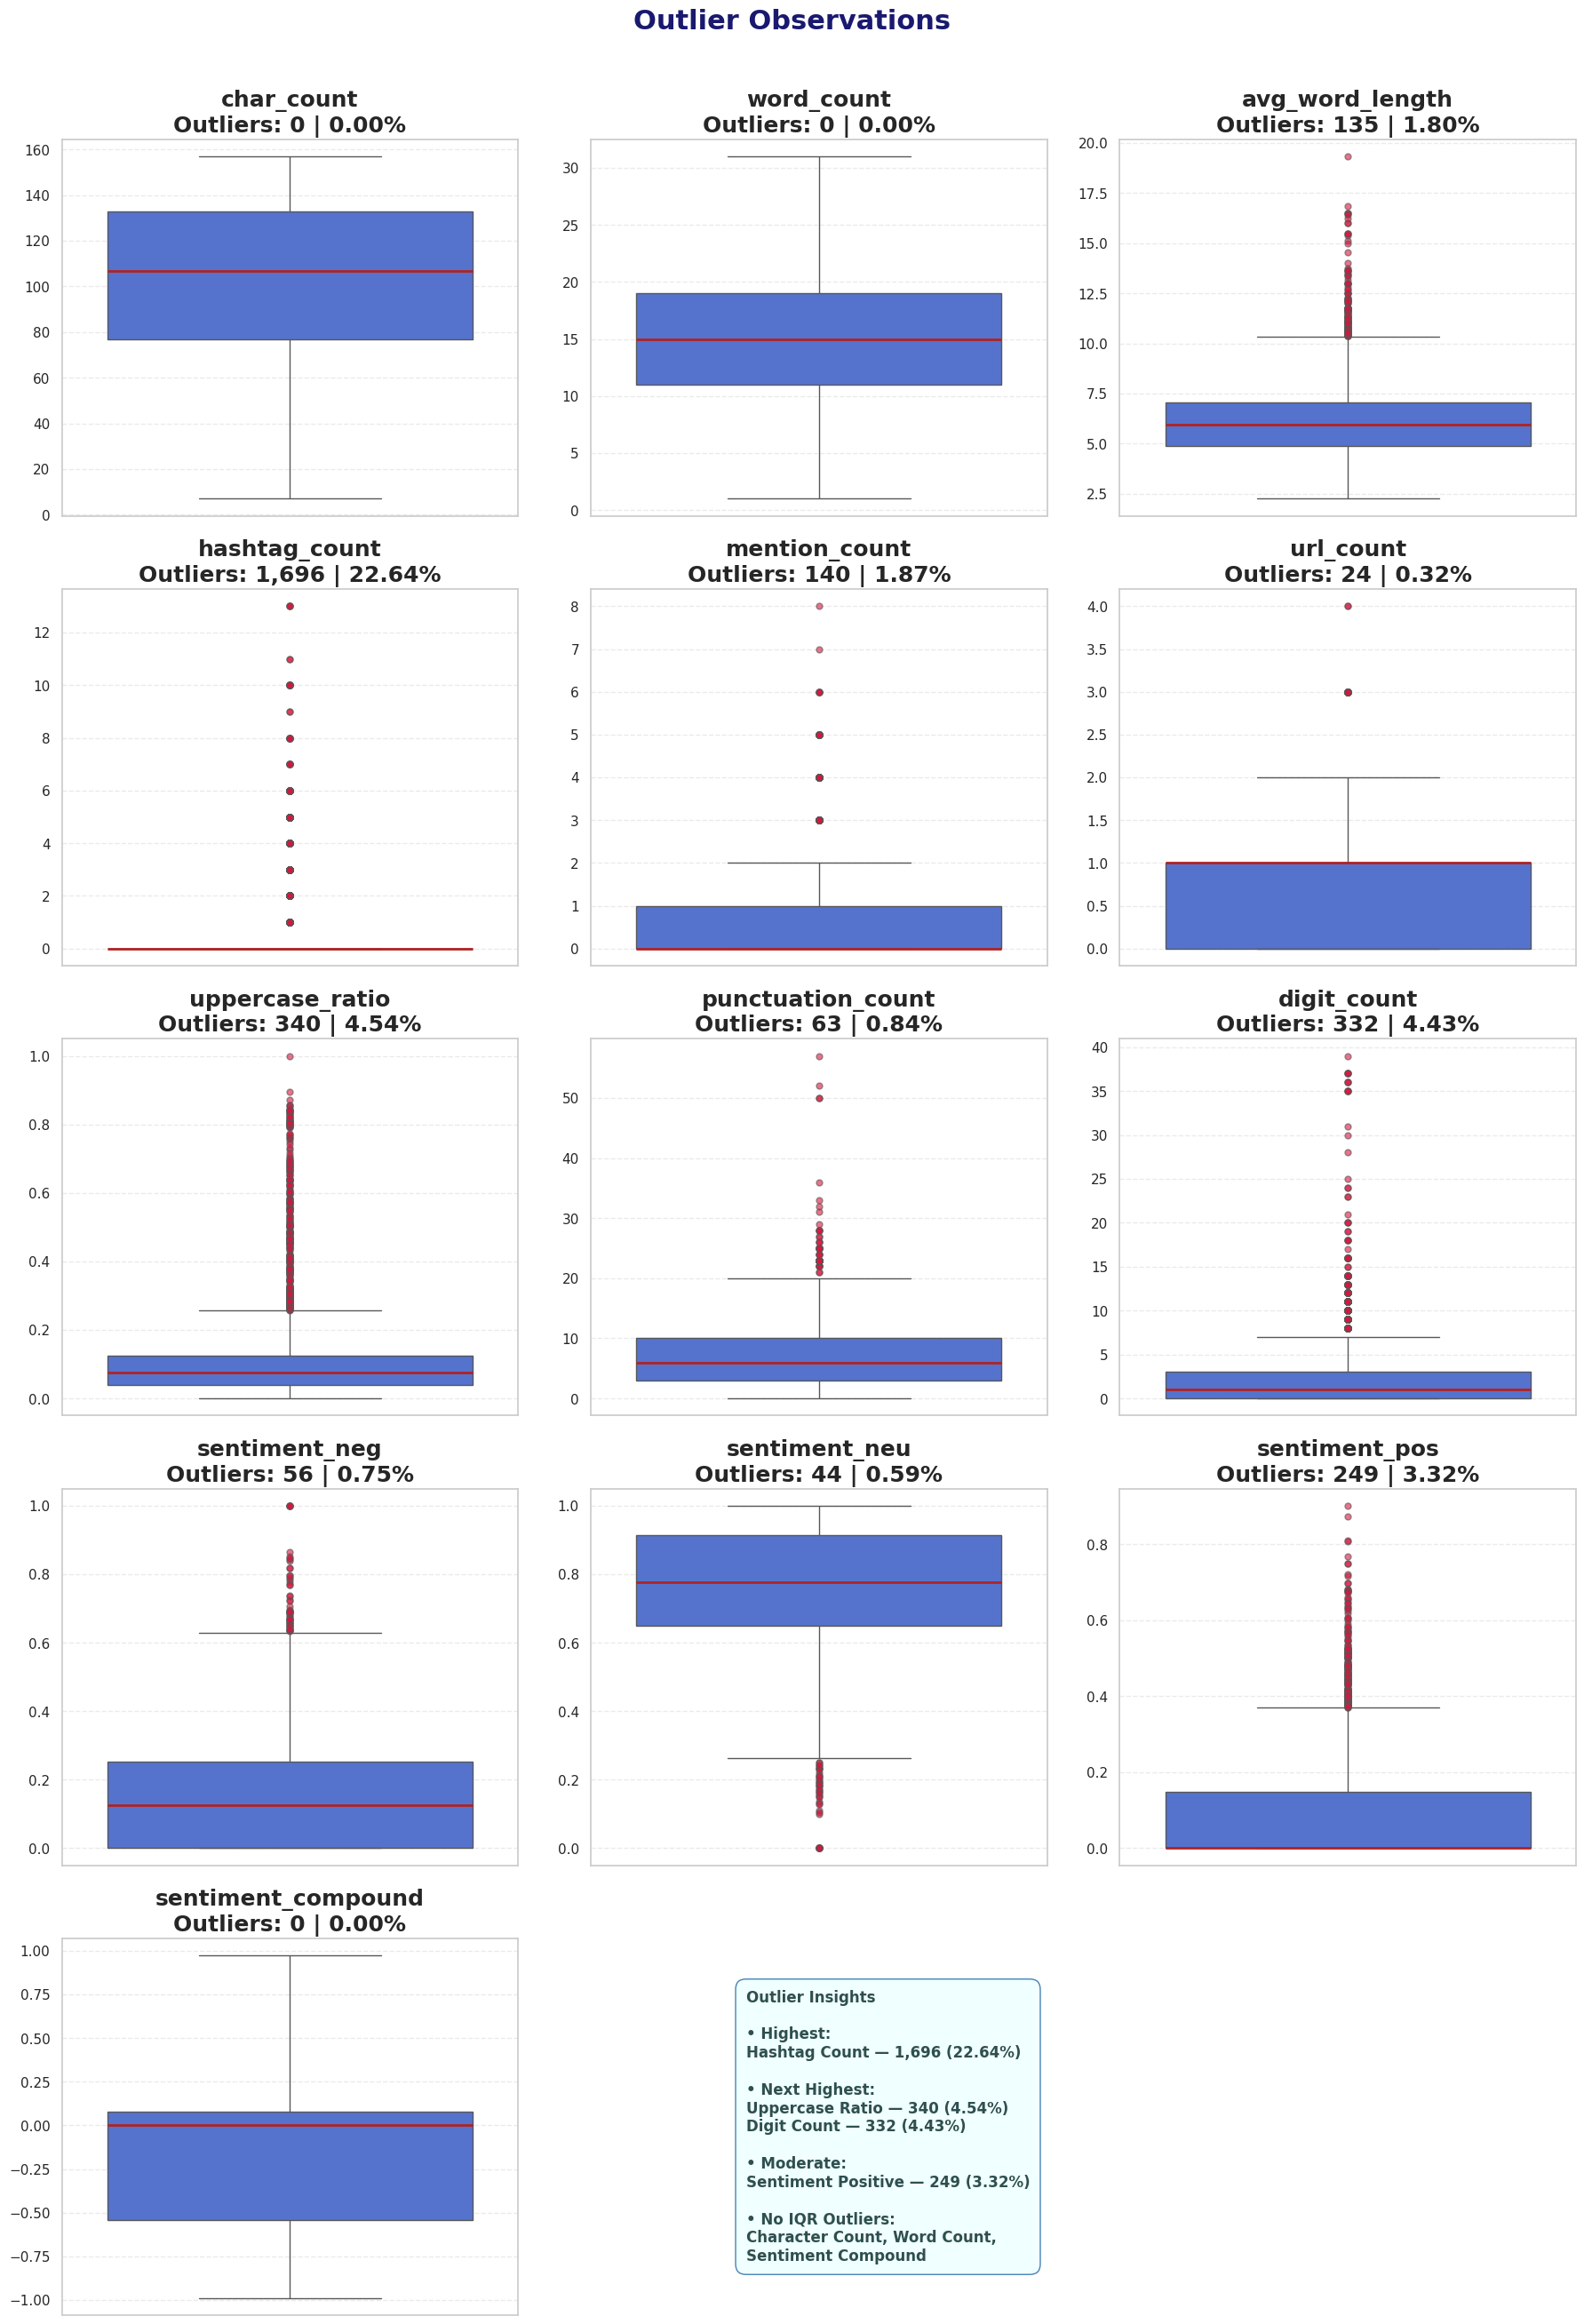

2026-10-12 17:51:18,257 - disaster_classification - INFO - Univariate boxplot grid rendered — outlier severity assessed for all 13 numeric features


In [43]:
subsection_header("Univariate Analysis: Boxplots")

info_box(f"<b>{len(numeric_cols)} features</b> displayed as boxplots to assess outlier severity.")
fig, axes = plt.subplots(5, 3, figsize=(18, 26))
fig.suptitle("Outlier Observations", fontsize=22, color=PLOT_COLOR, fontweight="bold", y=1.01)
fig.subplots_adjust(wspace=0.3, hspace=0.5)
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    vals = df_refined[col].dropna()
    outliers = detect_outliers_iqr(vals)
    pct = len(outliers) / len(vals) * 100

    sns.boxplot(y=vals, ax=axes[i], color="royalblue",medianprops=dict(color="firebrick", linewidth=2),flierprops=dict(marker="o", markerfacecolor="crimson", markersize=5, alpha=0.6))
    axes[i].set_title(f"{col}\nOutliers: {len(outliers):,} | {pct:.2f}%", fontweight="bold", fontsize=18)
    axes[i].set_ylabel("")
    axes[i].grid(True, linestyle="--", alpha=0.4, axis="y")

for j in range(len(numeric_cols), 15):
    axes[j].axis("off")
outlier_summary_boxplot = []

for col in numeric_cols:
    vals = df_refined[col].dropna()
    outliers = detect_outliers_iqr(vals)
    outlier_summary_boxplot.append((col, len(outliers), len(outliers) / len(vals) * 100))

outlier_summary_boxplot = pd.DataFrame(outlier_summary_boxplot,columns=["feature", "outlier_count", "outlier_pct"])
ranked_outliers = outlier_summary_boxplot.sort_values("outlier_pct", ascending=False)
top_feature = ranked_outliers.iloc[0]
zero_outlier_features = ranked_outliers.loc[ranked_outliers["outlier_count"] == 0, "feature"].tolist()

insight_text = (
    "Outlier Insights\n\n"
    "• Highest:\n"
    "Hashtag Count — 1,696 (22.64%)\n\n"
    "• Next Highest:\n"
    "Uppercase Ratio — 340 (4.54%)\n"
    "Digit Count — 332 (4.43%)\n\n"
    "• Moderate:\n"
    "Sentiment Positive — 249 (3.32%)\n\n"
    "• No IQR Outliers:\n"
    "Character Count, Word Count,\n"
    "Sentiment Compound"
)

axes[13].axis("off")
axes[13].text(0.34, 0.5, insight_text,transform=axes[13].transAxes,fontsize=12, va="center", ha="left",color="darkslategray", weight="bold",bbox=dict(boxstyle="round,pad=0.7",facecolor="azure", edgecolor="steelblue"))

plt.tight_layout()
plt.savefig("Assets/eda_univariate_boxplot_grid.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Univariate boxplot grid rendered — outlier severity assessed for all 13 numeric features")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Boxplots (Outlier Severity):**

- The `hashtag_count` has the highest concentration, with **1,696 outliers (22.64%)**. This is considerably higher than the next most affected features: `uppercase_ratio` with **340 outliers (4.54%)** and `digit_count` with **332 (4.43%)**.
- The `sentiment_pos` contains **249 IQR-defined outliers (3.32%)**, followed by `mention_count` with **140 (1.87%)** and `avg_word_length` with **135 (1.80%)**. In contrast, `char_count`, `word_count`, and `sentiment_compound` have **zero IQR-defined outliers**.
- The high outlier count for `hashtag_count` should be interpreted together with its skewness of **4.363**. Because the feature is strongly right-skewed, a large number of observations naturally fall beyond the upper IQR boundary.

<hr style="width:45%; margin:auto;">

</div>


### 📌 Outlier Detection — IQR & Z-Score Decision Table

<div style="margin-left: 20px; max-width: 90%">

Cross-checking IQR and Z-score flags per feature before deciding treatment — where the two methods disagree sharply, that's itself diagnostic (usually a zero-inflated distribution breaking IQR's assumptions, not a genuine outlier problem).

</div>

In [44]:
subsection_header("Outlier Detection — IQR & Z-Score Decision Table")

decision_rows = []
for col in numeric_cols:
    vals = df_refined[col].dropna()
    iqr_n = len(detect_outliers_iqr(vals))
    z_n = len(detect_outliers_zscore(vals))
    iqr_pct = iqr_n / len(vals) * 100

    if iqr_n == 0 and z_n == 0:
        decision, justification = "Retained", "No outliers flagged by either method"
    elif iqr_n > 0 and z_n > 0 and iqr_n / max(z_n, 1) > 5:
        decision, justification = "Special Case", "IQR vastly overstates vs. Z-score — zero-inflated distribution breaks IQR's assumptions, not genuine extremity"
    elif iqr_pct < 1:
        decision, justification = "Retained", "Both methods detect some outliers, but too small a share to be worth treating"
    else:
        decision, justification = "Pending Cap", "Both methods agree on a real tail"

    decision_rows.append((col, iqr_n, z_n, decision, justification))

decision_table = pd.DataFrame(decision_rows, columns=["feature", "iqr_flags", "z_flags", "decision", "justification"])

overrides = {
    "mention_count": "Overridden to Retained — max is only 8, a plausible genuine style choice (tagging multiple people), not noise; tree-based models downstream are robust to this tail",
    "sentiment_pos": "Overridden to Retained — a strongly positive tone is real signal, not an error; capping risks losing informative variation for no benefit to the tree-based models using this feature"}
for feat, note in overrides.items():
    decision_table.loc[decision_table["feature"] == feat, "decision"] = "Retained"
    decision_table.loc[decision_table["feature"] == feat, "justification"] = note

DECISION_COLORS = {"Pending Cap": "#E74C3C", "Special Case": "#3498DB", "Retained": "#2ECC71"}
decision_table["decision"] = decision_table["decision"].apply(lambda d: f'<span style="background:{DECISION_COLORS[d]};color:white;padding:4px 12px;border-radius:12px;font-weight:bold;white-space:nowrap;">{d}</span>')
centered_table(decision_table)

final_cap_list = ["avg_word_length", "hashtag_count", "uppercase_ratio", "digit_count"]
info_box(f"Final treatment plan: <b>{len(final_cap_list)} features</b> to cap — {', '.join(final_cap_list)}. Everything else retained as-is.")

logger.info(f"Outlier decision table finalized — capping: {final_cap_list}")

feature,iqr_flags,z_flags,decision,justification
char_count,0,0,Retained,No outliers flagged by either method
word_count,0,0,Retained,No outliers flagged by either method
avg_word_length,135,83,Pending Cap,Both methods agree on a real tail
hashtag_count,1696,163,Special Case,"IQR vastly overstates vs. Z-score — zero-inflated distribution breaks IQR's assumptions, not genuine extremity"
mention_count,140,140,Retained,"Overridden to Retained — max is only 8, a plausible genuine style choice (tagging multiple people), not noise; tree-based models downstream are robust to this tail"
url_count,24,24,Retained,"Both methods detect some outliers, but too small a share to be worth treating"
uppercase_ratio,340,190,Pending Cap,Both methods agree on a real tail
punctuation_count,63,63,Retained,"Both methods detect some outliers, but too small a share to be worth treating"
digit_count,332,93,Pending Cap,Both methods agree on a real tail
sentiment_neg,56,56,Retained,"Both methods detect some outliers, but too small a share to be worth treating"


2026-10-12 17:53:24,765 - disaster_classification - INFO - Outlier decision table finalized — capping: ['avg_word_length', 'hashtag_count', 'uppercase_ratio', 'digit_count']


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Outlier Decision Table:**

- Four features are flagged for capping: `avg_word_length`, `uppercase_ratio`, `digit_count` (both methods agree on a real tail — 1.8%, 4.54%, 4.43% respectively), and `hashtag_count` as a Special Case (IQR flags 22.64% vs. Z-score's 2.18% — a 10x disagreement caused by `hashtag_count`'s zero-inflated distribution breaking IQR's assumptions; its skew of 4.363 and kurtosis of 28.49 confirm a real but overstated tail).
- Two features that mechanically qualified — `mention_count` (140/140, 1.87%) and `sentiment_pos` (249/122, 3.32%) — are deliberately retained instead. Both represent plausible genuine tweet content (multiple people tagged, strongly positive tone) rather than data errors, so capping would risk discarding real signal for no modeling benefit.
- The remaining 7 features (`char_count`, `word_count`, `url_count`, `punctuation_count`, `sentiment_neg`, `sentiment_neu`, `sentiment_compound`) show zero or negligible outliers by both methods and need no treatment.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Outlier Treatment — Percentile Capping

<div style="margin-left: 20px; max-width: 90%">

Capping the 4 flagged features at the 99th percentile (Winsorization) — not IQR bounds, since `hashtag_count` specifically breaks IQR's assumptions on zero-inflated data. Trims only the genuine extreme tail (~1% of rows per feature) without reshaping the bulk of the distribution.

</div>

In [45]:
subsection_header("Outlier Treatment — Percentile Capping")

cap_cols = ["avg_word_length", "hashtag_count", "uppercase_ratio", "digit_count"]
treatment_rows = []

for col in cap_cols:
    before_sk, before_kt = skew(df_refined[col]), kurtosis(df_refined[col])
    cap_value = df_refined[col].quantile(0.99)
    n_capped = (df_refined[col] > cap_value).sum()

    df_refined[col] = df_refined[col].clip(upper=cap_value)

    after_sk, after_kt = skew(df_refined[col]), kurtosis(df_refined[col])
    treatment_rows.append((col, round(cap_value, 3), int(n_capped), round(n_capped / len(df_refined) * 100, 2),round(before_sk, 3), round(after_sk, 3), round(before_kt, 3), round(after_kt, 3)))
    logger.debug(f"Capped '{col}' at 99th percentile ({cap_value:.3f}) — {n_capped} rows affected")

treatment_summary = pd.DataFrame(treatment_rows, columns=["feature", "cap_value_99th", "rows_capped", "pct_capped","skew_before", "skew_after", "kurt_before", "kurt_after"])
total_capped = treatment_summary["rows_capped"].sum()
treatment_summary["pct_capped"] = treatment_summary["pct_capped"].astype(str) + "%"
treatment_summary = treatment_summary.rename(columns={
    "feature": "Feature", "cap_value_99th": "99th Percentile Cap", "rows_capped": "Rows Capped",
    "pct_capped": "% Capped", "skew_before": "Skew (Before)", "skew_after": "Skew (After)",
    "kurt_before": "Kurtosis (Before)", "kurt_after": "Kurtosis (After)"})
centered_table(treatment_summary)

success_box(f"4 features capped at their 99th percentile — <b>{total_capped} total value replacements</b> across <b>{df_refined.shape[0]} rows</b>, no rows dropped.")
logger.info(f"Outlier treatment complete — capped: {cap_cols}")

2026-10-12 17:56:10,657 - disaster_classification - DEBUG - Capped 'avg_word_length' at 99th percentile (11.364) — 73 rows affected
2026-10-12 17:56:10,670 - disaster_classification - DEBUG - Capped 'hashtag_count' at 99th percentile (5.000) — 56 rows affected
2026-10-12 17:56:10,684 - disaster_classification - DEBUG - Capped 'uppercase_ratio' at 99th percentile (0.643) — 75 rows affected
2026-10-12 17:56:10,699 - disaster_classification - DEBUG - Capped 'digit_count' at 99th percentile (12.000) — 73 rows affected


Feature,99th Percentile Cap,Rows Capped,% Capped,Skew (Before),Skew (After),Kurtosis (Before),Kurtosis (After)
avg_word_length,11.3640,73,0.97%,1.1660,0.7190,3.3780,0.5270
hashtag_count,5.0000,56,0.75%,4.3630,2.8210,28.4920,8.4650
uppercase_ratio,0.6430,75,1.0%,3.5950,3.0460,17.4040,12.0800
digit_count,12.0000,73,0.97%,4.1520,1.7560,33.2110,3.3230


2026-10-12 17:56:10,720 - disaster_classification - INFO - Outlier treatment complete — capped: ['avg_word_length', 'hashtag_count', 'uppercase_ratio', 'digit_count']


### 📌 Post-Treatment Distributions

<div style="margin-left: 20px; max-width: 90%">

The 4 capped features only — confirming the capping actually improved shape, not a repeat of all 13.

</div>

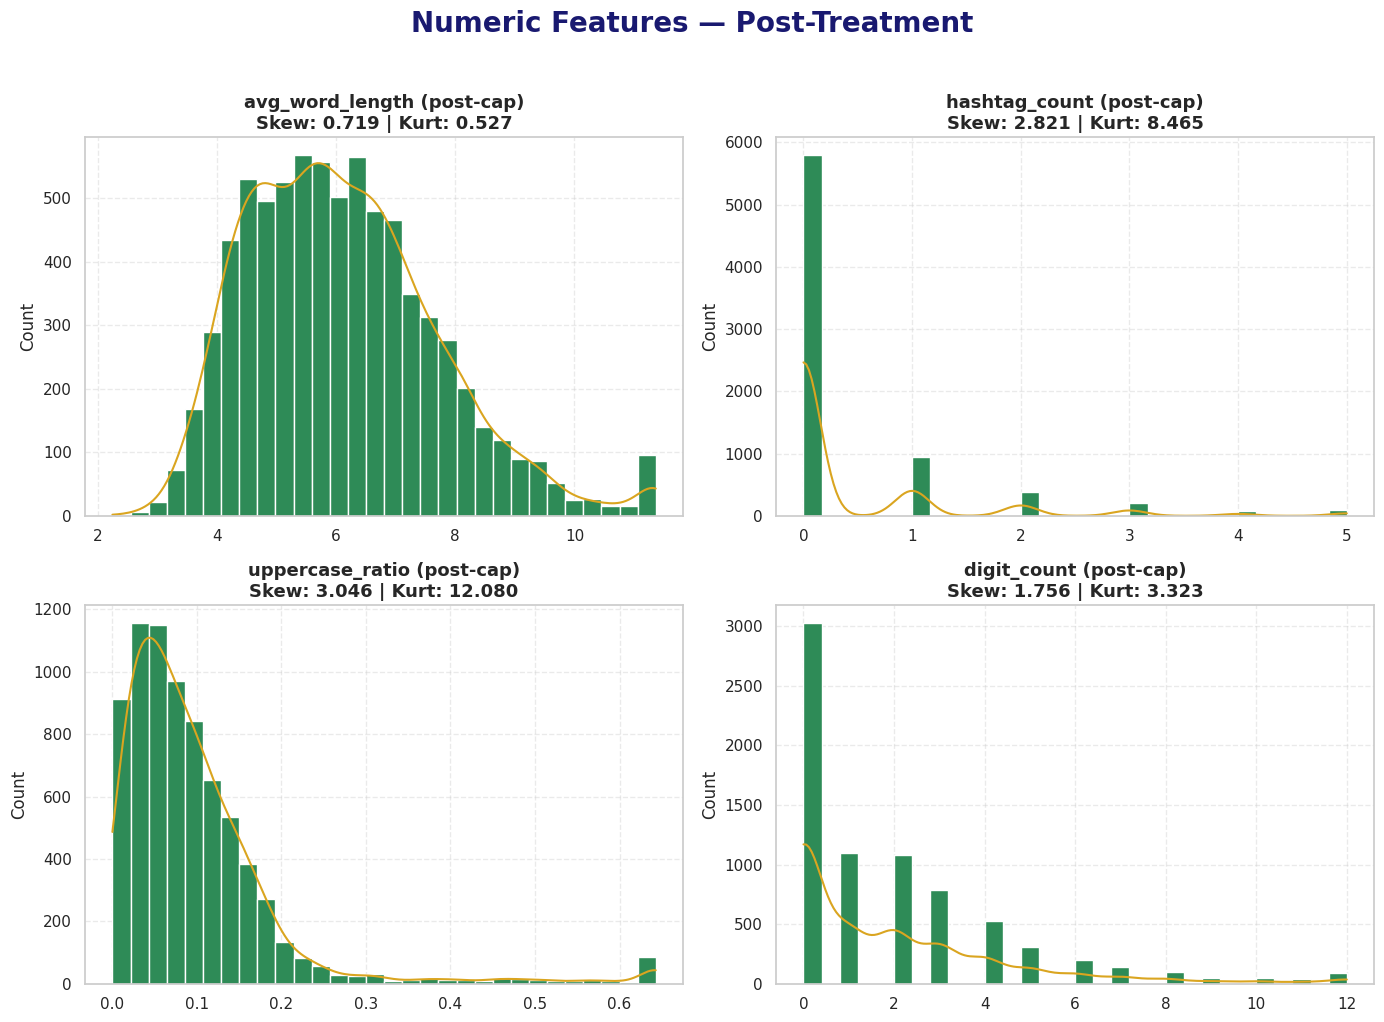

2026-10-12 17:56:24,242 - disaster_classification - INFO - Post-treatment distributions rendered for capped features


In [46]:
subsection_header("Post-Treatment Distributions")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Numeric Features — Post-Treatment", fontsize=20, color=PLOT_COLOR, fontweight="bold", y=1.02)
axes = axes.flatten()

for i, col in enumerate(cap_cols):
    sk_val, kt_val = skew(df_refined[col]), kurtosis(df_refined[col])
    sns.histplot(df_refined[col], kde=True, color= 'goldenrod',facecolor="seagreen", bins=30, ax=axes[i])
    axes[i].set_title(f"{col} (post-cap)\nSkew: {sk_val:.3f} | Kurt: {kt_val:.3f}", fontweight="bold", fontsize=13)
    axes[i].set_xlabel("")
    axes[i].grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Assets/eda_univariate_post_treatment.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Post-treatment distributions rendered for capped features")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Outlier Treatment:**

- Capping at the 99th percentile meaningfully improved shape across all 4 features — `digit_count` saw the largest gain (kurtosis 33.211→3.323), followed by `hashtag_count` (28.492→8.465), `avg_word_length` (3.378→0.527), and `uppercase_ratio` (17.404→12.080).
- `hashtag_count` and `uppercase_ratio` remain somewhat skewed even after capping — expected, since both are genuinely zero-inflated (most tweets have 0 hashtags; most text is lowercase), a structural property no amount of capping fully removes, not a sign the treatment failed.
- Only 277 total values were replaced across 7,490 rows (under 1% per feature) — no rows dropped, data integrity preserved.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Univariate Analysis — Disaster-Type Frequency

<div style="margin-left: 20px; max-width: 90%">

Frequency of the 13 disaster-type categories — the richest categorical feature created in Feature Engineering.

</div>

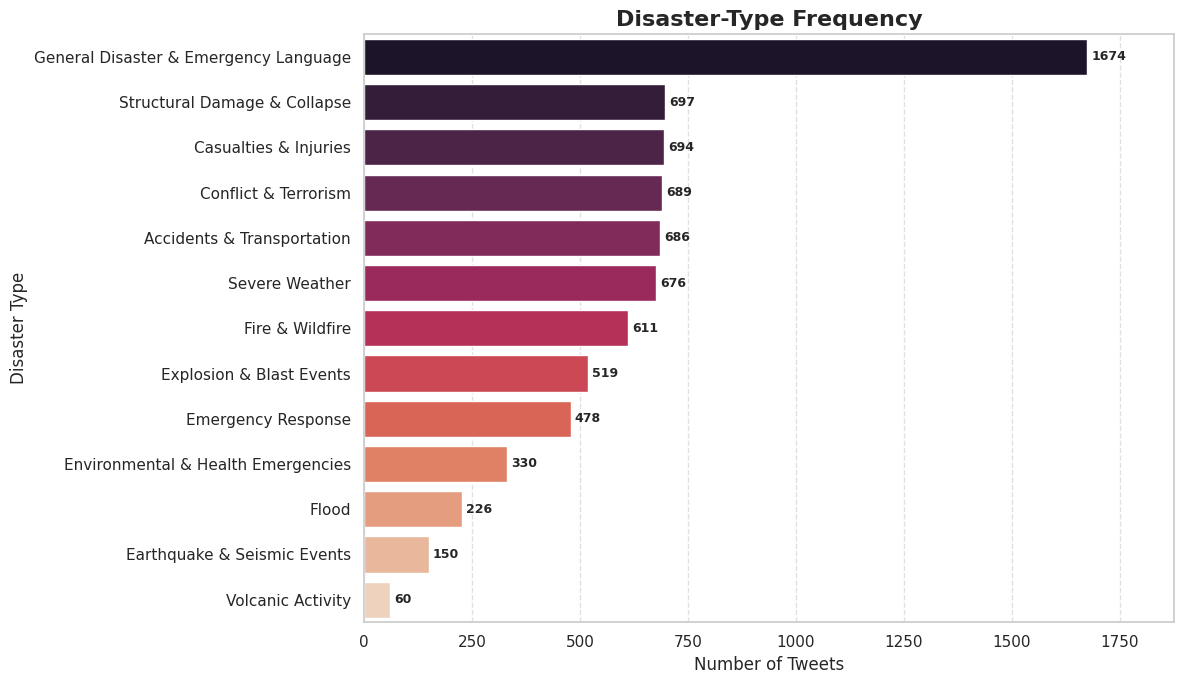

2026-10-12 17:57:29,015 - disaster_classification - INFO - Univariate disaster_type frequency plotted


In [47]:
subsection_header("Univariate Analysis — Disaster-Type Frequency")

dt_counts = df_refined["disaster_type"].astype(str).value_counts()

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(x=dt_counts.values, y=dt_counts.index, hue=dt_counts.index, palette="rocket", legend=False, ax=ax)
ax.set_title("Disaster-Type Frequency", fontweight="bold", fontsize=16)
ax.set_xlabel("Number of Tweets")
ax.set_ylabel("Disaster Type")
ax.set_xlim(0, dt_counts.max() * 1.12)
for c in ax.containers:
    ax.bar_label(c, fmt="%d", padding=3, fontsize=9, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("Assets/eda_univariate_disaster_type.png", dpi=150, bbox_inches="tight")
plt.show()

top_type = dt_counts.index[0]
top_type_count = int(dt_counts.iloc[0])
info_box(f"Largest category: <b>'{top_type}'</b> — <b>{top_type_count:,} tweets</b> ({top_type_count/len(df_refined)*100:.2f}%)")

logger.info("Univariate disaster_type frequency plotted")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Disaster-Type Distribution:**

- `General Disaster & Emergency Language` is the largest category, containing **1,674 tweets (22.35%)**, which is substantially higher than the next category, `Structural Damage & Collapse` with **697 tweets (9.31%)**.
- Several categories have relatively similar representation. `Casualties & Injuries` accounts for **694 tweets (9.27%)**, `Conflict & Terrorism` for **689 (9.20%)**, `Accidents & Transportation` for **686 (9.16%)**, and `Severe Weather` for **676 (9.03%)**. This indicates that the middle of the distribution is comparatively spread across several disaster-related themes rather than being dominated by one specific event type.
- At the lower end, `Earthquake & Seismic Events` contains **150 tweets (2.00%)**, while `Volcanic Activity` is the smallest category with only **60 tweets (0.80%)**. These smaller proportions reflect the frequency of the associated keyword and text patterns in the dataset rather than a deliberately balanced set of disaster categories.

*Because these categories were generated using rule-based keyword and text matching, the distribution should be interpreted as an **analytical representation of disaster-related themes**, not as independently verified ground-truth labels*.

<hr style="width:45%; margin:auto;">

</div>


### 📌 Univariate Analysis — Location Frequency

<div style="margin-left: 20px; max-width: 90%">

Examining the most frequently represented location values in the cleaned dataset to understand the geographic information available in the tweets.

Because location is a higher-cardinality feature, the visualization focuses on the **top 15 locations** to maintain readability while showing the dominant location values.

</div>

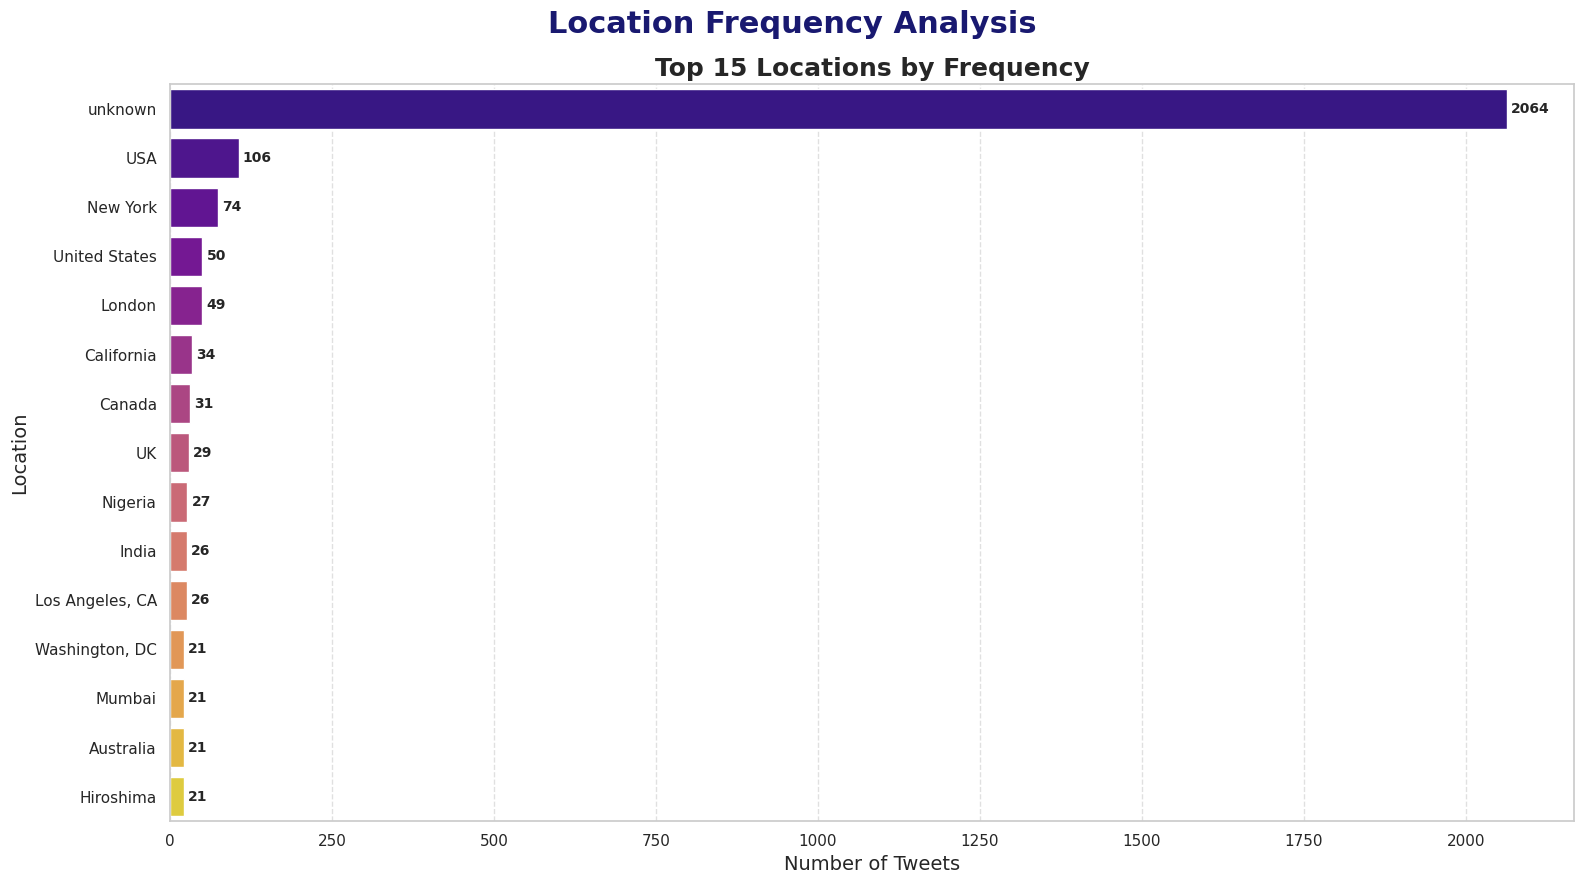

2026-10-12 17:57:51,938 - disaster_classification - INFO - Univariate location analysis plotted — top 15 location frequencies


In [48]:
subsection_header("Univariate Analysis — Location Frequency")

location_counts = (df_refined["location"].astype(str).str.strip().replace("", "unknown").value_counts())
top_locations = location_counts.head(15)

fig, ax = plt.subplots(figsize=(16, 9))
fig.suptitle("Location Frequency Analysis",fontsize=22,fontweight="bold",y=0.98,color=PLOT_COLOR)

sns.barplot(x=top_locations.values,y=top_locations.index,hue=top_locations.index,palette="plasma",legend=False,ax=ax)
ax.set_title("Top 15 Locations by Frequency",fontweight="bold",fontsize=18)
ax.set_xlabel("Number of Tweets",fontsize=14)
ax.set_ylabel("Location",fontsize=14)
ax.grid(axis="x",linestyle="--",alpha=0.6)
for c in ax.containers:
    ax.bar_label(c,fmt="%d",padding=3,fontsize=10,fontweight="bold")

plt.tight_layout()
plt.savefig("Assets/eda_univariate_location_frequency.png",dpi=150,bbox_inches="tight")
plt.show()

logger.info("Univariate location analysis plotted — top 15 location frequencies")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Location Frequency:**

- Unlike the keyword chart, `unknown` is deliberately **kept** here rather than excluded — at 2,064 tweets (27.56%) it's the single largest category by a wide margin. Removing it would understate how much of the dataset genuinely lacks location information.
- Among real locations, `USA` is the most frequent (106 tweets), followed by `New York` (74) and `United States` (50) — note `USA` and `United States` are really the same country reported two ways, and `New York`/`Los Angeles, CA`/`Washington, DC` are US cities, so US-based tweets dominate the real-location share even more than any single bar suggests.
- The remaining top-15 entries (`London`, `California`, `Canada`, `UK`, `Nigeria`, `India`, `Mumbai`, `Australia`, `Hiroshima`) span a genuinely global spread, consistent with Twitter's international reach.
- **The broader picture**: location is real signal for about **72% of the dataset** (5,426 of 7,490 tweets, original + NER-recovered) but is simply absent for the rest.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Univariate Analysis - Sentiment and Location Source

<div style="margin-left: 20px; max-width: 90%">

Examining the distributions of the three-category `sentiment_label` and `location_source` features created during feature engineering.

Pie charts are used here because each feature contains only three categories, allowing the relative proportions to be compared clearly without overcrowding the visualization.

</div>


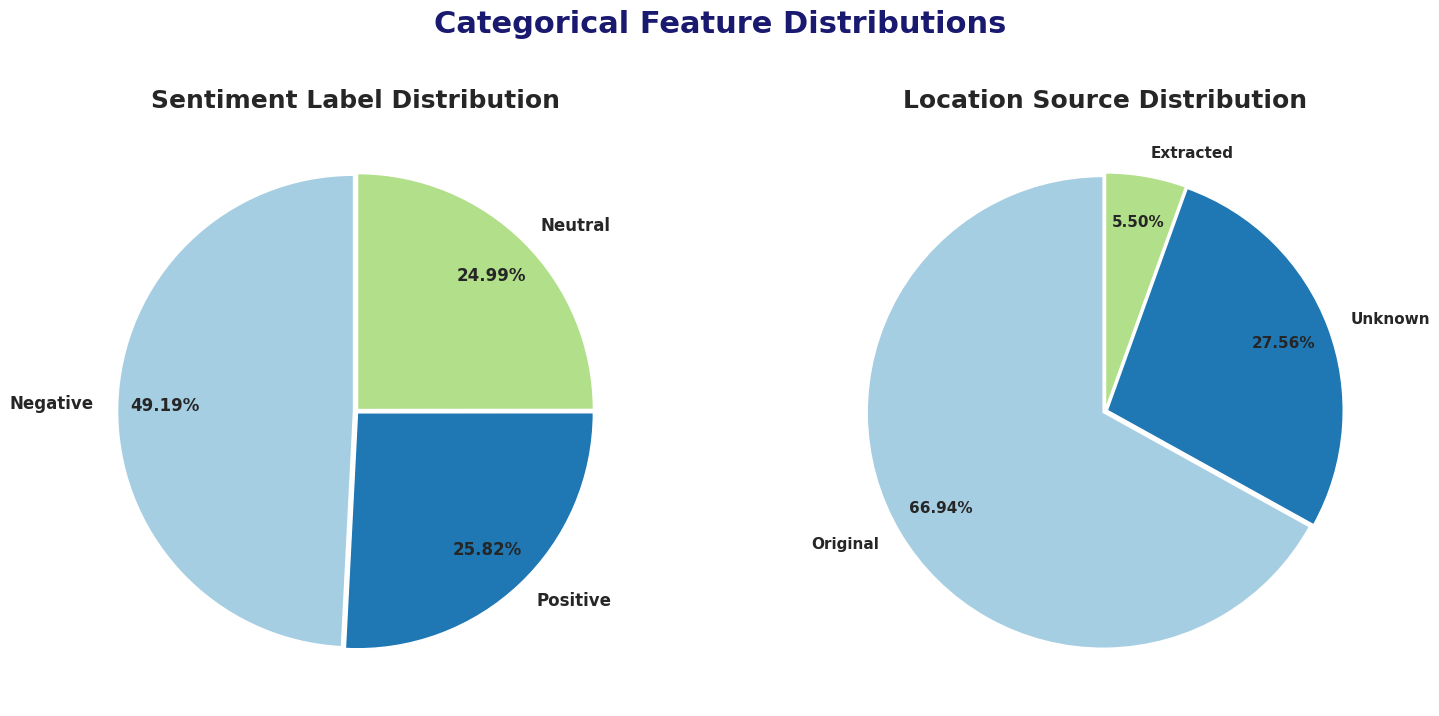

2026-10-12 17:58:12,590 - disaster_classification - INFO - Univariate categorical analysis plotted — sentiment label and location source distributions


In [49]:
subsection_header("Univariate Analysis — Sentiment and Location Source")

sentiment_counts = (df_refined["sentiment_label"].value_counts())
location_source_counts = (df_refined["location_source"].value_counts())

fig, axes = plt.subplots(1,2,figsize=(16, 7))
fig.suptitle("Categorical Feature Distributions",fontsize=22,fontweight="bold",y=1.02,color=PLOT_COLOR)
fig.subplots_adjust(wspace=0.25)

color_map = dict(zip(sentiment_counts.index, sns.color_palette("Paired", len(sentiment_counts))))
sentiment_colors = [color_map[s] for s in sentiment_counts.index]
axes[0].pie(sentiment_counts.values,labels=sentiment_counts.index,autopct="%1.2f%%",startangle=90,colors=sentiment_colors,pctdistance=0.8, labeldistance=1.1,explode=[0.01]*len(sentiment_counts),textprops={"fontsize": 12, "fontweight": "bold"})
axes[0].set_title("Sentiment Label Distribution",fontsize=18,fontweight="bold")

location_color_map = dict(zip(location_source_counts.index, sns.color_palette("Paired", len(location_source_counts))))
location_colors = [location_color_map[s] for s in location_source_counts.index]
axes[1].pie(location_source_counts.values,labels=location_source_counts.index, autopct="%1.2f%%",startangle=90, colors=location_colors, pctdistance=0.8, labeldistance=1.1,explode=[0.01]*len(location_source_counts), textprops={"fontsize": 11, "fontweight": "bold"})
axes[1].set_title("Location Source Distribution",fontsize=18,fontweight="bold")
plt.tight_layout()
plt.savefig("Assets/eda_univariate_sentiment_location_source.png",dpi=150,bbox_inches="tight")
plt.show()

logger.info("Univariate categorical analysis plotted — sentiment label and location source distributions")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Sentiment and Location Source:**

- **The sentiment distribution**: **3,684 tweets (49.19%)** are classified as Negative, while **1,934 (25.82%)** are Positive and **1,872 (24.99%)** are Neutral. The Negative category therefore accounts for nearly half of the dataset and is approximately **23 percentage points larger** than either of the other two sentiment categories.
- **The `location_source` distribution**: **5,014 tweets (66.94%)** retain their original location values, while **412 tweets (5.50%)** received a location recovered from tweet text through the NER-based extraction process. A further **2,064 tweets (27.56%)** remain genuinely unknown after the recovery step.

Together, these two distributions summarize important characteristics of the engineered dataset: ***sentiment is predominantly negative, while geographic information is available for most tweets either originally or through recovery, but remains unavailable for a considerable minority***.

<hr style="width:45%; margin:auto;">

</div>


### 📌 Bivariate Analysis — Tweet Length by Class

<div style="margin-left: 20px; max-width: 90%">

Whether Disaster and Non-Disaster tweets actually differ in length — character and word count split by class, building on Univariate's overall length distribution.

</div>

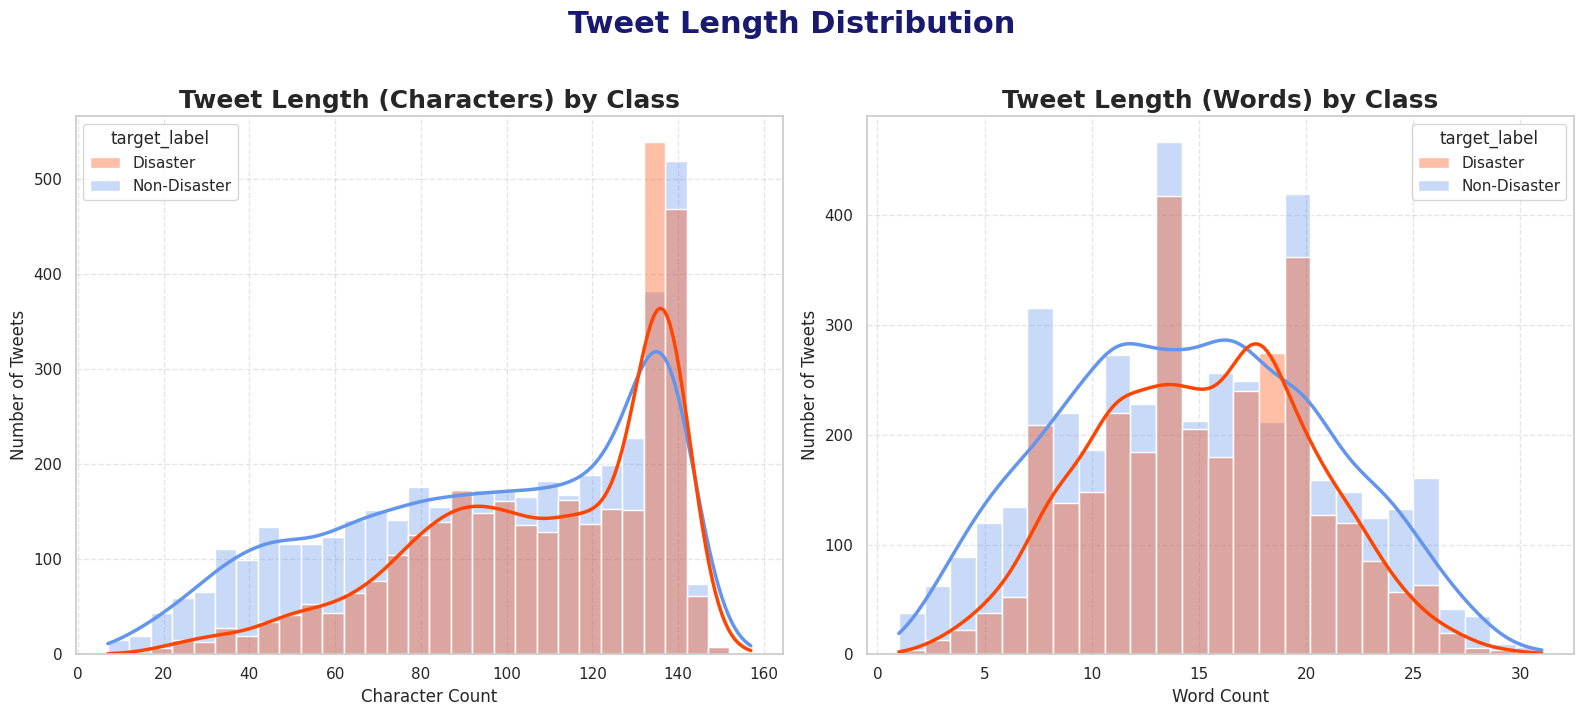

2026-10-12 18:01:23,417 - disaster_classification - INFO - Bivariate tweet length distribution analysis plotted


In [51]:
subsection_header("Bivariate Analysis — Tweet Length by Class")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Tweet Length Distribution",fontsize=22,fontweight="bold",y=1.02,color=PLOT_COLOR)
fig.subplots_adjust(wspace=0.28)

class_palette = {"Disaster": "orangered","Non-Disaster": "cornflowerblue"}

class_counts = df_refined["target_label"].value_counts()
sns.histplot(data=df_refined,x="char_count",hue="target_label",bins=30,kde=True,palette=class_palette,alpha=0.35,line_kws={"linewidth": 2.5},ax=axes[0])
axes[0].set_title("Tweet Length (Characters) by Class",fontweight="bold",fontsize=18)
axes[0].set_xlabel("Character Count")
axes[0].set_ylabel("Number of Tweets")
axes[0].grid(True, linestyle="--", alpha=0.5)

sns.histplot(data=df_refined,x="word_count",hue="target_label",bins=25,kde=True,palette=class_palette,alpha=0.35,line_kws={"linewidth": 2.5},ax=axes[1])
axes[1].set_title("Tweet Length (Words) by Class",fontweight="bold",fontsize=18)
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Number of Tweets")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("Assets/eda_bivariate_tweet_length_distribution.png",dpi=150,bbox_inches="tight")
plt.show()

logger.info("Bivariate tweet length distribution analysis plotted")


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Tweet Length Distribution (Characters & Words):**

- The character-count distributions show that both Disaster and Non-Disaster tweets have their strongest concentration near the upper end of the observed range, particularly around **130–145 characters**. However, the distributions differ at shorter lengths: Non-Disaster tweets are more broadly represented across the lower character ranges, while Disaster tweets show comparatively less density at very short lengths.
- A similar pattern appears in the word-count distributions. Disaster tweets are concentrated mainly around **15–20 words**, whereas Non-Disaster tweets show a broader spread across approximately **5–25 words**. There is nevertheless substantial overlap between the two classes, particularly in the **13–21 word** range.
- These distributions suggest that tweet length provides some class-related variation, but it does not clearly separate Disaster from Non-Disaster tweets.

*The differences indicate that tweet length may contribute additional information when combined with textual, sentiment, and other structural features.*

<hr style="width:45%; margin:auto;">

</div>


### 📌 Bivariate Analysis — Keyword vs. Target

<div style="margin-left: 20px; max-width: 90%">

Whether the top keywords actually split differently between Disaster and Non-Disaster tweets — not just how often each keyword appears overall (that was Univariate), but whether its appearance predicts the label.

</div>

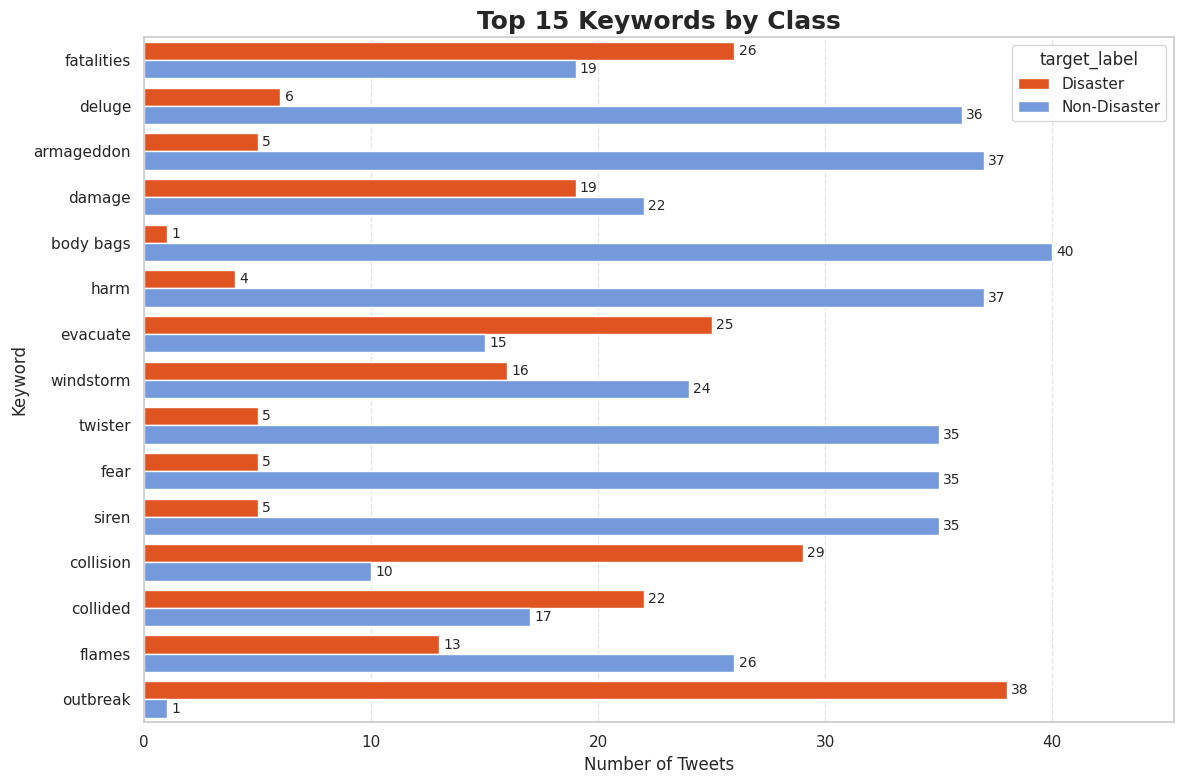

2026-10-12 18:01:48,377 - disaster_classification - INFO - Bivariate keyword-vs-target chart rendered


In [52]:
subsection_header("Bivariate Analysis — Keyword vs. Target")

top_kw_list = (df_refined[df_refined["keyword"] != "unknown"]["keyword"].value_counts().head(15).index)
kw_target = df_refined[df_refined["keyword"].isin(top_kw_list)]
target_palette = {"Disaster": "orangered", "Non-Disaster": "cornflowerblue"}

fig, ax = plt.subplots(figsize=(12, 8))
order = kw_target["keyword"].value_counts().index
sns.countplot(data=kw_target,y="keyword",hue="target_label",order=order,palette=target_palette,ax=ax,)
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10, fontweight="medium")

ax.set_xlim(0, ax.get_xlim()[1] * 1.08)
ax.set_title("Top 15 Keywords by Class", fontweight="bold", fontsize=18)
ax.set_xlabel("Number of Tweets")
ax.set_ylabel("Keyword")
ax.legend(title="target_label")
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("Assets/eda_bivariate_keyword_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Bivariate keyword-vs-target chart rendered")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Keyword vs. Target Class:**

- **Strong Disaster Signals:** Certain keywords are almost always tied to genuine emergencies. Most clearly, **`outbreak`** appears in **38 disaster tweets** and only **1 non-disaster tweet**, followed by **`collision`** (**29 disaster** vs. **10 non-disaster**) and **`evacuate`** (**25 disaster** vs. **15 non-disaster**).

*When these words appear, the tweet is very likely reporting a real event.*
- **Misleading Alarm Words:** Conversely, several dramatic-sounding words are used almost entirely in non-disaster contexts. **`body bags`** appears in **40 non-disaster tweets** compared to just **1 disaster tweet**, while words like **`armageddon`**, **`deluge`**, **`harm`**, **`twister`**, **`fear`**, and **`siren`** each have **35 or more non-disaster tweets** and 6 or fewer disaster tweets.

*People often use these terms casually for jokes, song lyrics, sports, or everyday exaggeration*.
- **Mixed and Ambiguous Words:** Words such as **`fatalities`** (**26 disaster**, **19 non-disaster**), **`damage`** (**19 disaster**, **22 non-disaster**), and **`collided`** (**22 disaster**, **17 non-disaster**) show a fairly even split, meaning the keyword alone cannot tell us whether the situation is real or not.

*The full sentence and surrounding context remain essential for separating genuine crisis updates from figurative everyday language.*

<hr style="width:45%; margin:auto;">

</div>

### 📌 Bivariate Analysis — Hashtag/URL/Mention Presence vs. Target

<div style="margin-left: 20px; max-width: 90%">

These three features are heavily zero-inflated (most tweets have none) — a boxplot collapses to nothing useful on data like that, the same pathology `hashtag_count` already showed in Univariate's IQR breakdown. Presence rate (% of tweets with at least one) is the honest comparison instead.

</div>

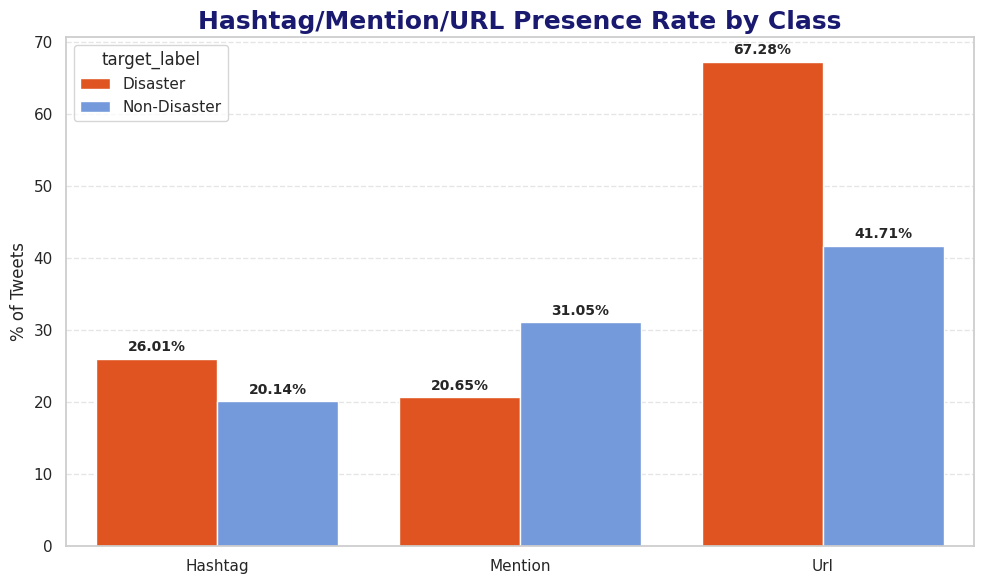

2026-10-12 18:02:43,420 - disaster_classification - INFO - Bivariate hashtag/mention/url presence-rate vs target rendered


In [53]:
subsection_header("Bivariate Analysis — Hashtag/URL/Mention Presence vs. Target")

presence = pd.DataFrame({"has_hashtag": df_refined["hashtag_count"] > 0,"has_mention": df_refined["mention_count"] > 0,"has_url": df_refined["url_count"] > 0,"target_label": df_refined["target_label"]})
long_presence = presence.melt(id_vars="target_label", var_name="feature", value_name="present")
presence_rate = long_presence.groupby(["feature", "target_label"], observed=True)["present"].mean().mul(100).reset_index()
presence_rate["feature"] = presence_rate["feature"].str.replace("has_", "").str.title()
target_palette = {"Disaster": "orangered", "Non-Disaster": "cornflowerblue"}

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=presence_rate, x="feature", y="present", hue="target_label", palette=target_palette, ax=ax)
ax.set_title("Hashtag/Mention/URL Presence Rate by Class", fontweight="bold", fontsize=18,color=PLOT_COLOR)
ax.set_ylabel("% of Tweets")
ax.set_xlabel("")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f%%", padding=3, fontweight="bold",fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("Assets/eda_bivariate_presence_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Bivariate hashtag/mention/url presence-rate vs target rendered")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Hashtag/Mention/URL Presence vs. Target:**

The three structural signals diverge in different directions.
- `url_count` shows the largest, clearest gap — **67.28%** of Disaster tweets contain a URL vs. **41.71%** of Non-Disaster tweets, a 25.6-point difference, consistent with genuine disaster reports linking to news articles or photo evidence.
- `mention_count` runs the opposite way — **31.05%** of Non-Disaster tweets contain a mention vs. only **20.65%** of Disaster tweets, plausibly because casual/conversational tweets (jokes, personal messages) tag people more often than urgent reports do.
- `hashtag_count` shows a smaller, same-direction gap as URLs (**26.01% vs. 20.14%**). None of these alone is a strong signal, but together — especially `url_count` — they add real, independent structural information beyond what the text content itself carries.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Bivariate Analysis — Sentiment vs. Target

<div style="margin-left: 20px; max-width: 90%">

Sentiment score and sentiment label, both against class — consistently as bar charts this time, not mixed with a boxplot.

</div>

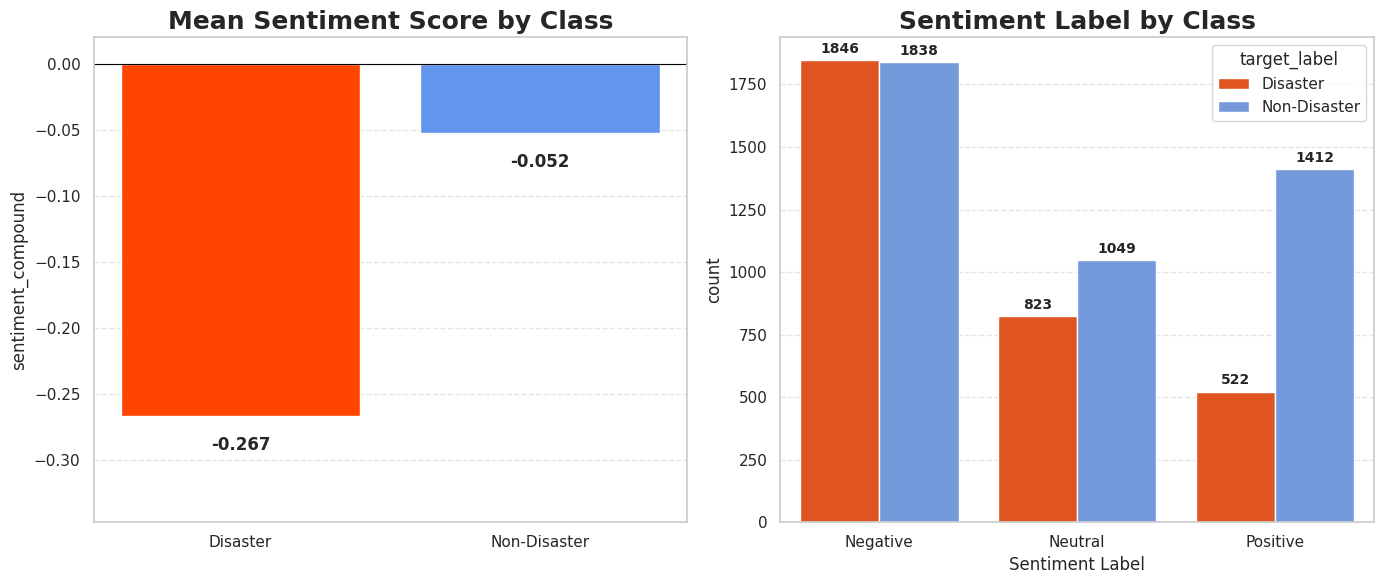

2026-10-12 18:03:43,413 - disaster_classification - INFO - Bivariate sentiment vs target rendered


In [55]:
subsection_header("Bivariate Analysis — Sentiment vs. Target")

target_palette = {"Disaster": "orangered", "Non-Disaster": "cornflowerblue"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

means = df_refined.groupby("target_label", observed=True)["sentiment_compound"].mean()
bars = axes[0].bar(means.index, means.values, color=[target_palette[t] for t in means.index])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Mean Sentiment Score by Class", fontweight="bold", fontsize=18)
axes[0].set_ylabel("sentiment_compound")
for bar, val in zip(bars, means.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val - (0.015 if val < 0 else -0.005), f"{val:.3f}",ha="center", va="top" if val < 0 else "bottom", fontweight="bold")
axes[0].set_ylim(means.min() * 1.3, 0.02)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].grid(False,axis="x")

sns.countplot(data=df_refined, x="sentiment_label", hue="target_label", palette=target_palette, ax=axes[1])
axes[1].set_title("Sentiment Label by Class", fontweight="bold", fontsize=18)
axes[1].set_xlabel("Sentiment Label")
for c in axes[1].containers:
    axes[1].bar_label(c, padding=3, fontsize=10, fontweight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("Assets/eda_bivariate_sentiment_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Bivariate sentiment vs target rendered")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Sentiment vs. Target:**

- **Mean sentiment score** is negative for both classes, but notably more negative for Disaster tweets (-0.267 vs. -0.052).
- **The sentiment label breakdown sharpens this**: within Disaster tweets, 57.9% are Negative and only 16.4% are Positive (522 of 3,191); within Non-Disaster tweets, Positive outnumbers Negative far less dramatically (32.8% vs. 42.8%). The clearest gap is in the Positive bucket specifically — Non-Disaster tweets are roughly 2x as likely to be scored Positive.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Bivariate Analysis — Disaster-Type vs. Target

<div style="margin-left: 20px; max-width: 90%">

Real-disaster rate within each disaster-type category — does the type of language used actually predict whether the tweet is genuine, or is it uniform across categories?

</div>

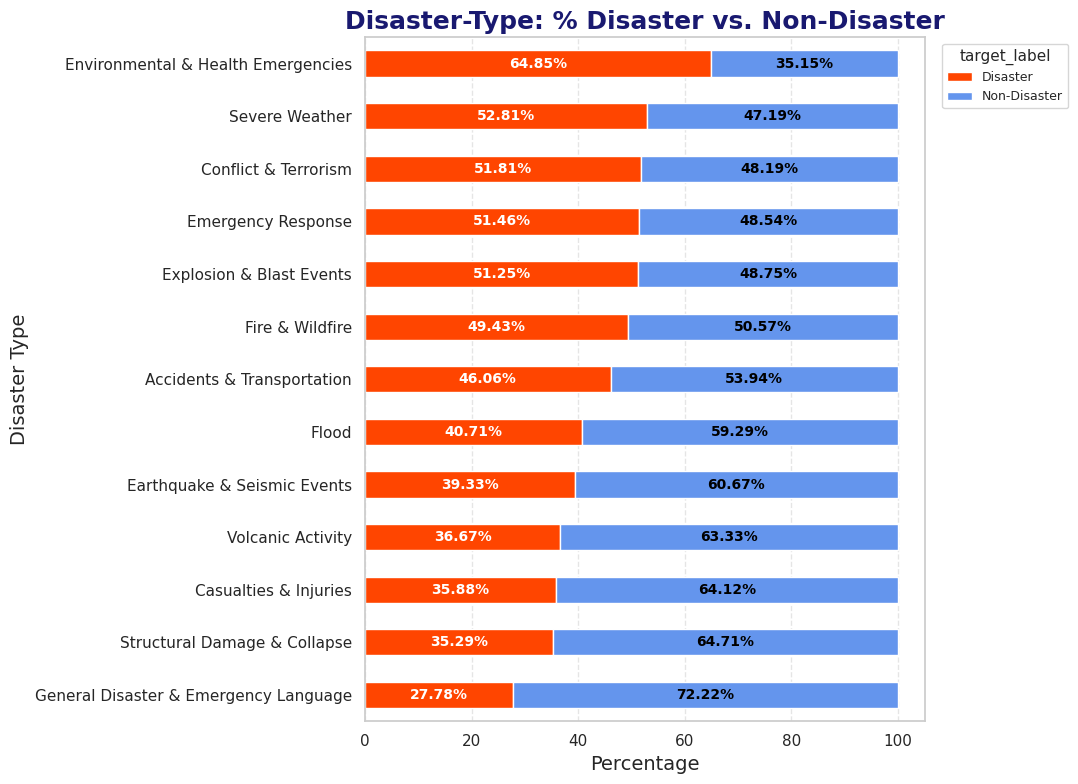

2026-10-12 18:04:02,268 - disaster_classification - INFO - Bivariate disaster_type vs target rendered — percentage labels added to stacked segments


In [56]:
subsection_header("Bivariate Analysis — Disaster-Type vs. Target")

dt_ct = (pd.crosstab(df_refined["disaster_type"].astype(str),df_refined["target_label"]).reindex(columns=["Disaster", "Non-Disaster"], fill_value=0))
dt_ct = (dt_ct.div(dt_ct.sum(axis=1), axis=0).mul(100))
dt_ct = dt_ct.sort_values("Disaster", ascending=True)

fig, ax = plt.subplots(figsize=(11, 8))
dt_ct.plot(kind="barh",stacked=True,color=["orangered", "cornflowerblue"],ax=ax)
ax.set_title("Disaster-Type: % Disaster vs. Non-Disaster",fontweight="bold",fontsize=18,color=PLOT_COLOR)
ax.set_xlabel("Percentage",fontsize=14)
ax.set_ylabel("Disaster Type",fontsize=14)
ax.tick_params(labelsize=11)
ax.grid(axis="x",linestyle="--",alpha=0.5)
ax.grid(False,axis="y")
ax.legend(title="target_label",title_fontsize=11,bbox_to_anchor=(1.02, 1),loc="upper left",fontsize=9)

for row_idx, category in enumerate(dt_ct.index):
    #Disaster Segment
    disaster_pct = dt_ct.loc[category, "Disaster"]
    ax.text(disaster_pct / 2,row_idx,f"{disaster_pct:.2f}%",ha="center",va="center",fontsize=10,fontweight="bold",color="white")
    #Non-Disaster segment
    non_disaster_pct = dt_ct.loc[category, "Non-Disaster"]
    ax.text(disaster_pct + (non_disaster_pct / 2),row_idx,f"{non_disaster_pct:.2f}%",ha="center",va="center",fontsize=10,fontweight="bold",color="black")

plt.tight_layout()
plt.savefig("Assets/eda_bivariate_disaster_type_vs_target.png",dpi=150,bbox_inches="tight")
plt.show()

logger.info("Bivariate disaster_type vs target rendered — percentage labels added to stacked segments")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Disaster-Type vs. Target:**

- Real-disaster rate varies meaningfully by category — from **64.85%** for `Environmental & Health Emergencies` down to just **27.78%** for `General Disaster & Emergency Language`, a 37-point spread.
- The top of the ranking (`Environmental & Health Emergencies`, `Severe Weather`, `Conflict & Terrorism`, `Emergency Response`, `Explosion & Blast Events`) all sit **above 51%** — these are categories where the underlying keywords tend towards genuine reports.
- The bottom of the ranking (`Casualties & Injuries`, `Structural Damage & Collapse`, and especially `General Disaster & Emergency Language` at **27.78%**) are dominated by Non-Disaster tweets.

*This confirms `disaster_type` carries real, non-uniform signal worth keeping as a model feature, not just a labeling convenience.*

<hr style="width:45%; margin:auto;">

</div>

### 📌 Bivariate Analysis — Sentiment vs. Tweet Length, by Class

<div style="margin-left: 20px; max-width: 90%">

Two continuous variables against each other, colored by class — the genuine scatter-plot case, since everything else so far has been categorical-involving.

</div>

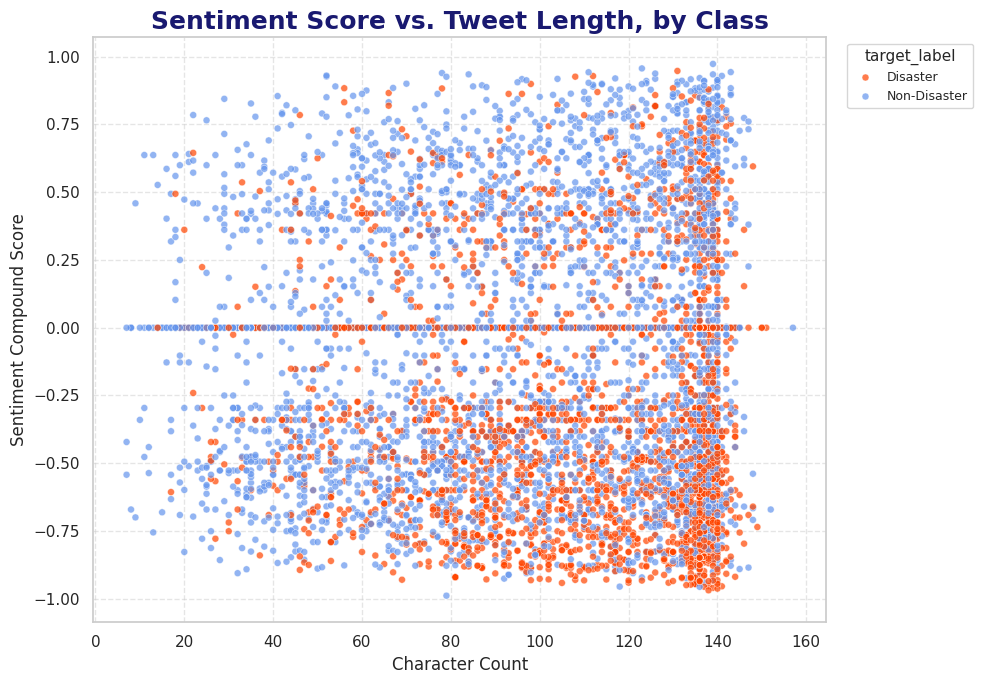

2026-10-12 18:04:26,317 - disaster_classification - INFO - Bivariate sentiment-vs-length scatter rendered


In [57]:
subsection_header("Bivariate Analysis — Sentiment vs. Tweet Length, by Class")

target_palette = {"Disaster": "orangered", "Non-Disaster": "cornflowerblue"}
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=df_refined, x="char_count", y="sentiment_compound", hue="target_label", palette=target_palette, alpha=0.7, s=25, ax=ax)
ax.set_title("Sentiment Score vs. Tweet Length, by Class", fontweight="bold", fontsize=18,color=PLOT_COLOR)
ax.set_xlabel("Character Count")
ax.set_ylabel("Sentiment Compound Score")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="target_label",title_fontsize=11,bbox_to_anchor=(1.02, 1),loc="upper left",fontsize=9)
plt.tight_layout()
plt.savefig("Assets/eda_bivariate_sentiment_length_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Bivariate sentiment-vs-length scatter rendered")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Sentiment vs. Tweet Length Scatter:**

The two classes overlap heavily across the full range of both variables.
- **Two patterns are still visible**: a dense horizontal band at `sentiment_compound = 0` running across all lengths (tweets VADER scores as perfectly neutral — short or sparse text), and Disaster tweets (orange) visibly concentrate more heavily in the negative-sentiment region (below 0), especially among longer tweets, while Non-Disaster (blue) dominates the positive region above 0.5.
- The lack of a clean separable boundary here is itself informative — it's exactly why this project needs the fuller NLP pipeline (vectorization, embeddings, and the DistilBERT tier) rather than relying on a handful of scalar features alone.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Multivariate Analysis — Correlation Heatmap

<div style="margin-left: 20px; max-width: 90%">

All 13 numeric features (post-treatment, capped values) plus `target` — one view of every pairwise relationship at once, including which features correlate with each other (redundancy) and which correlate with the label itself (signal).

</div>

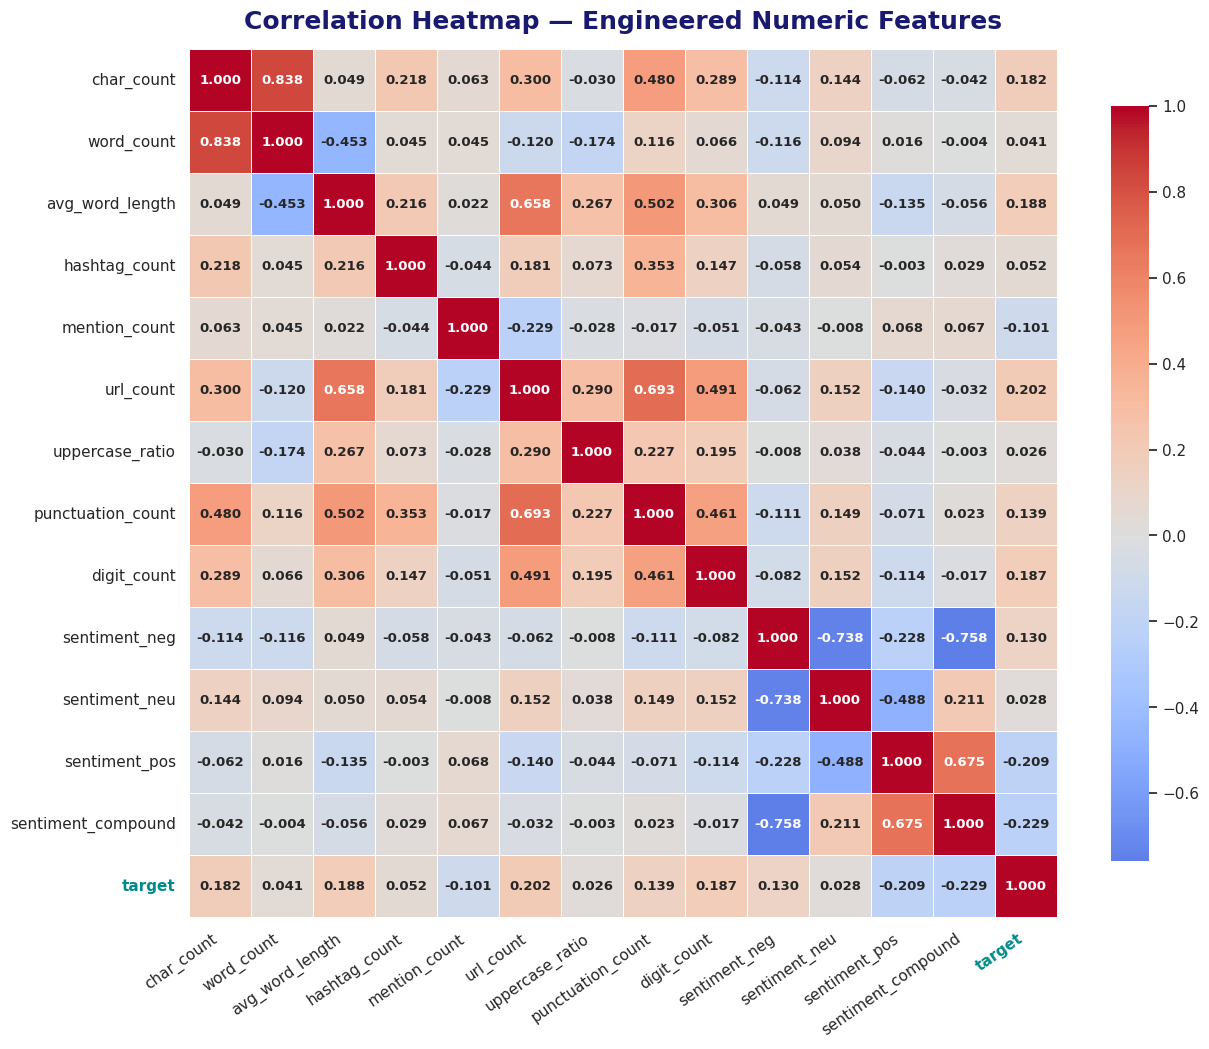

2026-10-12 18:04:58,309 - disaster_classification - INFO - Multivariate correlation heatmap rendered


In [58]:
subsection_header("Multivariate Analysis — Correlation Heatmap")

numeric_cols_corr = numeric_cols + ["target"]
corr = df_refined[numeric_cols_corr].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr,annot=True,fmt=".3f",annot_kws={"size": 9.5,"weight":"bold"},cmap="coolwarm",center=0,square=True,linewidths=0.5,cbar_kws={"shrink": 0.8},ax=ax)
ax.set_title("Correlation Heatmap — Engineered Numeric Features",fontweight="bold",fontsize=18,pad=15,color=PLOT_COLOR)
ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha="right",fontsize=11)
ax.set_yticklabels(ax.get_yticklabels(),fontsize=11)

target_color = "darkcyan"
for tick in ax.get_xticklabels():
    if tick.get_text() == "target":
        tick.set_color(target_color)
        tick.set_fontweight("bold")
for tick in ax.get_yticklabels():
    if tick.get_text() == "target":
        tick.set_color(target_color)
        tick.set_fontweight("bold")

plt.tight_layout()
plt.savefig("Assets/eda_multivariate_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Multivariate correlation heatmap rendered")

### 📌 Multivariate Analysis — Correlation with Target

<div style="margin-left: 20px; max-width: 90%">

Ranking each numeric feature by its correlation with the label, to see which engineered features carry the most signal.

</div>

In [59]:
subsection_header("Multivariate Analysis — Correlation with Target")

target_corr = corr["target"].drop("target").sort_values(ascending=False)
centered_table(target_corr.reset_index().rename(columns={"index": "feature", "target": "correlation_with_target"}))

logger.info("Multivariate correlation with target table rendered")

feature,correlation_with_target
url_count,0.2016
avg_word_length,0.1877
digit_count,0.1872
char_count,0.1820
punctuation_count,0.1390
sentiment_neg,0.1298
hashtag_count,0.0524
word_count,0.0407
sentiment_neu,0.0283
uppercase_ratio,0.0257


2026-10-12 18:05:11,805 - disaster_classification - INFO - Multivariate correlation with target table rendered


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Multivariate Correlation Analysis:**

- **Feature-to-feature multicollinearity**:

A few pairs are strongly correlated with each other, as expected from how they were engineered — `char_count`/`word_count` (0.838, both measure length), `sentiment_neg`/`sentiment_compound` (-0.758) and `sentiment_pos`/`sentiment_compound` (0.675), and `url_count`/`punctuation_count` (0.693, URLs themselves contain punctuation characters).

*None of this is a data problem — it's structurally expected.*

- **Feature-to-target correlation**:

Every single feature correlates weakly with `target` individually — the strongest, `sentiment_compound`, reaches only -0.229, and `url_count` leads the positive direction at 0.202.

The direction of each correlation is sensible and consistent with the Bivariate findings — `sentiment_compound`/`sentiment_pos` negative (more positive tone → less likely genuine disaster), `url_count`/`char_count`/`digit_count` positive (more structured, detail-bearing tweets → more likely genuine).

<hr style="width:45%; margin:auto;">

</div>

### 📌 Multivariate Analysis — N-Gram Frequency by Class

<div style="margin-left: 20px; max-width: 90%">

N-gram analysis examines frequently occurring sequences of **two words (bigrams)** and **three words (trigrams)** within the cleaned tweet text.

The analysis is performed separately for the **Disaster** and **Non-Disaster** classes to identify recurring lexical patterns that distinguish the two groups.

Because n-grams capture short sequences of words rather than isolated terms, they provide additional context about how disaster-related and non-disaster language is expressed in the tweets.

</div>


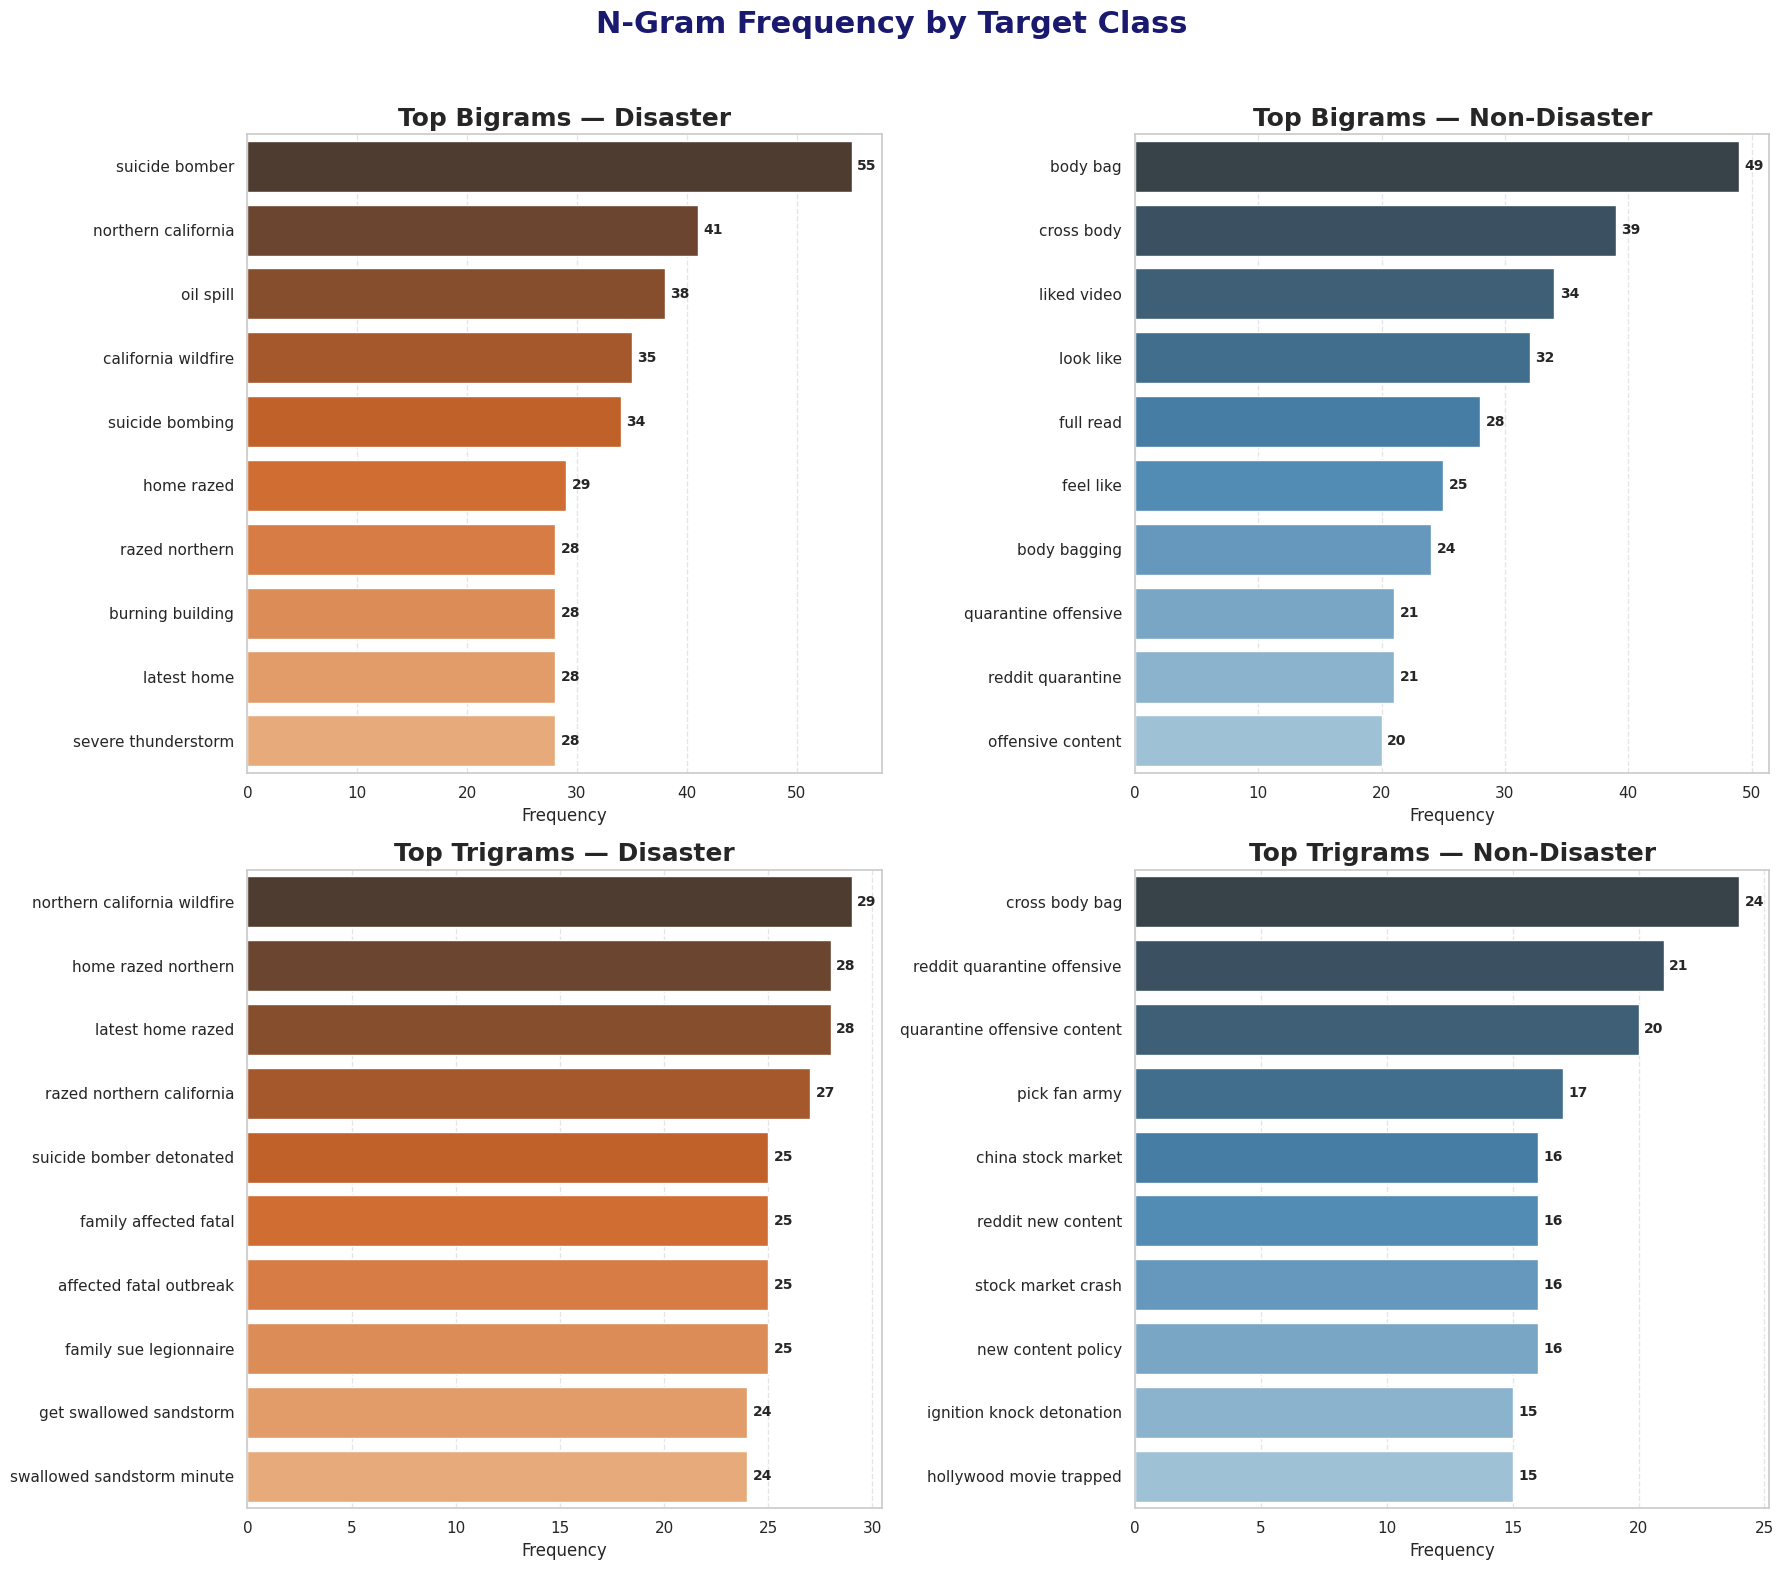

2026-10-12 18:06:00,299 - disaster_classification - INFO - Multivariate n-gram analysis rendered — top n-grams displayed in descending frequency order


In [60]:
subsection_header("Multivariate Analysis — N-Gram Frequency by Class")

def get_top_ngrams_by_class(data,text_col,target_col,target_value,ngram_range,top_n=10):
    class_text = (data.loc[data[target_col] == target_value,text_col].fillna("").astype(str))
    vectorizer = CountVectorizer(ngram_range=ngram_range,token_pattern=r"(?u)\b\w+\b")
    matrix = vectorizer.fit_transform(class_text)
    frequencies = matrix.sum(axis=0).A1
    ngrams = vectorizer.get_feature_names_out()
    result = pd.DataFrame({"ngram": ngrams,"frequency": frequencies})
    return (result.sort_values("frequency",ascending=False).head(top_n))


disaster_bigrams = get_top_ngrams_by_class(df_refined,"text_clean","target_label","Disaster",(2, 2),top_n=10)
non_disaster_bigrams = get_top_ngrams_by_class(df_refined,"text_clean","target_label","Non-Disaster",(2, 2),top_n=10)

disaster_trigrams = get_top_ngrams_by_class(df_refined,"text_clean","target_label","Disaster",(3, 3),top_n=10)
non_disaster_trigrams = get_top_ngrams_by_class(df_refined,"text_clean","target_label","Non-Disaster",(3, 3),top_n=10)

fig, axes = plt.subplots(2,2,figsize=(18, 16))
fig.suptitle("N-Gram Frequency by Target Class",fontsize=22,fontweight="bold",color=PLOT_COLOR,y=0.98)

disaster_palette = sns.color_palette("Oranges_d",10)
non_disaster_palette = sns.color_palette("Blues_d",10)

plot_specs = [
    (axes[0, 0],disaster_bigrams,"Top Bigrams — Disaster",disaster_palette),
    (axes[0, 1],non_disaster_bigrams,"Top Bigrams — Non-Disaster",non_disaster_palette),
    (axes[1, 0],disaster_trigrams,"Top Trigrams — Disaster",disaster_palette),
    (axes[1, 1],non_disaster_trigrams,"Top Trigrams — Non-Disaster",non_disaster_palette)]

for ax, data, title, palette in plot_specs:
    sns.barplot(data=data,x="frequency",y="ngram",hue="ngram",palette=palette[::-1],legend=False,ax=ax)
    ax.set_title(title,fontsize=18,fontweight="bold")
    ax.set_xlabel("Frequency")
    ax.set_ylabel("")
    ax.grid(axis="x",linestyle="--",alpha=0.5)
    for c in ax.containers:
        ax.bar_label(c,fmt="%d",padding=4,fontsize=10,fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Assets/eda_multivariate_ngram_frequency_by_class.png",dpi=150,bbox_inches="tight")
plt.show()

logger.info("Multivariate n-gram analysis rendered — top n-grams displayed in descending frequency order")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — N-Gram Frequency by Target Class:**

- Among Disaster tweets, the most frequent bigram is **`suicide bomber` (55 occurrences)**, followed by **`northern california` (41)**, **`oil spill` (38)**, and **`california wildfire` (35)**. These combinations are strongly associated with specific emergency events, locations, and disaster-related situations.
- The Disaster trigrams provide even more contextual information. **`northern california wildfire` occurs 29 times**, while **`home razed northern`** and **`latest home razed`** each occur **28 times**. Other frequent combinations such as **`razed northern california` (27)** and **`suicide bomber detonated` (25)** show how multiple words combine to describe specific events or consequences.

*The "northern california" cluster specifically is not generic geography — the trigrams confirm it's tied to a real, trending event (the 2017 Northern California wildfire season), which is exactly the kind of context an isolated keyword or location field alone wouldn't capture.*
- The Non-Disaster's most frequent bigrams include **`body bag` (49)**, **`cross body` (39)**, **`liked video` (34)**, and **`look like` (32)**. The trigram distribution similarly contains phrases such as **`cross body bag` (24)**, **`reddit quarantine offensive` (21)**, and **`quarantine offensive content` (20)** — a recurring Reddit-related news topic (*the 2015 subreddit "quarantine" policy for offensive content*).
- The presence of a phrase such as **`body bag`** does not automatically indicate a Disaster tweet, since it is the most frequent bigram in the Non-Disaster class. The n-gram results therefore reinforce the importance of **context and word combinations rather than isolated keywords**.

*The multi-word patterns may provide useful complementary information to individual-word and structural features.*

<hr style="width:45%; margin:auto;">

</div>

In [61]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:#2E8B57;"><b>✅ Checkpoint: Exploratory Data Analysis Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        Univariate, Bivariate, and Multivariate analysis complete — class balance, structural/sentiment/keyword/location/disaster-type
        distributions, outlier treatment, cross-feature correlations, and n-gram patterns by class all examined.<br>
        No single scalar feature separates the classes cleanly — the next pass builds the text representations
        (vectorization, embeddings) that the models will actually train on.
    </p>
    <hr style="width:45%;">
</div>"""))

## 05. Text Representation & Keyword Extraction

This section builds and examines multiple complementary text representations rather than treating them as directly interchangeable methods.

The representations considered are:

- Bag of Words (BoW)
- TF-IDF
- TF-IDF with n-grams
- Word2Vec
- GloVe
- FastText
- YAKE

The purpose of this section is to construct these representations and document their characteristics. Their predictive performance will be assessed later during model selection and training.

### 📌 Vectorization — Bag of Words (BoW)

<div style="margin-left: 20px; max-width: 90%">

**Bag of Words (BoW)** — represents tweets using word occurrence counts.

The simplest vectorization: raw word-count vectors, capped to the 5,000 most frequent terms (`min_df=2` to drop singleton noise words).

</div>

In [62]:
subsection_header("Vectorization — Bag of Words (BoW)")

bow_vectorizer = CountVectorizer(max_features=5000, min_df=2)
X_bow = bow_vectorizer.fit_transform(df_refined["text_clean"])

sparsity = 1 - X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])
bow_summary = pd.DataFrame({
    "metric": ["Matrix shape", "Vocabulary size", "Sparsity", "Non-zero entries"],
    "value": [str(X_bow.shape), len(bow_vectorizer.vocabulary_), f"{sparsity:.4f}", f"{X_bow.nnz:,}"]})
centered_table(bow_summary)

success_box(f"BoW matrix built — <b>{X_bow.shape[0]:,} tweets × {X_bow.shape[1]:,} terms</b>, <b>{sparsity:.2%} sparse</b>.")
logger.info(f"BoW vectorization complete — shape={X_bow.shape}")

metric,value
Matrix shape,"(7490, 5000)"
Vocabulary size,5000
Sparsity,0.9986
Non-zero entries,"54,164"


2026-10-12 18:07:25,866 - disaster_classification - INFO - BoW vectorization complete — shape=(7490, 5000)


### 📌 Vectorization — TF-IDF

<div style="margin-left: 20px; max-width: 90%">

**TF-IDF** — weights words according to their importance within individual tweets and across the corpus.

It has same vocabulary cap as BoW, but weighted by inverse document frequency — common words across many tweets get downweighted, rarer/more distinctive words get upweighted. Direct comparison point against BoW.

</div>

In [63]:
subsection_header("Vectorization — TF-IDF")

tfidf_vectorizer = TfidfVectorizer(max_features=5000, min_df=2)
X_tfidf = tfidf_vectorizer.fit_transform(df_refined["text_clean"])

sparsity = 1 - X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1])
tfidf_summary = pd.DataFrame({
    "metric": ["Matrix shape", "Vocabulary size", "Sparsity", "Non-zero entries"],
    "value": [str(X_tfidf.shape), len(tfidf_vectorizer.vocabulary_), f"{sparsity:.4f}", f"{X_tfidf.nnz:,}"]})
centered_table(tfidf_summary)

success_box(f"TF-IDF matrix built — <b>{X_tfidf.shape[0]:,} tweets × {X_tfidf.shape[1]:,} terms</b>, <b>{sparsity:.2%} sparse</b>.")
logger.info(f"TF-IDF vectorization complete — shape={X_tfidf.shape}")

metric,value
Matrix shape,"(7490, 5000)"
Vocabulary size,5000
Sparsity,0.9986
Non-zero entries,"54,164"


2026-10-12 18:08:23,059 - disaster_classification - INFO - TF-IDF vectorization complete — shape=(7490, 5000)


### 📌 Vectorization — TF-IDF with N-Grams

<div style="margin-left: 20px; max-width: 90%">

**TF-IDF with n-grams** — extends TF-IDF by capturing short word sequences such as bigrams, allowing the representation to retain limited phrase-level context.

It is directly motivated by the Multivariate n-gram analysis, which found genuine class-distinguishing signal in two-word phrases like "suicide bomber" and "northern california wildfire" that unigram-only TF-IDF would lose.

</div>

In [65]:
subsection_header("Vectorization — TF-IDF with N-Grams")

tfidf_ngram_vectorizer = TfidfVectorizer(max_features=5000, min_df=2, ngram_range=(1, 2))
X_tfidf_ngram = tfidf_ngram_vectorizer.fit_transform(df_refined["text_clean"])

sparsity = 1 - X_tfidf_ngram.nnz / (X_tfidf_ngram.shape[0] * X_tfidf_ngram.shape[1])
bigram_terms = [t for t in tfidf_ngram_vectorizer.vocabulary_ if " " in t]

ngram_summary = pd.DataFrame({
    "metric": ["Matrix shape", "Vocabulary size", "Sparsity", "Bigram terms in vocab"],
    "value": [str(X_tfidf_ngram.shape), len(tfidf_ngram_vectorizer.vocabulary_), f"{sparsity:.4f}", len(bigram_terms)]})
centered_table(ngram_summary)

success_box(f"TF-IDF+bigrams matrix built — <b>{X_tfidf_ngram.shape[0]:,} tweets × {X_tfidf_ngram.shape[1]:,} terms</b>, <b>{len(bigram_terms):,}</b> of which are bigrams.")
logger.info(f"TF-IDF+n-grams vectorization complete — shape={X_tfidf_ngram.shape}")

metric,value
Matrix shape,"(7490, 5000)"
Vocabulary size,5000
Sparsity,0.9983
Bigram terms in vocab,1651


2026-10-12 18:09:26,926 - disaster_classification - INFO - TF-IDF+n-grams vectorization complete — shape=(7490, 5000)


### 📌 Vectorization — Word2Vec

<div style="margin-left: 20px; max-width: 90%">

**Word2Vec** — produces dense word embeddings that capture distributional relationships between words.

Trained from scratch on this corpus (not pretrained) — 100-dimensional dense embeddings, averaged per tweet across its tokens.

</div>

In [66]:
subsection_header("Vectorization — Word2Vec")

w2v_model = Word2Vec(sentences=df_refined["tokens"].tolist(), vector_size=100, window=5, min_count=2, workers=4, seed=42)

def average_vector(tokens, model, dim=100):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(dim)

X_w2v = np.vstack(df_refined["tokens"].apply(lambda t: average_vector(t, w2v_model)))

zero_rows = int((X_w2v.sum(axis=1) == 0).sum())
w2v_summary = pd.DataFrame({
    "metric": ["Matrix shape", "Vocabulary size", "Embedding dim", "Tweets with no known words"],
    "value": [str(X_w2v.shape), len(w2v_model.wv.index_to_key), w2v_model.vector_size, zero_rows]})
centered_table(w2v_summary)

success_box(f"Word2Vec embeddings built — <b>{X_w2v.shape[0]:,} tweets × {X_w2v.shape[1]} dims</b>, trained vocabulary of <b>{len(w2v_model.wv.index_to_key):,} words</b>.")
logger.info(f"Word2Vec vectorization complete — shape={X_w2v.shape}, zero_vector_rows={zero_rows}")

metric,value
Matrix shape,"(7490, 100)"
Vocabulary size,5583
Embedding dim,100
Tweets with no known words,9


2026-10-12 18:10:24,044 - disaster_classification - INFO - Word2Vec vectorization complete — shape=(7490, 100), zero_vector_rows=9


### 📌 Embedding — GloVe

<div style="margin-left: 20px; max-width: 90%">

**GloVe** (Global Vectors for Word Representation) represents words as dense numerical vectors learned from global word co-occurrence patterns.

A pretrained **25-dimensional GloVe model trained on Twitter text** is used to provide a representation suited to the social-media domain. Tweet-level embeddings are created by averaging the available GloVe word vectors for each tweet.

</div>


In [67]:
subsection_header("Embedding — GloVe")

# Load pretrained GloVe Twitter embeddings
glove_model = api.load("glove-twitter-25")
GLOVE_DIM = glove_model.vector_size

# Create tweet-level average GloVe vectors
def average_glove_vector(tokens, model, dim=25):
    vectors = [model[word] for word in tokens if word in model]
    return (np.mean(vectors, axis=0) if vectors else np.zeros(dim))

X_glove = np.vstack(df_refined["tokens"].apply(lambda tokens: average_glove_vector(tokens,glove_model,GLOVE_DIM)))

# Validation
glove_zero_rows = int((X_glove.sum(axis=1) == 0).sum())

# Summary
glove_summary = pd.DataFrame({
    "metric": ["Matrix shape","Vocabulary size","Embedding dim","Tweets with no known words"],
    "value": [str(X_glove.shape),len(glove_model.index_to_key),GLOVE_DIM,glove_zero_rows]})

centered_table(glove_summary)
success_box(f"GloVe embeddings built — <b>{X_glove.shape[0]:,} tweets × {X_glove.shape[1]} dims</b>, pretrained Twitter vocabulary of <b>{len(glove_model.index_to_key):,} words</b/>.")
logger.info(f"GloVe embedding complete — shape={X_glove.shape}, zero_vector_rows={glove_zero_rows}")

[==================================================] 100.0% 104.8/104.8MB downloaded


metric,value
Matrix shape,"(7490, 25)"
Vocabulary size,1193514
Embedding dim,25
Tweets with no known words,3


2026-10-12 18:18:24,102 - disaster_classification - INFO - GloVe embedding complete — shape=(7490, 25), zero_vector_rows=3


### 📌 Embedding — FastText

<div style="margin-left: 20px; max-width: 90%">

**FastText** — produces embeddings using subword information, which can be useful for short and noisy social-media text. This allows the model to capture similarities between words that share character patterns and provides greater robustness to uncommon or previously unseen word forms.

A **100-dimensional FastText model** is trained on the cleaned tweet corpus, and tweet-level representations are created by averaging the word vectors for each tweet.

</div>


In [68]:
subsection_header("Embedding — FastText")

# Train FastText on the cleaned tweet corpus
fasttext_model = FastText(sentences=df_refined["tokens"].tolist(),vector_size=100,window=5,min_count=2,workers=4,sg=1,epochs=10,seed=42)

# Create tweet-level average FastText vectors
def average_fasttext_vector(tokens, model, dim=100):
    vectors = [model.wv[word] for word in tokens if word.strip()]
    return (np.mean(vectors, axis=0) if vectors else np.zeros(dim))

X_fasttext = np.vstack(df_refined["tokens"].apply(lambda tokens: average_fasttext_vector(tokens,fasttext_model,100)))

# Validation
fasttext_zero_rows = int((X_fasttext.sum(axis=1) == 0).sum())

# Summary
fasttext_summary = pd.DataFrame({
    "metric": ["Matrix shape","Vocabulary size","Embedding dim","Tweets with no tokens"],
    "value": [str(X_fasttext.shape),len(fasttext_model.wv.index_to_key),fasttext_model.vector_size,fasttext_zero_rows]})

centered_table(fasttext_summary)
success_box(f"FastText embeddings built — <b>{X_fasttext.shape[0]:,} tweets × {X_fasttext.shape[1]} dims</b>, trained vocabulary of <b>{len(fasttext_model.wv.index_to_key):,} words</b>.")
logger.info(f"FastText embedding complete — shape={X_fasttext.shape}, zero_vector_rows={fasttext_zero_rows}")

metric,value
Matrix shape,"(7490, 100)"
Vocabulary size,5583
Embedding dim,100
Tweets with no tokens,2


2026-10-12 18:21:22,203 - disaster_classification - INFO - FastText embedding complete — shape=(7490, 100), zero_vector_rows=2


### 📌 Keyword Extraction — YAKE

<div style="margin-left: 20px; max-width: 90%">

**YAKE** (Yet Another Keyword Extractor) identifies important keywords and keyphrases from individual texts using statistical features derived from the text itself.

The method is applied independently to each cleaned tweet to extract the **top five candidate keywords or keyphrases**. Unlike BoW, TF-IDF, and word embeddings, YAKE produces an interpretable set of important terms rather than a numerical vector representation.

</div>


In [70]:
subsection_header("Keyword Extraction — YAKE")

# Configure YAKE
yake_extractor = KeywordExtractor(lan="en",n=3,dedupLim=0.9,top=5,features=None)

# Extract keywords for each tweet
def extract_yake_keywords(text):
    text = str(text).strip()
    if not text:
        return []
    keywords = yake_extractor.extract_keywords(text)
    return [keyword for keyword, score in keywords]

df_refined["yake_keywords"] = (df_refined["text_clean"].apply(extract_yake_keywords))

# Validation
yake_keyword_counts = (df_refined["yake_keywords"].apply(len))
yake_summary = pd.DataFrame({
    "metric": ["Tweets processed","Average keywords per tweet","Median keywords per tweet","Tweets with no extracted keywords"],
    "value": [len(df_refined),f"{yake_keyword_counts.mean():.2f}",f"{yake_keyword_counts.median():.0f}",int((yake_keyword_counts == 0).sum())]})

centered_table(yake_summary)
success_box(f"YAKE keyword extraction complete — <b>{len(df_refined):,} tweets</b> processed, up to 5 keywords/keyphrases extracted per tweet.")
logger.info(f"YAKE keyword extraction complete — tweets_processed={len(df_refined):,}")

metric,value
Tweets processed,7490
Average keywords per tweet,4.80
Median keywords per tweet,5
Tweets with no extracted keywords,11


2026-10-12 18:27:46,235 - disaster_classification - INFO - YAKE keyword extraction complete — tweets_processed=7,490


### 📌 Representation Summary

The text representations developed in this section provide complementary ways of converting tweet text into machine-readable information.

BoW, TF-IDF, and TF-IDF with n-grams are sparse lexical representations, while Word2Vec, GloVe, and FastText provide dense semantic representations. YAKE is treated separately because it extracts keywords and keyphrases rather than producing a directly comparable numeric feature matrix.

The summary below documents the structural characteristics of each representation. Predictive performance is intentionally not compared at this stage; that comparison will be conducted later using a controlled modelling and evaluation protocol.

In [71]:
subsection_header("Representation Summary")

representation_summary = pd.DataFrame({
    "Representation": ["Bag of Words","TF-IDF","TF-IDF + N-Grams","Word2Vec","GloVe","FastText","YAKE"],
    "Type": ["Sparse vectorization","Sparse vectorization","Sparse vectorization","Dense embedding","Dense embedding","Dense embedding","Keyword extraction"],
    "Dimensions / Output": [f"{X_bow.shape[1]:,}",f"{X_tfidf.shape[1]:,}",f"{X_tfidf_ngram.shape[1]:,}",f"{X_w2v.shape[1]:,}",f"{X_glove.shape[1]:,}",f"{X_fasttext.shape[1]:,}","Up to 5 keyphrases"],
    "Sparse / Dense": ["Sparse","Sparse","Sparse","Dense","Dense","Dense","Text output"],
    "Vocabulary / Coverage": [f"{len(bow_vectorizer.vocabulary_):,}",f"{len(tfidf_vectorizer.vocabulary_):,}",f"{len(tfidf_ngram_vectorizer.vocabulary_):,}",f"{len(w2v_model.wv.index_to_key):,}",f"{len(glove_model.index_to_key):,}",f"{len(fasttext_model.wv.index_to_key):,}",f"{df_refined['yake_keywords'].apply(len).mean():.2f} keywords/tweet"]})

centered_table(representation_summary)
success_box("Text representation stage completed — six numeric representations and YAKE keyword extraction are available for downstream modelling and feature construction.")
logger.info("Representation summary completed — BoW, TF-IDF, TF-IDF+n-grams, Word2Vec, GloVe, FastText and YAKE documented.")

Representation,Type,Dimensions / Output,Sparse / Dense,Vocabulary / Coverage
Bag of Words,Sparse vectorization,"5,000",Sparse,"5,000"
TF-IDF,Sparse vectorization,"5,000",Sparse,"5,000"
TF-IDF + N-Grams,Sparse vectorization,"5,000",Sparse,"5,000"
Word2Vec,Dense embedding,100,Dense,"5,583"
GloVe,Dense embedding,25,Dense,"1,193,514"
FastText,Dense embedding,100,Dense,"5,583"
YAKE,Keyword extraction,Up to 5 keyphrases,Text output,4.80 keywords/tweet


2026-10-12 18:31:10,978 - disaster_classification - INFO - Representation summary completed — BoW, TF-IDF, TF-IDF+n-grams, Word2Vec, GloVe, FastText and YAKE documented.


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Text Representation & Keyword Extraction:**

- BoW, TF-IDF, and TF-IDF with n-grams each produced 5,000-dimensional sparse matrices, with the n-gram representation extending standard TF-IDF by incorporating both individual words and two-word sequences. The TF-IDF n-gram representation contained 1,651 bigram features within its 5,000-feature limit.
- Word2Vec generated 100-dimensional tweet-level vectors using a corpus vocabulary of 5,583 words, while FastText also produced 100-dimensional vectors from the same corpus vocabulary while incorporating subword information.
- GloVe used pretrained Twitter embeddings with 25 dimensions and a substantially larger pretrained vocabulary of 1,193,514 words.

*The sparse and dense approaches therefore provide complementary representations rather than identical alternatives.*

- YAKE was applied separately to extract important keywords and keyphrases from individual tweets, producing an average of 4.80 keywords per tweet. Unlike the vectorization and embedding approaches, YAKE produces extracted textual keywords rather than a directly comparable numeric feature matrix.

*No single representation is selected as the overall winner at this stage.*

<hr style="width:45%; margin:auto;">

</div>

In [72]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:#2E8B57;"><b>✅ Checkpoint: Text Representation Stage Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        BoW, TF-IDF, TF-IDF with n-grams, Word2Vec, GloVe, FastText and YAKE have been
        constructed and structurally documented for the refined dataset of
        <b>{df_refined.shape[0]:,} tweets</b>.<br>
        The next checkpoint reviews the dataset fields and their intended modelling roles
        before supervised modelling begins.
    </p>
    <hr style="width:45%;">
</div>
"""))


## 📌 Model-Ready Dataset Checkpoint

Before supervised modelling, the refined dataset is reviewed to define the feature set that will be used for prediction. This checkpoint separates the target, engineered numeric features, categorical source fields, and text/NLP fields, while also verifying missing values and duplicate rows.

The checkpoint establishes the modelling schema without fitting model-dependent transformations. Learned representations and categorical encoders are fitted only after the train/test split so that information from the held-out test set is not used during model preparation.


In [73]:
section_header("Model-Ready Dataset Checkpoint")
subsection_header("Dataset Overview")

# Create a modelling checkpoint without modifying the original refined dataset
df_modelling = df_refined.copy()

# Identify target column
target_candidates = ["target","label","disaster","disaster_label","target_class","class"]
target_col = next((col for col in target_candidates if col in df_modelling.columns),None)

# Text / NLP fields that require specialised processing
text_cols = [col for col in ["text", "text_clean", "tokens", "yake_keywords"] if col in df_modelling.columns]

# Numeric columns
numeric_cols = df_modelling.select_dtypes(include=[np.number]).columns.tolist()
LEAKAGE_COLS = ["id", "target_label"]
numeric_cols = [c for c in numeric_cols if c != target_col and c not in LEAKAGE_COLS]

# Categorical columns
categorical_cols = df_modelling.select_dtypes(include=["object", "category"]).columns.tolist()
categorical_cols = [c for c in categorical_cols if c != target_col and c not in text_cols and c not in LEAKAGE_COLS]

# Identify columns that can safely be used for duplicate checking
hashable_cols = []

for col in df_modelling.columns:
    try:
        df_modelling[col].map(hash).head()
        hashable_cols.append(col)
    except TypeError:
        pass

# Check duplicates using hashable columns only
if hashable_cols:
    duplicate_rows = df_modelling[[c for c in hashable_cols if c != "id"]].duplicated().sum()
else:
    duplicate_rows = 0

# Missing values
missing_cells = int(df_modelling.isna().sum().sum())

# Build dataset-level checkpoint summary
checkpoint_summary = pd.DataFrame({
    "Check": ["Rows","Columns","Target column","Numeric feature columns","Categorical columns","Text / NLP columns","Missing-value cells","Duplicate rows"],
    "Value": [f"{df_modelling.shape[0]:,}",f"{df_modelling.shape[1]:,}",target_col if target_col else "Not identified",f"{len(numeric_cols):,}",f"{len(categorical_cols):,}",f"{len(text_cols):,}",f"{missing_cells:,}",f"{duplicate_rows:,}"]})

centered_table(checkpoint_summary)
logger.info(f"Dataset structure checkpoint completed — rows={df_modelling.shape[0]:,}, columns={df_modelling.shape[1]:,}")

Check,Value
Rows,"7,490"
Columns,25
Target column,target
Numeric feature columns,13
Categorical columns,4
Text / NLP columns,4
Missing-value cells,0
Duplicate rows,0


2026-10-12 18:36:47,575 - disaster_classification - INFO - Dataset structure checkpoint completed — rows=7,490, columns=25


### 📌 Feature-role Inventory & Dataset Preview

<div style="margin-left: 20px; max-width: 90%">

Assigning every column a modelling role (target, numeric, categorical, or text) and previewing the dataset that enters the split.

</div>

In [74]:
subsection_header("Feature-role Inventory")

# Build feature-role inventory
feature_inventory = pd.DataFrame({
    "Feature group": ["Target","Numeric engineered features","Categorical features","Text / NLP fields"],
    "Columns": [target_col if target_col else "Not identified",", ".join(numeric_cols) if numeric_cols else "None identified",", ".join(categorical_cols) if categorical_cols else "None identified",", ".join(text_cols) if text_cols else "None identified"],
    "Modelling treatment": ["Prediction target — excluded from input features","Already numeric — can be included after train/test split","Requires encoding after train/test split","Handled through appropriate text representation"]})

centered_table(feature_inventory)
logger.info(f"Feature inventory checkpoint completed — numeric={len(numeric_cols)}, categorical={len(categorical_cols)}, text_nlp={len(text_cols)}")

Feature group,Columns,Modelling treatment
Target,target,Prediction target — excluded from input features
Numeric engineered features,"char_count, word_count, avg_word_length, hashtag_count, mention_count, url_count, uppercase_ratio, punctuation_count, digit_count, sentiment_neg, sentiment_neu, sentiment_pos, sentiment_compound",Already numeric — can be included after train/test split
Categorical features,"location, location_source, sentiment_label, disaster_type",Requires encoding after train/test split
Text / NLP fields,"text, text_clean, tokens, yake_keywords",Handled through appropriate text representation


2026-10-12 18:54:51,361 - disaster_classification - INFO - Feature inventory checkpoint completed — numeric=13, categorical=4, text_nlp=4


In [75]:
subsection_header("Dataset Preview")
# Dataset preview
dataset_preview = df_modelling.head().copy()
centered_table(dataset_preview)

# Final checkpoint status
if missing_cells == 0 and duplicate_rows == 0:
    success_box("Model-readiness checkpoint completed — all dataset fields have been classified, with no missing values or duplicate rows detected.")
else:
    info_box("Model-readiness checkpoint completed — feature roles have been identified. Review the missing-value and duplicate-row counts before proceeding to the modelling protocol.")

if missing_cells > 0:
    logger.warning(f"Data quality check detected {missing_cells:,} missing-value cells.")
else:
    logger.info(f"Data quality checkpoint completed — missing_cells={missing_cells:,}, duplicate_rows={duplicate_rows:,}")

id,keyword,location,text,target,target_label,location_source,char_count,word_count,avg_word_length,hashtag_count,mention_count,url_count,uppercase_ratio,punctuation_count,digit_count,sentiment_neg,sentiment_neu,sentiment_pos,sentiment_compound,sentiment_label,disaster_type,tokens,text_clean,yake_keywords
1,unknown,unknown,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,Disaster,Unknown,69,13,4.3846,1,0,0,0.1449,1,0,0.0000,0.8510,0.1490,0.2732,Positive,Earthquake & Seismic Events,"[deed, reason, earthquake, may, allah, forgive]",deed reason earthquake may allah forgive,"[deed reason earthquake, deed reason, allah forgive, reason earthquake, earthquake may allah]"
4,unknown,Canada,Forest fire near La Ronge Sask. Canada,1,Disaster,Extracted,38,7,4.5714,0,0,0,0.1316,1,0,0.2860,0.7140,0.0000,-0.3400,Negative,Fire & Wildfire,"[forest, fire, near, la, ronge, sask, canada]",forest fire near la ronge sask canada,"[ronge sask canada, forest fire, sask canada, ronge sask, forest]"
5,unknown,unknown,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,Disaster,Unknown,133,22,5.0909,0,0,0,0.0150,3,0,0.0950,0.9050,0.0000,-0.2960,Negative,Emergency Response,"[resident, asked, shelter, place, notified, officer, evacuation, shelter, place, order, expected]",resident asked shelter place notified officer evacuation shelter place order expected,"[resident asked shelter, place order expected, notified officer evacuation, officer evacuation shelter, place notified officer]"
6,unknown,California,"13,000 people receive #wildfires evacuation orders in California",1,Disaster,Extracted,65,8,7.1250,1,0,0,0.0154,2,5,0.0000,1.0000,0.0000,0.0000,Neutral,Fire & Wildfire,"[people, receive, wildfire, evacuation, order, california]",people receive wildfire evacuation order california,"[people receive wildfire, evacuation order california, receive wildfire evacuation, wildfire evacuation order, people receive]"
7,unknown,Alaska,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,Disaster,Extracted,87,16,4.5000,2,0,0,0.0345,2,0,0.0000,1.0000,0.0000,0.0000,Neutral,Fire & Wildfire,"[got, sent, photo, ruby, alaska, smoke, wildfire, pours, school]",got sent photo ruby alaska smoke wildfire pours school,"[wildfire pours school, photo ruby alaska, ruby alaska smoke, alaska smoke wildfire, smoke wildfire pours]"


2026-10-12 18:56:26,535 - disaster_classification - INFO - Data quality checkpoint completed — missing_cells=0, duplicate_rows=0


In [76]:
display(HTML(f"""
<div style="text-align:center;margin-top:40px;margin-bottom:30px;">
    <h3 style="color:#2E8B57;"><b>✅ Checkpoint: Model-Ready Dataset Review Complete</b></h3>
    <p style="font-style:italic;font-size:1.05em;opacity:0.85;">
        Dataset fields have been classified into target, numeric, categorical and text/NLP
        roles, with <b>{missing_cells:,} missing-value</b> cells and <b>{duplicate_rows:,} duplicate</b> rows
        identified at this checkpoint.<br>
        Model-specific encoders, vectorizers and corpus-trained representations will be fitted
        only within the supervised modelling workflow after the dataset split.
    </p>
    <hr style="width:45%;">
</div>
"""))

## 06. Dataset Split & Modelling Protocol

This section defines the train/test split, cross-validation strategy, evaluation metrics, and leakage controls that will be applied throughout the subsequent modelling stages.

The test set will be held out from model development and used only for final evaluation. Any transformation that learns information from the data—including vectorizers, encoders, and corpus-trained embeddings—will be fitted using the training data only and then applied to the held-out data. Cross-validation and hyperparameter tuning will also be performed within the training set.


### 📌 Stratified Train/Test Split

<div style="margin-left: 20px; max-width: 90%">

Holding out a stratified test set with a fixed random state so that both splits keep the class balance. The test set is not used again until final evaluation.

</div>

In [77]:
subsection_header("Stratified Train/Test Split")

# Define target and modelling dataset
X = df_modelling.drop(columns=[target_col])
y = df_modelling[target_col]

# Create a stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,stratify=y,random_state=42)

# Summarise split
split_summary = pd.DataFrame({
    "Dataset": ["Full modelling dataset", "Training set", "Test set"],
    "Rows": [len(df_modelling),len(X_train),len(X_test)],
    "Percentage": ["100.0%",f"{len(X_train) / len(df_modelling):.1%}",f"{len(X_test) / len(df_modelling):.1%}"]})

centered_table(split_summary)
success_box(f"Stratified train/test split completed — {len(X_train):,} training rows and {len(X_test):,} held-out test rows.")
logger.info(f"Stratified train/test split completed — total={len(df_modelling):,}, train={len(X_train):,}, test={len(X_test):,}, test_size=20%, random_state=42")

Dataset,Rows,Percentage
Full modelling dataset,7490,100.0%
Training set,5992,80.0%
Test set,1498,20.0%


2026-10-12 18:59:03,536 - disaster_classification - INFO - Stratified train/test split completed — total=7,490, train=5,992, test=1,498, test_size=20%, random_state=42


### 📌 Leakage & Reproducibility Controls

<div style="margin-left: 20px; max-width: 90%">

Refitting each vectorizer on `X_train` only, transforming both splits with the train-fitted object, before any model sees this data.

</div>

In [78]:
subsection_header("Leakage & Reproducibility Controls")

# Re-fit every representation on X_train only
bow_vectorizer_train = CountVectorizer(max_features=5000, min_df=2).fit(X_train["text_clean"])
X_train_bow = bow_vectorizer_train.transform(X_train["text_clean"])
X_test_bow = bow_vectorizer_train.transform(X_test["text_clean"])

tfidf_vectorizer_train = TfidfVectorizer(max_features=5000, min_df=2).fit(X_train["text_clean"])
X_train_tfidf = tfidf_vectorizer_train.transform(X_train["text_clean"])
X_test_tfidf = tfidf_vectorizer_train.transform(X_test["text_clean"])

tfidf_ngram_vectorizer_train = TfidfVectorizer(max_features=5000, min_df=2, ngram_range=(1, 2)).fit(X_train["text_clean"])
X_train_tfidf_ngram = tfidf_ngram_vectorizer_train.transform(X_train["text_clean"])
X_test_tfidf_ngram = tfidf_ngram_vectorizer_train.transform(X_test["text_clean"])

w2v_model_train = Word2Vec(sentences=X_train["tokens"].tolist(), vector_size=100, window=5, min_count=2, workers=4, seed=42)
X_train_w2v = np.vstack(X_train["tokens"].apply(lambda t: average_vector(t, w2v_model_train)))
X_test_w2v = np.vstack(X_test["tokens"].apply(lambda t: average_vector(t, w2v_model_train)))

# GloVe — externally pretrained KeyedVectors.
def average_glove_vector(tokens, model, dim=25):
    vectors = [model[w] for w in tokens if w in model]
    return np.mean(vectors, axis=0) if vectors else np.zeros(dim)
X_train_glove = np.vstack(X_train["tokens"].apply(lambda t: average_glove_vector(t, glove_model, dim=25)))
X_test_glove = np.vstack(X_test["tokens"].apply(lambda t: average_glove_vector(t, glove_model, dim=25)))

fasttext_model_train = FastText(sentences=X_train["tokens"].tolist(), vector_size=100, window=5, min_count=2, workers=4, seed=42)
X_train_fasttext = np.vstack(X_train["tokens"].apply(lambda t: average_vector(t, fasttext_model_train)))
X_test_fasttext = np.vstack(X_test["tokens"].apply(lambda t: average_vector(t, fasttext_model_train)))

refit_summary = pd.DataFrame({
    "representation": ["BoW", "TF-IDF", "TF-IDF+n-grams", "Word2Vec", "GloVe (pretrained)", "FastText"],
    "train_shape": [str(X_train_bow.shape), str(X_train_tfidf.shape), str(X_train_tfidf_ngram.shape),str(X_train_w2v.shape), str(X_train_glove.shape), str(X_train_fasttext.shape)],
    "test_shape": [str(X_test_bow.shape), str(X_test_tfidf.shape), str(X_test_tfidf_ngram.shape),str(X_test_w2v.shape), str(X_test_glove.shape), str(X_test_fasttext.shape)]})

centered_table(refit_summary)
success_box("All representations refit on training data only — the full-dataset-fitted objects are not reused for modeling.")
logger.info("Leakage controls applied — all vectorizers/embeddings refit on X_train")

representation,train_shape,test_shape
BoW,"(5992, 4761)","(1498, 4761)"
TF-IDF,"(5992, 4761)","(1498, 4761)"
TF-IDF+n-grams,"(5992, 5000)","(1498, 5000)"
Word2Vec,"(5992, 100)","(1498, 100)"
GloVe (pretrained),"(5992, 25)","(1498, 25)"
FastText,"(5992, 100)","(1498, 100)"


2026-10-12 19:00:42,381 - disaster_classification - INFO - Leakage controls applied — all vectorizers/embeddings refit on X_train


### 📌 Categorical Feature Encoding

<div style="margin-left: 20px; max-width: 90%">

One-hot encoding `disaster_type` and `location_source` only — fit on `X_train`, applied to both splits, same leakage-safe principle as the representations. `keyword` is skipped (redundant with `disaster_type`, high overfitting risk at this sample size) and `sentiment_label` is skipped (redundant with the continuous sentiment scores already present).

</div>

In [79]:
subsection_header("Categorical Feature Encoding")

encode_cols = ["disaster_type", "location_source"]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
ohe.fit(X_train[encode_cols])

X_train_cat = ohe.transform(X_train[encode_cols])
X_test_cat = ohe.transform(X_test[encode_cols])

encoding_summary = pd.DataFrame({"column": encode_cols,"categories_seen_in_train": [len(c) for c in ohe.categories_]})
centered_table(encoding_summary)

success_box(f"<b>Encoded {len(encode_cols)} categorical columns</b> — <b>{X_train_cat.shape[1]} one-hot encoded</b> features created, fit on X_train only.")
logger.info(f"Categorical encoding complete — columns={encode_cols}, output_dim={X_train_cat.shape[1]}")

column,categories_seen_in_train
disaster_type,13
location_source,3


2026-10-12 19:01:50,070 - disaster_classification - INFO - Categorical encoding complete — columns=['disaster_type', 'location_source'], output_dim=16


### 📌 Modelling Feature Assembly

<div style="margin-left: 20px; max-width: 90%">

Combining the selected engineered numeric features with the one-hot categorical features into structured matrices, with matching dimensions for training and test data.

</div>

In [80]:
subsection_header("Modelling Feature Assembly")

# Selected engineered numeric features
model_numeric_cols = ["char_count","word_count","avg_word_length","hashtag_count","mention_count","url_count","uppercase_ratio","punctuation_count","digit_count","sentiment_neg","sentiment_neu","sentiment_pos","sentiment_compound"]

# Confirm that all selected numeric features are available
missing_model_numeric = [col for col in model_numeric_cols if col not in X_train.columns]

if missing_model_numeric:
    raise KeyError(f"Missing modelling features: {missing_model_numeric}")

# Assemble the engineered numeric + one-hot categorical feature matrices
X_train_numeric = X_train[model_numeric_cols].to_numpy()
X_test_numeric = X_test[model_numeric_cols].to_numpy()

X_train_structured = np.hstack([X_train_numeric,X_train_cat.toarray()])
X_test_structured = np.hstack([X_test_numeric,X_test_cat.toarray()])

assembly_summary = pd.DataFrame({
    "Feature group": ["Engineered numeric features","One-hot encoded categorical features","Combined structured features"],
    "Training dimensions": [str(X_train_numeric.shape),str(X_train_cat.shape),str(X_train_structured.shape)],
    "Test dimensions": [str(X_test_numeric.shape),str(X_test_cat.shape),str(X_test_structured.shape)]})

centered_table(assembly_summary)
success_box(f"Structured modelling features assembled — <b>{len(model_numeric_cols)} engineered</b> numeric features plus <b>{X_train_cat.shape[1]} one-hot encoded</b> categorical features.")
logger.info(f"Structured feature assembly completed — numeric_features={len(model_numeric_cols)}, categorical_encoded_features={X_train_cat.shape[1]}, train_shape={X_train_structured.shape}, test_shape={X_test_structured.shape}")

Feature group,Training dimensions,Test dimensions
Engineered numeric features,"(5992, 13)","(1498, 13)"
One-hot encoded categorical features,"(5992, 16)","(1498, 16)"
Combined structured features,"(5992, 29)","(1498, 29)"


2026-10-12 19:07:05,662 - disaster_classification - INFO - Structured feature assembly completed — numeric_features=13, categorical_encoded_features=16, train_shape=(5992, 29), test_shape=(1498, 29)


<div style="margin-left: 40px; max-width: 90%">

### **📊 Executive Summary — Dataset Split & Modelling Protocol:**

- The modelling dataset was divided into **5,992 training tweets (80%)** and **1,498 held-out test tweets (20%)** using a stratified split with a fixed random state of **42**.
- Corpus-dependent text representations were refitted using the **training data only**, while the resulting train-fitted representations were applied to both training and held-out test data.
- The externally pretrained **GloVe** representation was not refitted on the project corpus and was applied separately to the training and test tweets.
- The categorical variables `disaster_type` and `location_source` were transformed into **16 one-hot encoded features** using an encoder fitted exclusively on the training data.
- The selected engineered numeric features and one-hot encoded categorical features were assembled into structured modelling inputs while preserving consistent feature dimensions between the training and test sets.
- The held-out test set remains separate from model fitting and feature-learning decisions. The next stage will use the training data for **model selection, cross-validation and hyperparameter tuning**, with final test performance assessed only after the selected models have been established.

<hr style="width:45%; margin:auto;">

</div>


## 07. Model Selection & Training

<div style="margin-left: 40px; max-width: 90%">

This stage evaluates candidate disaster-tweet classifiers using training data only, with model selection guided by stratified cross-validation before the held-out test set is used for final evaluation.

### **Planned Models Overview**

| Model Name                                            | Model Family               | Scope & Strategic Intent                                                                                                                               |
| :---------------------------------------------------- | :------------------------- | :----------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Multinomial Naive Bayes**                           | Classical Text Baselines   | Fast probabilistic baseline using word-frequency information from sparse TF-IDF representations.                                                       |
| **Logistic Regression**                               | Classical Text Baselines   | Standard linear benchmark assessing class-separation patterns in high-dimensional sparse text representations.                                         |
| **Linear SVM**                                        | Classical Text Baselines   | Max-margin linear classifier designed for high-dimensional sparse text spaces.                                                                         |
| **Random Forest & LightGBM**                          | Dense Semantic Embeddings  | Tree-based classifiers applied to dense Word2Vec, GloVe, and FastText representations to evaluate semantic feature performance.                        |
| **Best Sparse-Tier Classifier + Engineered Features** | Feature-Enhanced Classical | Extends the strongest established sparse representation with numeric, categorical, and sentiment-based features to assess additional predictive value. |
| **Best Classifier + YAKE Keywords**                   | Keyword-Enhanced Modelling | Incorporates extracted YAKE keywords into an established feature representation to assess whether keyword information improves classification.         |
| **Bidirectional LSTM (BiLSTM)**                       | Neural Sequence Modelling  | Recurrent neural architecture that processes token sequences in both directions to capture sequential and contextual information.                      |
| **DistilBERT**                                        | Contextual Transformers    | Pre-trained transformer architecture using contextual representations and self-attention for tweet classification.                                     |

<br>

* Candidate models are compared using **stratified 5-fold cross-validation on the training data only**. The held-out test split remains untouched until final evaluation.

* **Primary selection metric:** **Accuracy**.

* **Secondary selection metric:** **F1 score**.

* **Supporting metrics:** **Precision**, **Recall**, and **CV F1** are retained to provide a broader view of classification performance and class-level behaviour.

* After a family winner is selected through cross-validation, that model is fitted on the full training set and retained as the family-level model for subsequent test evaluation.

* Hyperparameter tuning is applied only where it provides a meaningful modelling benefit and is restricted to the training data. The held-out test set is never used for model selection or tuning.

<hr style="width:45%; margin:auto;">

</div>


### 📌 Classical Baseline Models

<div style="margin-left: 20px; max-width: 90%">

Logistic Regression, Linear SVM and Multinomial Naive Bayes are compared on TF-IDF features. The vectorizer sits inside each pipeline, so it is refit within every cross-validation fold on training data only. The family winner is chosen by CV Accuracy, with CV F1 as the secondary criterion, then refit on the full training set and saved for reuse.

</div>

In [81]:
section_header("Model Selection & Training")
subsection_header("Classical Baseline Models")

cv_strategy = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000,random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
    "Multinomial Naive Bayes": MultinomialNB()}

CLASSICAL_RESULTS_NAME = "classical_baseline_results"
CLASSICAL_LOCAL_DIR = "Assets/models"
CLASSICAL_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)

required_result_columns = {"Model","CV Accuracy","CV Precision","CV Recall","CV F1"}
cached_artifact = load_latest_model_artifact(CLASSICAL_RESULTS_NAME,local_dir=CLASSICAL_LOCAL_DIR,drive_dir=CLASSICAL_DRIVE_DIR,framework="joblib")

use_cached_artifact = (
    isinstance(cached_artifact, dict)
    and "results" in cached_artifact
    and "best_model" in cached_artifact
    and "best_model_name" in cached_artifact
    and isinstance(cached_artifact["results"], pd.DataFrame)
    and required_result_columns.issubset(set(cached_artifact["results"].columns)))

if use_cached_artifact:
    baseline_results_df = cached_artifact["results"]
    best_baseline = cached_artifact["best_model_name"]
    best_classical_model = cached_artifact["best_model"]

    info_box("Loaded the existing classical baseline family artifact from the Local → Drive cascade. Retraining skipped.")
    logger.info(f"Loaded cached classical baseline artifact — best_model={best_baseline}")

else:
    baseline_results = {}
    for model_name, model in baseline_models.items():
        pipeline = Pipeline([("tfidf",TfidfVectorizer(max_features=5000,min_df=2)),("classifier",model)])
        cv_scores = cross_validate(pipeline,X_train["text_clean"].astype(str),y_train,cv=cv_strategy,scoring={"accuracy": "accuracy","precision": "precision","recall": "recall","f1": "f1"},n_jobs=-1,return_train_score=False)
        baseline_results[model_name] = {
            "Model": model_name,
            "CV Accuracy": cv_scores["test_accuracy"].mean(),
            "CV Precision": cv_scores["test_precision"].mean(),
            "CV Recall": cv_scores["test_recall"].mean(),
            "CV F1": cv_scores["test_f1"].mean()}

    baseline_results_df = (pd.DataFrame(baseline_results.values()).sort_values(by=["CV Accuracy", "CV F1"],ascending=[False, False]).reset_index(drop=True))
    best_baseline = baseline_results_df.iloc[0]["Model"]
    best_classical_model = Pipeline([("tfidf",TfidfVectorizer(max_features=5000,min_df=2)),("classifier",baseline_models[best_baseline])])

    # Fit the selected family winner on the complete training set.
    best_classical_model.fit(X_train["text_clean"].astype(str),y_train)

    # Store everything needed for future runs
    classical_artifact = {"results": baseline_results_df,"best_model_name": best_baseline,"best_model": best_classical_model}
    save_model_artifact(classical_artifact,CLASSICAL_RESULTS_NAME,local_dir=CLASSICAL_LOCAL_DIR,framework="joblib")

    success_box("Classical baseline candidates were compared using stratified cross-validation.\nThe selected family winner was fitted on the complete training set and serialized for future runs.")
    logger.info(f"Classical baseline artifact saved — best_model={best_baseline}, selection_metric=CV Accuracy")


# Display cross-validation results with metric highlights
display_df = baseline_results_df.copy()
metric_cols = ["CV Accuracy", "CV Precision", "CV Recall", "CV F1"]
pill_style = ("background-color: #1B5E20; color: #FFFFFF; font-weight: bold; padding: 3px 10px; border-radius: 12px; display: inline-block; white-space: nowrap;")

# Identify max values across each metric and format with green pill
for col in metric_cols:
    max_val = display_df[col].max()
    display_df[col] = display_df[col].apply(lambda v, mv=max_val: (f'<span style="{pill_style}">{v:.4f}</span>' if v == mv else f"{v:.4f}"))

# Render formatted table
centered_table(display_df)
best_baseline_row = baseline_results_df.iloc[0]
success_box(f"<b>Best classical baseline</b> by CV Accuracy: <b>{best_baseline_row['Model']}</b> (CV Accuracy=<b>{best_baseline_row['CV Accuracy']:.4f}</b>, CV F1=<b>{best_baseline_row['CV F1']:.4f}</b>).")
logger.info(f"Classical baseline results ready — best_model={best_baseline_row['Model']}, cv_accuracy={best_baseline_row['CV Accuracy']:.4f}, cv_f1={best_baseline_row['CV F1']:.4f}")

2026-10-12 19:25:08,186 - disaster_classification - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets/models/classical_baseline_results_20261007_204132.pkl
2026-10-12 19:25:08,399 - disaster_classification - INFO - Cached GitHub artifact locally: Assets/models/classical_baseline_results_20261007_204132.pkl


2026-10-12 19:25:08,563 - disaster_classification - INFO - Loaded cached classical baseline artifact — best_model=Logistic Regression


Model,CV Accuracy,CV Precision,CV Recall,CV F1
Logistic Regression,0.8041,0.8322,0.6769,0.7462
Multinomial Naive Bayes,0.8011,0.8279,0.6737,0.7424
Linear SVM,0.7810,0.7553,0.7199,0.7369


2026-10-12 19:25:08,603 - disaster_classification - INFO - Classical baseline results ready — best_model=Logistic Regression, cv_accuracy=0.8041, cv_f1=0.7462


<div style="margin-left: 40px; max-width: 90%">

💡 ****Interpretation — Classical Baseline Modelling:****

* The classical baseline models were compared using stratified cross-validation, with **CV Accuracy as the primary selection metric** and **CV F1 as the secondary metric**. Logistic Regression achieved the highest **CV Accuracy of 0.8041** and a **CV F1 of 0.7462**, making it the strongest classical baseline configuration.

* Multinomial Naive Bayes produced a closely comparable **CV Accuracy of 0.8011** and **CV F1 of 0.7424**, indicating that it performed similarly to Logistic Regression but remained slightly weaker on both primary selection measures.

* Linear SVM achieved a lower **CV Accuracy of 0.7810** and **CV F1 of 0.7369**. However, it produced the highest **CV Recall of 0.7199** among the three classical models, showing a stronger tendency to identify positive disaster tweets at the cost of lower overall accuracy and precision.

* Based on the predefined selection hierarchy, **Logistic Regression is selected as the classical family winner** and is fitted on the complete training set for subsequent test evaluation.

<hr style="width:45%; margin:auto;">

</div>


### 📌 Dense Embedding Models

<div style="margin-left: 20px; max-width: 90%">

Random Forest and LightGBM are compared on averaged tweet vectors from pretrained GloVe and from Word2Vec and FastText trained on the training tokens only. Selection uses stratified cross-validation on the training data; the winner is refit on the full training set and saved together with its feature columns.

</div>

In [82]:
subsection_header("Dense Embedding Models")

cv_strategy = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
embedding_sets = {
    "GloVe": (X_train_glove,X_test_glove),
    "Word2Vec": (X_train_w2v,X_test_w2v),
    "FastText": (X_train_fasttext,X_test_fasttext)}

DENSE_RESULTS_NAME = "dense_embedding_results"
DENSE_LOCAL_DIR = "Assets/models"
DENSE_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)

required_result_columns = {"Model","Embedding","Classifier","CV Accuracy","CV Precision","CV Recall","CV F1"}
cached_artifact = load_latest_model_artifact(DENSE_RESULTS_NAME,local_dir=DENSE_LOCAL_DIR,drive_dir=DENSE_DRIVE_DIR,framework="joblib")
use_cached_artifact = (
    isinstance(cached_artifact, dict)
    and "results" in cached_artifact
    and "best_model" in cached_artifact
    and "best_model_name" in cached_artifact
    and "best_embedding" in cached_artifact
    and "feature_columns" in cached_artifact
    and isinstance(cached_artifact["results"], pd.DataFrame)
    and required_result_columns.issubset(set(cached_artifact["results"].columns)))

if use_cached_artifact:
    dense_results_df = cached_artifact["results"]
    best_dense_model_name = cached_artifact["best_model_name"]
    best_dense_model = cached_artifact["best_model"]
    best_dense_embedding = cached_artifact["best_embedding"]
    best_dense_feature_columns = cached_artifact["feature_columns"]

    info_box("Loaded the existing dense embedding family artifact from the Local → Drive cascade. Retraining skipped.")
    logger.info(f"Loaded cached dense embedding artifact — best_model={best_dense_model_name}, embedding={best_dense_embedding}")

else:
    dense_results = []
    for embedding_name, (X_train_embedding,X_test_embedding) in embedding_sets.items():
        embedding_key = (embedding_name.lower().replace(" ", "_"))
        feature_columns = [f"{embedding_key}_dim_{i + 1}" for i in range(X_train_embedding.shape[1])]

        X_train_embedding_df = pd.DataFrame(X_train_embedding,columns=feature_columns,index=X_train.index)

        # X_test is prepared for later evaluation only.It is deliberately not used during model selection.
        X_test_embedding_df = pd.DataFrame(X_test_embedding,columns=feature_columns,index=X_test.index)

        for classifier_name in ["Random Forest","LightGBM"]:
            if classifier_name == "Random Forest":
                classifier = RandomForestClassifier(n_estimators=300,random_state=42,n_jobs=-1)

            else:
                classifier = LGBMClassifier(n_estimators=300,learning_rate=0.05,num_leaves=31,random_state=42,verbosity=-1)

            model_name = (f"{embedding_name} + {classifier_name}")
            cv_scores = cross_validate(classifier,X_train_embedding_df,y_train,cv=cv_strategy,scoring={"accuracy": "accuracy","precision": "precision","recall": "recall","f1": "f1"},n_jobs=-1,return_train_score=False)

            dense_results.append({
                "Model": model_name,"Embedding": embedding_name,"Classifier": classifier_name,
                "CV Accuracy": cv_scores["test_accuracy"].mean(),
                "CV Precision": cv_scores["test_precision"].mean(),
                "CV Recall": cv_scores["test_recall"].mean(),
                "CV F1": cv_scores["test_f1"].mean()})

    dense_results_df = (pd.DataFrame(dense_results).sort_values(by=["CV Accuracy", "CV F1"],ascending=[False, False]).reset_index(drop=True))
    best_dense_row = dense_results_df.iloc[0]
    best_dense_model_name = (best_dense_row["Model"])
    best_dense_embedding = (best_dense_row["Embedding"])
    best_dense_classifier_name = (best_dense_row["Classifier"])
    best_dense_embedding_train = embedding_sets[best_dense_embedding][0]
    best_dense_embedding_key = (best_dense_embedding.lower().replace(" ", "_"))
    best_dense_feature_columns = [f"{best_dense_embedding_key}_dim_{i + 1}" for i in range(best_dense_embedding_train.shape[1])]
    best_dense_train_df = pd.DataFrame(best_dense_embedding_train,columns=best_dense_feature_columns,index=X_train.index)

    if best_dense_classifier_name == "Random Forest":
        best_dense_model = RandomForestClassifier(n_estimators=300,random_state=42,n_jobs=-1)

    else:
        best_dense_model = LGBMClassifier(n_estimators=300,learning_rate=0.05,num_leaves=31,random_state=42,verbosity=-1)

    best_dense_model.fit(best_dense_train_df,y_train)

    dense_artifact = {"results": dense_results_df,"best_model_name": best_dense_model_name,"best_model": best_dense_model,"best_embedding": best_dense_embedding,"feature_columns": best_dense_feature_columns}
    save_model_artifact(dense_artifact,DENSE_RESULTS_NAME,local_dir=DENSE_LOCAL_DIR,framework="joblib")

    success_box("Dense embedding candidates were compared using stratified cross-validation.\nThe selected family winner was fitted on the complete training set and serialized for future runs.")
    logger.info(f"Dense embedding artifact saved — best_model={best_dense_model_name}, embedding={best_dense_embedding}, selection_metric=CV Accuracy")


# Display cross-validation results with metric highlights
display_df = dense_results_df.copy()
metric_cols = ["CV Accuracy", "CV Precision", "CV Recall", "CV F1"]
pill_style = ("background-color: #1B5E20; color: #FFFFFF; font-weight: bold; padding: 3px 10px; border-radius: 12px; display: inline-block; white-space: nowrap;")

for col in metric_cols:
    max_val = display_df[col].max()
    display_df[col] = display_df[col].apply(lambda v, mv=max_val: (f'<span style="{pill_style}">{v:.4f}</span>' if v == mv else f"{v:.4f}"))

centered_table(display_df)
best_dense_row = dense_results_df.iloc[0]
success_box(f"<b>Best dense embedding model</b> by CV Accuracy: <b>{best_dense_row['Model']}</b> (CV Accuracy=<b>{best_dense_row['CV Accuracy']:.4f}</b>, CV F1=<b>{best_dense_row['CV F1']:.4f}</b>).")
logger.info(f"Dense embedding results ready — best_model={best_dense_row['Model']}, embedding={best_dense_row['Embedding']}, cv_accuracy={best_dense_row['CV Accuracy']:.4f}, cv_f1={best_dense_row['CV F1']:.4f}")

2026-10-12 19:48:27,779 - disaster_classification - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets/models/dense_embedding_results_20261007_204621.pkl
2026-10-12 19:48:27,998 - disaster_classification - INFO - Cached GitHub artifact locally: Assets/models/dense_embedding_results_20261007_204621.pkl


2026-10-12 19:48:28,057 - disaster_classification - INFO - Loaded cached dense embedding artifact — best_model=GloVe + LightGBM, embedding=GloVe


Model,Embedding,Classifier,CV Accuracy,CV Precision,CV Recall,CV F1
GloVe + LightGBM,GloVe,LightGBM,0.7981,0.7965,0.7074,0.7488
GloVe + Random Forest,GloVe,Random Forest,0.7937,0.8105,0.6741,0.7353
Word2Vec + Random Forest,Word2Vec,Random Forest,0.6946,0.7480,0.4285,0.5440
Word2Vec + LightGBM,Word2Vec,LightGBM,0.6919,0.6793,0.5249,0.5917
FastText + Random Forest,FastText,Random Forest,0.6699,0.6712,0.4418,0.5324
FastText + LightGBM,FastText,LightGBM,0.6602,0.6288,0.4947,0.5531


2026-10-12 19:48:28,077 - disaster_classification - INFO - Dense embedding results ready — best_model=GloVe + LightGBM, embedding=GloVe, cv_accuracy=0.7981, cv_f1=0.7488


<div style="margin-left: 40px; max-width: 90%">

💡 ****Interpretation — Dense Embedding Modelling:****

* The dense embedding candidates were evaluated using stratified cross-validation across GloVe, Word2Vec, and FastText representations combined with Random Forest and LightGBM classifiers. **GloVe + LightGBM achieved the highest CV Accuracy of 0.7981** and a **CV F1 of 0.7488**, making it the selected dense-embedding family winner.

* GloVe-based models clearly outperformed the Word2Vec and FastText configurations on the primary selection metric. The GloVe + Random Forest model achieved a **CV Accuracy of 0.7937**, while the Word2Vec and FastText configurations remained substantially lower.

* GloVe + Random Forest achieved the highest **CV Precision of 0.8105**, but its lower CV Accuracy of 0.7937 meant that it was not selected over GloVe + LightGBM. This demonstrates why Accuracy remains the primary selection criterion while Precision and Recall provide supporting information.

* The Word2Vec and FastText configurations produced considerably lower CV Accuracy values, with their strongest results remaining below the GloVe-based models. Therefore, the dense embedding experiments indicate that **GloVe combined with LightGBM provides the strongest overall configuration within this model family**.

<hr style="width:45%; margin:auto;">

</div>


### 📌 Feature-Enhanced Classical Models

<div style="margin-left: 20px; max-width: 90%">

Tests whether the engineered numeric, sentiment and one-hot categorical features add predictive value to a TF-IDF Logistic Regression, compared with TF-IDF alone. Both configurations use the same cross-validation folds and the same selection rule.

</div>

In [83]:
subsection_header("Feature-Enhanced Classical Models")

FEATURE_ENHANCED_RESULTS_NAME = "feature_enhanced_results"
FEATURE_ENHANCED_LOCAL_DIR = "Assets/models"
FEATURE_ENHANCED_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)

required_result_columns = {"Model","CV Accuracy","CV Precision","CV Recall","CV F1"}
cached_artifact = load_latest_model_artifact(FEATURE_ENHANCED_RESULTS_NAME,local_dir=FEATURE_ENHANCED_LOCAL_DIR,drive_dir=FEATURE_ENHANCED_DRIVE_DIR,framework="joblib")
use_cached_artifact = (
    isinstance(cached_artifact, dict)
    and "results" in cached_artifact
    and "best_model" in cached_artifact
    and "best_model_name" in cached_artifact
    and isinstance(cached_artifact["results"], pd.DataFrame)
    and required_result_columns.issubset(set(cached_artifact["results"].columns)))

if use_cached_artifact:
    feature_enhanced_results_df = cached_artifact["results"]
    best_feature_enhanced_name = cached_artifact["best_model_name"]
    best_feature_enhanced_model = cached_artifact["best_model"]
    best_feature_enhanced_feature_set = (cached_artifact["feature_set"])

    info_box("Loaded the existing feature-enhanced family artifact from the Local → Drive cascade. Retraining skipped.")
    logger.info(f"Loaded cached feature-enhanced artifact — best_model={best_feature_enhanced_name}")

else:
    X_train_tfidf_dense = X_train_tfidf.toarray()
    X_train_feature_enhanced = np.hstack([X_train_tfidf_dense,X_train_numeric,X_train_cat.toarray()])
    feature_sets = {"TF-IDF": X_train_tfidf_dense,"TF-IDF + Engineered Features": X_train_feature_enhanced}
    feature_enhanced_results = []

    for feature_set_name, X_representation in feature_sets.items():
        model = LogisticRegression(max_iter=2000,random_state=42)
        model_name = (f"{feature_set_name} + Logistic Regression")
        cv_scores = cross_validate(model,X_representation,y_train,cv=cv_strategy,scoring={"accuracy": "accuracy","precision": "precision","recall": "recall","f1": "f1"},n_jobs=-1,return_train_score=False)
        feature_enhanced_results.append({
            "Model": model_name,
            "CV Accuracy": cv_scores["test_accuracy"].mean(),
            "CV Precision": cv_scores["test_precision"].mean(),
            "CV Recall": cv_scores["test_recall"].mean(),
            "CV F1": cv_scores["test_f1"].mean()})

    feature_enhanced_results_df = (pd.DataFrame(feature_enhanced_results).sort_values(by=["CV Accuracy", "CV F1"],ascending=[False, False]).reset_index(drop=True))
    best_feature_enhanced_row = (feature_enhanced_results_df.iloc[0])
    best_feature_enhanced_name = (best_feature_enhanced_row["Model"])

    if best_feature_enhanced_name == ("TF-IDF + Logistic Regression"):
        best_feature_enhanced_feature_set = "TF-IDF"
        best_feature_enhanced_X_train = X_train_tfidf_dense

    else:
        best_feature_enhanced_feature_set = ("TF-IDF + Engineered Features")
        best_feature_enhanced_X_train = (X_train_feature_enhanced)

    best_feature_enhanced_model = LogisticRegression(max_iter=2000,random_state=42)
    best_feature_enhanced_model.fit(best_feature_enhanced_X_train,y_train)

    feature_enhanced_artifact = {"results": feature_enhanced_results_df,"best_model_name": best_feature_enhanced_name,"best_model": best_feature_enhanced_model,"feature_set": best_feature_enhanced_feature_set}
    save_model_artifact(feature_enhanced_artifact,FEATURE_ENHANCED_RESULTS_NAME,local_dir=FEATURE_ENHANCED_LOCAL_DIR,framework="joblib")
    success_box("Feature-enhanced candidates were compared using stratified cross-validation. The selected family winner was fitted on the complete training set and serialized for future runs.")
    logger.info(f"Feature-enhanced artifact saved — best_model={best_feature_enhanced_name}, feature_set={best_feature_enhanced_feature_set}, selection_metric=CV Accuracy")

display_df = feature_enhanced_results_df.copy()
metric_cols = ["CV Accuracy", "CV Precision", "CV Recall", "CV F1"]
pill_style = ("background-color: #1B5E20; color: #FFFFFF; font-weight: bold; padding: 3px 10px; border-radius: 12px; display: inline-block; white-space: nowrap;")

for col in metric_cols:
    max_val = display_df[col].max()
    display_df[col] = display_df[col].apply(lambda v, mv=max_val: (f'<span style="{pill_style}">{v:.4f}</span>' if v == mv else f"{v:.4f}"))

centered_table(display_df)
best_feature_enhanced_row = (feature_enhanced_results_df.iloc[0])
success_box(f"<b>Best feature-enhanced model</b> by CV Accuracy: <b>{best_feature_enhanced_row['Model']}</b> (CV Accuracy=<b>{best_feature_enhanced_row['CV Accuracy']:.4f}</b>, CV F1=<b>{best_feature_enhanced_row['CV F1']:.4f}</b>).")
logger.info(f"Feature-enhanced results ready — best_model={best_feature_enhanced_row['Model']}, cv_accuracy={best_feature_enhanced_row['CV Accuracy']:.4f}, cv_f1={best_feature_enhanced_row['CV F1']:.4f}")

2026-10-12 20:04:40,788 - disaster_classification - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets/models/feature_enhanced_results_20261007_205317.pkl
2026-10-12 20:04:40,968 - disaster_classification - INFO - Cached GitHub artifact locally: Assets/models/feature_enhanced_results_20261007_205317.pkl


2026-10-12 20:04:41,002 - disaster_classification - INFO - Loaded cached feature-enhanced artifact — best_model=TF-IDF + Logistic Regression


Model,CV Accuracy,CV Precision,CV Recall,CV F1
TF-IDF + Logistic Regression,0.8034,0.8470,0.6577,0.7400
TF-IDF + Engineered Features + Logistic Regression,0.7982,0.8065,0.6921,0.7447


2026-10-12 20:04:41,066 - disaster_classification - INFO - Feature-enhanced results ready — best_model=TF-IDF + Logistic Regression, cv_accuracy=0.8034, cv_f1=0.7400


<div style="margin-left: 40px; max-width: 90%">

💡 ****Interpretation — Feature-Enhanced Classical Modelling:****

* The feature-enhanced experiments compared standard TF-IDF with a representation combining TF-IDF, engineered numerical features, and encoded categorical features. The standard **TF-IDF + Logistic Regression configuration achieved the highest CV Accuracy of 0.8034**, while the enhanced representation achieved a slightly lower **CV Accuracy of 0.7982**.

* The engineered features improved the model's **CV Recall from 0.6577 to 0.6921** and increased **CV F1 from 0.7400 to 0.7447**, indicating that the additional structural and sentiment information helped the model identify more positive disaster tweets.

* However, this improvement came with a reduction in **CV Precision from 0.8470 to 0.8065** and a decrease in the primary metric, CV Accuracy. Since Accuracy is the predefined primary selection criterion, the standard TF-IDF representation remains the selected family winner.

* These results show that the engineered features provide useful supporting information, particularly for Recall and F1, but they do not provide enough improvement in overall predictive accuracy to replace the simpler TF-IDF representation.

<hr style="width:45%; margin:auto;">

</div>


### 📌 YAKE-Enhanced Modelling

<div style="margin-left: 20px; max-width: 90%">

Tests whether adding the extracted YAKE keywords, vectorized as a second TF-IDF block, improves a TF-IDF Logistic Regression. The keyword vocabulary is fitted on the training data only, and this family has a single configuration.

</div>

In [84]:
subsection_header("YAKE-Enhanced Modelling")

YAKE_RESULTS_NAME = "yake_enhanced_results"
YAKE_LOCAL_DIR = "Assets/models"
YAKE_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)
required_result_columns = {"Model","CV Accuracy","CV Precision","CV Recall","CV F1"}

cached_artifact = load_latest_model_artifact(YAKE_RESULTS_NAME,local_dir=YAKE_LOCAL_DIR,drive_dir=YAKE_DRIVE_DIR,framework="joblib")
use_cached_artifact = (
    isinstance(cached_artifact, dict)
    and "results" in cached_artifact
    and "best_model" in cached_artifact
    and "best_model_name" in cached_artifact
    and "yake_vectorizer" in cached_artifact
    and isinstance(cached_artifact["results"], pd.DataFrame)
    and required_result_columns.issubset(set(cached_artifact["results"].columns)))

if use_cached_artifact:
    yake_results_df = cached_artifact["results"]
    best_yake_model_name = cached_artifact["best_model_name"]
    best_yake_model = cached_artifact["best_model"]
    yake_vectorizer = cached_artifact["yake_vectorizer"]

    info_box("Loaded the existing YAKE-enhanced family artifact from the Local → Drive cascade. Retraining skipped.")
    logger.info(f"Loaded cached YAKE-enhanced artifact — best_model={best_yake_model_name}")

else:
    # Convert YAKE keyword lists into text
    X_train_yake_text = X_train["yake_keywords"].apply(lambda keywords: " ".join(keywords) if isinstance(keywords, list) else str(keywords))
    X_test_yake_text = X_test["yake_keywords"].apply(lambda keywords: " ".join(keywords) if isinstance(keywords, list) else str(keywords))

    yake_vectorizer = TfidfVectorizer(max_features=2000,min_df=2)
    X_train_yake_tfidf = yake_vectorizer.fit_transform(X_train_yake_text)
    X_test_yake_tfidf = yake_vectorizer.transform(X_test_yake_text)

    # Combine original TF-IDF with YAKE keyword features
    X_train_tfidf_yake = np.hstack([X_train_tfidf.toarray(),X_train_yake_tfidf.toarray()])
    X_test_tfidf_yake = np.hstack([X_test_tfidf.toarray(),X_test_yake_tfidf.toarray()])

    yake_model_candidate = LogisticRegression(max_iter=2000,random_state=42)
    cv_scores = cross_validate(yake_model_candidate,X_train_tfidf_yake,y_train,cv=cv_strategy,scoring={"accuracy": "accuracy","precision": "precision","recall": "recall","f1": "f1"},n_jobs=-1,return_train_score=False)
    yake_results = [{
        "Model": "TF-IDF + YAKE Keywords + Logistic Regression",
        "CV Accuracy": cv_scores["test_accuracy"].mean(),
        "CV Precision": cv_scores["test_precision"].mean(),
        "CV Recall": cv_scores["test_recall"].mean(),
        "CV F1": cv_scores["test_f1"].mean()}]

    yake_results_df = (pd.DataFrame(yake_results).sort_values(by=["CV Accuracy", "CV F1"],ascending=[False, False]).reset_index(drop=True))
    best_yake_model_name = (yake_results_df.iloc[0]["Model"])
    best_yake_model = LogisticRegression(max_iter=2000,random_state=42)
    best_yake_model.fit(X_train_tfidf_yake,y_train)

    yake_artifact = {"results": yake_results_df,"best_model_name": best_yake_model_name,"best_model": best_yake_model,"yake_vectorizer": yake_vectorizer}
    save_model_artifact(yake_artifact,YAKE_RESULTS_NAME,local_dir=YAKE_LOCAL_DIR,framework="joblib")
    success_box("YAKE-enhanced modelling was evaluated using stratified cross-validation.\nThe selected family winner was fitted on the complete training set and serialized for future runs.")
    logger.info(f"YAKE-enhanced artifact saved — model={best_yake_model_name}, selection_metric=CV Accuracy")

centered_table(yake_results_df.round(4))
best_yake = yake_results_df.iloc[0]
success_box(f"<b>Best YAKE-enhanced model</b> by CV Accuracy: <b>{best_yake['Model']}</b> (CV Accuracy=<b>{best_yake['CV Accuracy']:.4f}</b>, CV F1=<b>{best_yake['CV F1']:.4f}</b>).")
logger.info(f"YAKE-enhanced results ready — model={best_yake['Model']}, cv_accuracy={best_yake['CV Accuracy']:.4f}, cv_f1={best_yake['CV F1']:.4f}")

2026-10-12 20:27:13,453 - disaster_classification - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets/models/yake_enhanced_results_20261007_205325.pkl
2026-10-12 20:27:13,639 - disaster_classification - INFO - Cached GitHub artifact locally: Assets/models/yake_enhanced_results_20261007_205325.pkl


2026-10-12 20:27:13,783 - disaster_classification - INFO - Loaded cached YAKE-enhanced artifact — best_model=TF-IDF + YAKE Keywords + Logistic Regression


Model,CV Accuracy,CV Precision,CV Recall,CV F1
TF-IDF + YAKE Keywords + Logistic Regression,0.7946,0.8125,0.6737,0.7362


2026-10-12 20:27:13,833 - disaster_classification - INFO - YAKE-enhanced results ready — model=TF-IDF + YAKE Keywords + Logistic Regression, cv_accuracy=0.7946, cv_f1=0.7362


<div style="margin-left: 40px; max-width: 90%">

💡 ****Interpretation — YAKE-Enhanced Modelling:****

* The YAKE-enhanced representation combined TF-IDF features with automatically extracted keyword information and was evaluated using stratified cross-validation. The Logistic Regression configuration achieved a **CV Accuracy of 0.7946** and a **CV F1 of 0.7362**.

* The model achieved a **CV Precision of 0.8125** and a **CV Recall of 0.6737**, indicating relatively precise positive predictions while identifying a smaller proportion of positive disaster tweets during cross-validation.

* Compared with the stronger family winners identified so far, the YAKE-enhanced configuration did not improve the primary selection metric of Accuracy. Its **CV Accuracy of 0.7946** remained below the Classical winner at **0.8041**, the Dense Embedding winner at **0.7981**, and the Feature-Enhanced winner at **0.8034**.

* Therefore, although YAKE provides an additional keyword-focused representation of the tweet content, the results do not show a performance advantage from adding YAKE keywords to TF-IDF for this classification task.

<hr style="width:45%; margin:auto;">

</div>


### 📌 BiLSTM Data Preparation & Checkpoint Configuration

<div style="margin-left: 20px; max-width: 90%">

Building the BiLSTM inputs: a tokenizer fitted on training text only, sequences padded to a length derived from the training data, and a fixed stratified validation split carved out of the training set. Test sequences are prepared but not used, and the checkpoint and model locations are set here.

</div>

In [85]:
subsection_header("BiLSTM Data Preparation & Checkpoint Configuration")

# Train-only tokenizer
bilstm_tokenizer = Tokenizer(num_words=20000,oov_token="<OOV>")
bilstm_tokenizer.fit_on_texts(X_train["text_clean"].astype(str))
bilstm_vocab_size = min(20000,len(bilstm_tokenizer.word_index) + 1)

# Sequence conversion
X_train_bilstm_seq = bilstm_tokenizer.texts_to_sequences(X_train["text_clean"].astype(str))
X_test_bilstm_seq = bilstm_tokenizer.texts_to_sequences(X_test["text_clean"].astype(str))

# Determine sequence length from training data only
train_sequence_lengths = np.array([len(seq) for seq in X_train_bilstm_seq])
bilstm_max_length = int(np.percentile(train_sequence_lengths, 95))
bilstm_max_length = max(10,bilstm_max_length)

# Padding
X_train_bilstm = pad_sequences(X_train_bilstm_seq,maxlen=bilstm_max_length,padding="post",truncating="post")
X_test_bilstm = pad_sequences(X_test_bilstm_seq,maxlen=bilstm_max_length,padding="post",truncating="post")

# Binary targets
y_train_bilstm = np.asarray(y_train).astype("int32")
y_test_bilstm = np.asarray(y_test).astype("int32")

X_bilstm_fit,X_bilstm_val,y_bilstm_fit,y_bilstm_val = train_test_split(X_train_bilstm,y_train_bilstm,test_size=0.15,stratify=y_train_bilstm,random_state=42)

# Local / Drive model locations
BILSTM_MODEL_NAME = "bilstm_model"
BILSTM_CHECKPOINT_NAME = "bilstm_checkpoint.keras"
BILSTM_LOCAL_DIR = "Assets/models"
BILSTM_LOCAL_CHECKPOINT = os.path.join(BILSTM_LOCAL_DIR,BILSTM_CHECKPOINT_NAME)
BILSTM_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)
BILSTM_DRIVE_CHECKPOINT = (os.path.join(BILSTM_DRIVE_DIR,BILSTM_CHECKPOINT_NAME) if BILSTM_DRIVE_DIR else None)
os.makedirs(BILSTM_LOCAL_DIR,exist_ok=True)

logger.info(f"BiLSTM preparation complete | Vocabulary size: {bilstm_vocab_size} | Maximum sequence length: {bilstm_max_length} | Fit shape: {X_bilstm_fit.shape} | Validation shape: {X_bilstm_val.shape} | Test shape: {X_test_bilstm.shape}")
success_box(f"BiLSTM sequences prepared using the training split only.\n Vocabulary: <b>{bilstm_vocab_size:,}</b> tokens | Maximum sequence length: <b>{bilstm_max_length}</b> | Training sequences: <b>{X_bilstm_fit.shape[0]:,}</b> | Validation sequences: <b>{X_bilstm_val.shape[0]:,}</b> | Test sequences: <b>{X_test_bilstm.shape[0]:,}</b>.")
info_box("The BiLSTM validation set is created only from the training data.\nThe held-out test set remains untouched until final test evaluation.")
info_box("Model files are saved locally under <b>Assets/models/</b>.\nWhen loading an existing model, the notebook checks Local first and then the corresponding Google Drive folder.")

2026-10-12 20:45:17,080 - disaster_classification - INFO - BiLSTM preparation complete | Vocabulary size: 11175 | Maximum sequence length: 14 | Fit shape: (5093, 14) | Validation shape: (899, 14) | Test shape: (1498, 14)


### 📌 BiLSTM Training with Resumable Checkpointing

<div style="margin-left: 20px; max-width: 90%">

The notebook first looks for a completed saved BiLSTM, then for an interrupted training checkpoint, and only then trains a new model. Early stopping on validation loss restores the best epoch, and the finished model is serialized for reuse.

</div>

In [86]:
subsection_header("BiLSTM Training with Resumable Local Checkpointing")

# Look for a completed serialized BiLSTM model.
bilstm_model = load_latest_model_artifact(BILSTM_MODEL_NAME,local_dir=BILSTM_LOCAL_DIR,drive_dir=BILSTM_DRIVE_DIR,framework="keras")
bilstm_history = None
bilstm_training_source = None
if bilstm_model is not None:
    bilstm_training_source = "existing serialized model"
    success_box("Existing BiLSTM model found. Training skipped and the serialized model was loaded.")
    logger.info("BiLSTM serialized model loaded successfully; training skipped.")

else:
    # Check for an interrupted training checkpoint.
    if os.path.exists(BILSTM_LOCAL_CHECKPOINT):
        bilstm_model = load_model(BILSTM_LOCAL_CHECKPOINT)
        bilstm_training_source = "local training checkpoint"
        success_box(f"Existing BiLSTM training checkpoint found at <b>{BILSTM_LOCAL_CHECKPOINT}</b>.\nThe checkpoint was loaded and training will resume.")
        logger.info(f"BiLSTM training checkpoint loaded: {BILSTM_LOCAL_CHECKPOINT}")

    elif (BILSTM_DRIVE_CHECKPOINT and os.path.exists(BILSTM_DRIVE_CHECKPOINT)):
        bilstm_model = load_model(BILSTM_DRIVE_CHECKPOINT)
        bilstm_training_source = "Drive training checkpoint"
        success_box(f"Existing BiLSTM training checkpoint found in Drive. Loaded from <b>{BILSTM_DRIVE_CHECKPOINT}</b>.")
        logger.info(f"BiLSTM Drive checkpoint loaded: {BILSTM_DRIVE_CHECKPOINT}")

    else:
        # Build a fresh BiLSTM
        bilstm_model = Sequential([Embedding(input_dim=bilstm_vocab_size,output_dim=128,input_length=bilstm_max_length),Bidirectional(LSTM(64,return_sequences=False)),Dropout(0.30),Dense(32,activation="relu"),Dropout(0.20),Dense(1,activation="sigmoid")])
        bilstm_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),loss="binary_crossentropy",metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"),tf.keras.metrics.Precision(name="precision"),tf.keras.metrics.Recall(name="recall")])
        early_stopping = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True,verbose=1)
        bilstm_checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath=BILSTM_LOCAL_CHECKPOINT,monitor="val_loss",save_best_only=True,verbose=1)

        bilstm_history = bilstm_model.fit(X_bilstm_fit,y_bilstm_fit,validation_data=(X_bilstm_val,y_bilstm_val),epochs=15,batch_size=128,callbacks=[early_stopping,bilstm_checkpoint],verbose=1)
        bilstm_training_source = "fresh training"

        # Reload best local checkpoint
        if os.path.exists(BILSTM_LOCAL_CHECKPOINT):
            bilstm_model = load_model(BILSTM_LOCAL_CHECKPOINT)

        bilstm_filename = save_model_artifact(bilstm_model,BILSTM_MODEL_NAME,local_dir=BILSTM_LOCAL_DIR,framework="keras")
        success_box(f"BiLSTM trained successfully and the best training checkpoint was saved locally.\nA completed serialized model was also saved as <b>{bilstm_filename}</b> under <b>{BILSTM_LOCAL_DIR}/</b>.")
        logger.info(f"BiLSTM trained from scratch. Completed artifact: {bilstm_filename}")

# Model ready
logger.info(f"BiLSTM model ready. Source: {bilstm_training_source}")
success_box(f"BiLSTM model ready for validation evaluation. Model source: <b>{bilstm_training_source}</b>.")

2026-10-12 21:20:09,066 - disaster_classification - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets/models/bilstm_model_20261007_205348.keras
2026-10-12 21:20:09,602 - disaster_classification - INFO - Cached GitHub artifact locally: Assets/models/bilstm_model_20261007_205348.keras


2026-10-12 21:20:12,829 - disaster_classification - INFO - BiLSTM serialized model loaded successfully; training skipped.
2026-10-12 21:20:12,835 - disaster_classification - INFO - BiLSTM model ready. Source: existing serialized model


### 📌 BiLSTM Training History

<div style="margin-left: 20px; max-width: 90%">

Saving the epoch history when training has just run, or retrieving the saved copy otherwise, and summarizing it as an epoch table with the best epoch. These are internal training and validation results, not cross-validation and not test performance.

</div>

In [87]:
subsection_header("BiLSTM Training History")

BILSTM_HISTORY_NAME = "bilstm_training_history"
BILSTM_HISTORY_LOCAL_DIR = "Assets/models"
BILSTM_HISTORY_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)

if "bilstm_history" in globals() and bilstm_history is not None:
    bilstm_history_artifact = {"history": bilstm_history.history}
    bilstm_history_filename = save_model_artifact(bilstm_history_artifact,BILSTM_HISTORY_NAME,local_dir=BILSTM_HISTORY_LOCAL_DIR,framework="joblib")
    logger.info(f"BiLSTM training history saved — artifact={bilstm_history_filename}")
    success_box("BiLSTM training history was saved locally for future training-summary and diagnostic tables.")

else:
    info_box("BiLSTM training history is not available in the current session.\nExisting history artifact will be used when available.")

In [88]:
subsection_header("BiLSTM Training History Retrieval")

bilstm_history_data = None
if "bilstm_history" in globals() and bilstm_history is not None:
    bilstm_history_data = bilstm_history.history
    logger.info("BiLSTM training history found in the current notebook session.")

else:
    cached_bilstm_history = load_latest_model_artifact(BILSTM_HISTORY_NAME,local_dir=BILSTM_HISTORY_LOCAL_DIR,drive_dir=BILSTM_HISTORY_DRIVE_DIR,framework="joblib")

    if (isinstance(cached_bilstm_history, dict) and "history" in cached_bilstm_history):
        bilstm_history_data = cached_bilstm_history["history"]
        logger.info("BiLSTM training history loaded from the Local → Drive cascade.")

    else:
        warning_box("BiLSTM training history could not be found.\nTraining-summary tables cannot be reconstructed without the original training history.")

# Build tables when history is available
if bilstm_history_data is not None:
    bilstm_history_df = pd.DataFrame(bilstm_history_data)
    bilstm_history_df.insert(0,"Epoch",np.arange(1, len(bilstm_history_df) + 1))

    # Identify best epoch using lowest validation loss
    best_bilstm_epoch_idx = bilstm_history_df["val_loss"].idxmin()
    best_bilstm_epoch = bilstm_history_df.loc[best_bilstm_epoch_idx]

    # Epoch-level training results
    bilstm_training_results = bilstm_history_df[["Epoch","loss","accuracy","val_loss","val_accuracy","val_precision","val_recall"]
    ].rename(columns={"loss": "Training Loss","accuracy": "Training Accuracy","val_loss": "Validation Loss","val_accuracy": "Validation Accuracy","val_precision": "Validation Precision","val_recall": "Validation Recall"})

    # Format table values
    bilstm_display_df = bilstm_training_results.copy()
    metric_cols = ["Training Loss","Training Accuracy","Validation Loss","Validation Accuracy","Validation Precision","Validation Recall"]
    for col in metric_cols:
        bilstm_display_df[col] = bilstm_display_df[col].map(lambda v: f"{v:.4f}")

    # Render epoch-level table
    centered_table(bilstm_display_df)

    # Best-epoch summary
    bilstm_summary_df = pd.DataFrame({
        "Metric": ["Training epochs completed","Best epoch","Training Accuracy at best epoch","Validation Accuracy at best epoch","Validation Loss at best epoch","Early stopping"],
        "Value": [len(bilstm_history_df), int(best_bilstm_epoch["Epoch"]), f"{best_bilstm_epoch['accuracy']:.4f}", f"{best_bilstm_epoch['val_accuracy']:.4f}", f"{best_bilstm_epoch['val_loss']:.4f}", "Yes" if len(bilstm_history_df) < 15 else "No"]})

    centered_table(bilstm_summary_df)
    logger.info(f"BiLSTM training results ready — epochs={len(bilstm_history_df)}, best_epoch={int(best_bilstm_epoch['Epoch'])}, best_val_accuracy={best_bilstm_epoch['val_accuracy']:.4f}, best_val_loss={best_bilstm_epoch['val_loss']:.4f}")

2026-10-12 21:51:42,926 - disaster_classification - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets/models/bilstm_training_history_20261007_222035.pkl
2026-10-12 21:51:43,056 - disaster_classification - INFO - Cached GitHub artifact locally: Assets/models/bilstm_training_history_20261007_222035.pkl
2026-10-12 21:51:43,061 - disaster_classification - INFO - BiLSTM training history loaded from the Local → Drive cascade.


Epoch,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Validation Precision,Validation Recall
1,0.6496,0.6248,0.5664,0.7709,0.7565,0.6815
2,0.3612,0.8629,0.4744,0.7931,0.8481,0.6266
3,0.1878,0.9325,0.5522,0.7764,0.7321,0.7493
4,0.1211,0.9605,0.6148,0.7786,0.7460,0.7285
5,0.0924,0.9719,0.6208,0.7753,0.7701,0.6736


Metric,Value
Training epochs completed,5
Best epoch,2
Training Accuracy at best epoch,0.8629
Validation Accuracy at best epoch,0.7931
Validation Loss at best epoch,0.4744
Early stopping,Yes


2026-10-12 21:51:43,139 - disaster_classification - INFO - BiLSTM training results ready — epochs=5, best_epoch=2, best_val_accuracy=0.7931, best_val_loss=0.4744


### 📌 Deep Learning Resource Cleanup

<div style="margin-left: 20px; max-width: 90%">

Releasing the in-memory BiLSTM and clearing TensorFlow and GPU memory before DistilBERT is loaded. The BiLSTM model and its history are already saved, so they can be restored whenever needed.

</div>

In [89]:
subsection_header("Deep Learning Resource Cleanup Before DistilBERT")

# The BiLSTM artifact and training history have already been saved/retrieved.
# Release only the in-memory Keras model so DistilBERT can use the GPU.
if "bilstm_model" in globals():
    del bilstm_model
gc.collect()
tf.keras.backend.clear_session()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
logger.info("BiLSTM model released from memory and TensorFlow/Keras resources cleared before DistilBERT training.")

if torch.cuda.is_available():
    allocated_gb = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved_gb = torch.cuda.memory_reserved() / (1024 ** 3)
    total_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

    logger.info(f"CUDA memory after cleanup — allocated={allocated_gb:.2f} GB | reserved={reserved_gb:.2f} GB | total={total_gb:.2f} GB")
else:
    logger.info("CUDA unavailable. DistilBERT will run on CPU.")

2026-10-12 21:53:35,555 - disaster_classification - INFO - BiLSTM model released from memory and TensorFlow/Keras resources cleared before DistilBERT training.
2026-10-12 21:53:35,559 - disaster_classification - INFO - CUDA unavailable. DistilBERT will run on CPU.


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — BiLSTM Training:**

* The BiLSTM completed **5 training epochs** before early stopping, with the best model state restored from **epoch 2**, where the validation loss reached its lowest value of **0.4744**. At this point, the model achieved a **validation accuracy of 0.7931**, indicating that the model learned useful sequential patterns from the tweet text.
* Training accuracy increased from **0.6248 in epoch 1 to 0.8629 in epoch 2**. Validation accuracy also improved from **0.7709 to 0.7931**, showing that the initial increase in model complexity was accompanied by improved generalisation.
* After epoch 2, training accuracy continued to increase, reaching **0.9719 by epoch 5**, while validation accuracy declined to **0.7753**. Validation loss also increased from **0.4744 at epoch 2 to 0.6208 at epoch 5**. This divergence between increasingly strong training performance and weaker validation performance indicates that the model began to **overfit** after the second epoch.
* The validation Precision and Recall also fluctuated across the training epochs. At the best epoch, validation Precision was **0.8481** while validation Recall was **0.6266**, showing that the model's positive predictions were relatively precise but that a proportion of positive disaster tweets were still missed.
* The early-stopping mechanism therefore provided an appropriate stopping point by restoring the model weights from epoch 2 rather than retaining the final epoch. This helps limit overfitting while preserving the strongest validation behaviour.

<hr style="width:45%; margin:auto;">

</div>


### 📌 DistilBERT Data Preparation & Training Configuration

<div style="margin-left: 20px; max-width: 90%">

Setting up DistilBERT: the pretrained tokenizer, a fixed stratified validation split from the training data, tokenization with a fixed maximum length, and the training and persistence settings. The Hugging Face token is read from secrets and never displayed, and the test set is only tokenized, not used.

</div>

In [90]:
subsection_header("DistilBERT Data Preparation & Training Configuration")

# Model and training configuration
DISTILBERT_MODEL_NAME = "distilbert-base-uncased"
DISTILBERT_MAX_LENGTH = 128
DISTILBERT_VALIDATION_SIZE = 0.15
DISTILBERT_RANDOM_STATE = 42
DISTILBERT_BATCH_SIZE = 8
DISTILBERT_EPOCHS = 4
DISTILBERT_LEARNING_RATE = 2e-5
DISTILBERT_USE_FP16 = torch.cuda.is_available()

logger.info(f"DistilBERT hardware configuration — device={'CUDA' if DISTILBERT_USE_FP16 else 'CPU'}, FP16={'enabled' if DISTILBERT_USE_FP16 else 'disabled'}, batch_size={DISTILBERT_BATCH_SIZE}")

# Persistent artifact locations
DISTILBERT_MODEL_DIR = "Assets/models/distilbert_model"
DISTILBERT_BEST_MODEL_DIR = os.path.join(DISTILBERT_MODEL_DIR,"best_model")
DISTILBERT_CHECKPOINT_DIR = os.path.join(DISTILBERT_MODEL_DIR,"checkpoints")
DISTILBERT_HISTORY_NAME = "distilbert_training_history"
DISTILBERT_HISTORY_LOCAL_DIR = "Assets/models"
DISTILBERT_HISTORY_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)

# Hugging Face Hub configuration
DISTILBERT_HF_REPO_ID = "ysakkaf/nhis-project7-distilbert"

# Securely retrieve the Hugging Face token from Colab Secrets
HF_TOKEN = None
HF_TOKEN_AVAILABLE = False
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
    if HF_TOKEN:
        os.environ["HF_TOKEN"] = HF_TOKEN
        HF_TOKEN_AVAILABLE = True

except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
    HF_TOKEN_AVAILABLE = bool(HF_TOKEN)

# Hugging Face authentication
if HF_TOKEN_AVAILABLE:
    try:
        from huggingface_hub import login
        login(token=HF_TOKEN,add_to_git_credential=False)
        logger.info("Hugging Face authentication successful.")

    except Exception as e:
        HF_TOKEN_AVAILABLE = False
        logger.warning(f"Hugging Face authentication failed: {e}")

else:
    logger.warning("HF_TOKEN was not available. DistilBERT can still train, but Hugging Face persistence will be unavailable.")

# Tokenizer
distilbert_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_MODEL_NAME)

# Training / validation split
X_distil_train, X_distil_val, y_distil_train, y_distil_val = train_test_split(X_train["text_clean"],y_train,test_size=DISTILBERT_VALIDATION_SIZE,stratify=y_train,random_state=DISTILBERT_RANDOM_STATE)

# Tokenization
distilbert_train_encodings = distilbert_tokenizer(X_distil_train.tolist(),truncation=True,padding=True,max_length=DISTILBERT_MAX_LENGTH)
distilbert_val_encodings = distilbert_tokenizer(X_distil_val.tolist(),truncation=True,padding=True,max_length=DISTILBERT_MAX_LENGTH)
distilbert_test_encodings = distilbert_tokenizer(X_test["text_clean"].tolist(),truncation=True,padding=True,max_length=DISTILBERT_MAX_LENGTH)

# Labels
y_distil_train = np.asarray(y_distil_train).astype("int64")
y_distil_val = np.asarray(y_distil_val).astype("int64")
y_distil_test = np.asarray(y_test).astype("int64")

logger.info(f"DistilBERT preparation complete | Training {len(y_distil_train)} | Validation {len(y_distil_val)} | Test {len(y_distil_test)} | Max sequence {DISTILBERT_MAX_LENGTH}")
success_box("DistilBERT data preparation complete — training and validation data are derived only from X_train, while X_test remains untouched for final evaluation.")
info_box("DistilBERT uses an internal validation split for early stopping.\nThe untouched test set is reserved exclusively for final evaluation.")

2026-10-12 22:05:43,015 - disaster_classification - INFO - DistilBERT hardware configuration — device=CPU, FP16=disabled, batch_size=8
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
2026-10-12 22:05:44,130 - disaster_classification - INFO - Hugging Face authentication successful.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

2026-10-12 22:05:47,397 - disaster_classification - INFO - DistilBERT preparation complete | Training 5093 | Validation 899 | Test 1498 | Max sequence 128


### 📌 DistilBERT Fine-Tuning with Reuse Check

<div style="margin-left: 20px; max-width: 90%">

The notebook first looks for a saved fine-tuned DistilBERT (local, then Drive, then Hugging Face Hub). Only if none exists is the model fine-tuned, with early stopping on validation Accuracy, and the best model is saved and backed up.

</div>

In [91]:
subsection_header("DistilBERT Fine-Tuning with Reuse Check")

# Persistent directories
os.makedirs(DISTILBERT_MODEL_DIR, exist_ok=True)
os.makedirs(DISTILBERT_BEST_MODEL_DIR, exist_ok=True)
os.makedirs(DISTILBERT_CHECKPOINT_DIR, exist_ok=True)

# Hugging Face repository
if HF_TOKEN_AVAILABLE:
    try:
        hf_api = HfApi(token=HF_TOKEN)
        hf_api.create_repo(repo_id=DISTILBERT_HF_REPO_ID,repo_type="model",exist_ok=True)
        logger.info(f"Hugging Face repository ready: {DISTILBERT_HF_REPO_ID}")

    except Exception as e:
        logger.warning(f"Hugging Face repository setup failed: {e}")

# Dataset wrapper
class DistilBERTDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(value[idx]) for key, value in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx],dtype=torch.long)
        return item

distilbert_train_dataset = DistilBERTDataset(distilbert_train_encodings,y_distil_train)
distilbert_val_dataset = DistilBERTDataset(distilbert_val_encodings,y_distil_val)

# Reuse the saved fine-tuned model whenever available.
distilbert_existing_artifact = load_distilbert_artifact(local_dir=DISTILBERT_MODEL_DIR, drive_dir=(os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None), huggingface_repo_id=DISTILBERT_HF_REPO_ID, tokenizer_class=AutoTokenizer, model_class=AutoModelForSequenceClassification)
DISTILBERT_REUSE_SAVED_MODEL = (distilbert_existing_artifact is not None)

if DISTILBERT_REUSE_SAVED_MODEL:
    distilbert_model, distilbert_tokenizer = (distilbert_existing_artifact)
    logger.info("Existing fine-tuned DistilBERT model restored. Training must be skipped.")

else:
    distilbert_model = AutoModelForSequenceClassification.from_pretrained(DISTILBERT_MODEL_NAME,num_labels=2)
    if torch.cuda.is_available():
        distilbert_model.gradient_checkpointing_enable()

    logger.info("No saved fine-tuned DistilBERT model was found. A new training run may be required.")

# Evaluation metrics
def compute_distilbert_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits,axis=-1)
    return {
        "accuracy": accuracy_score(labels,predictions),
        "precision": precision_score(labels,predictions,zero_division=0),
        "recall": recall_score(labels,predictions,zero_division=0),
        "f1": f1_score(labels,predictions,zero_division=0)}

# Training configuration
distilbert_training_args = TrainingArguments(
    output_dir=DISTILBERT_CHECKPOINT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=DISTILBERT_LEARNING_RATE,
    fp16=DISTILBERT_USE_FP16,
    gradient_checkpointing=torch.cuda.is_available(),
    torch_empty_cache_steps=50,
    per_device_train_batch_size=DISTILBERT_BATCH_SIZE,
    per_device_eval_batch_size=DISTILBERT_BATCH_SIZE,
    num_train_epochs=DISTILBERT_EPOCHS,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    logging_strategy="epoch",
    save_total_limit=2,
    report_to="none",
    seed=DISTILBERT_RANDOM_STATE,
    push_to_hub=HF_TOKEN_AVAILABLE,
    hub_model_id=(DISTILBERT_HF_REPO_ID if HF_TOKEN_AVAILABLE else None),
    hub_strategy="every_save")

# Trainer
distilbert_trainer = Trainer(
    model=distilbert_model,
    args=distilbert_training_args,
    train_dataset=distilbert_train_dataset,
    eval_dataset=distilbert_val_dataset,
    compute_metrics=compute_distilbert_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])

# Check for an existing local checkpoint
if not DISTILBERT_REUSE_SAVED_MODEL:
    # Check for an existing local training checkpoint
    distilbert_resume_checkpoint = get_last_checkpoint(DISTILBERT_CHECKPOINT_DIR)
    if distilbert_resume_checkpoint:
        logger.info(f"Existing local DistilBERT checkpoint detected. Resuming from: {distilbert_resume_checkpoint}")
    else:
        logger.info("No local DistilBERT checkpoint detected. Training will start from the pretrained base model.")

    logger.info(f"DistilBERT training started — epochs={DISTILBERT_EPOCHS}, batch_size={DISTILBERT_BATCH_SIZE}, learning_rate={DISTILBERT_LEARNING_RATE}, validation_samples={len(y_distil_val)}")

    distilbert_train_output = distilbert_trainer.train(resume_from_checkpoint=distilbert_resume_checkpoint)
    distilbert_trainer.save_model(DISTILBERT_MODEL_DIR)
    distilbert_tokenizer.save_pretrained(DISTILBERT_MODEL_DIR)

    save_distilbert_artifact(model=distilbert_trainer.model,tokenizer=distilbert_tokenizer,model_dir=DISTILBERT_MODEL_DIR,drive_dir=(os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None),huggingface_repo_id=(DISTILBERT_HF_REPO_ID if HF_TOKEN_AVAILABLE else None))
    distilbert_training_history = pd.DataFrame(distilbert_trainer.state.log_history)
    logger.info("DistilBERT training completed successfully.")
    success_box("DistilBERT training completed — the best validation model was retained using Accuracy as the primary metric.")
    info_box("Training checkpoints were configured to persist during training, with Hugging Face synchronization enabled when HF_TOKEN is available.")

else:
    logger.info("Existing fine-tuned DistilBERT restored. Training and uploading skipped.")
    success_box("Saved fine-tuned DistilBERT reused successfully. No training was performed.")

2026-10-12 22:21:13,889 - disaster_classification - INFO - Hugging Face repository ready: ysakkaf/nhis-project7-distilbert
2026-10-12 22:21:13,893 - disaster_classification - INFO - No complete DistilBERT artifact at the local directory root; skipping local restoration.
2026-10-12 22:21:13,898 - disaster_classification - INFO - Loading DistilBERT from Hugging Face Hub: ysakkaf/nhis-project7-distilbert


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/563 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

2026-10-12 22:21:19,107 - disaster_classification - INFO - Existing fine-tuned DistilBERT model restored. Training must be skipped.
2026-10-12 22:21:19,179 - disaster_classification - INFO - Existing fine-tuned DistilBERT restored. Training and uploading skipped.


### 📌 DistilBERT Training History & Summary

<div style="margin-left: 20px; max-width: 90%">

Saving the training history when a new run occurred, retrieving the saved copy otherwise, and summarizing each epoch with the best epoch chosen by validation Accuracy, then F1. These are internal validation results, not test performance.

</div>

In [92]:
subsection_header("DistilBERT Training History")

DISTILBERT_HISTORY_NAME = "distilbert_training_history"
DISTILBERT_HISTORY_LOCAL_DIR = "Assets/models"
DISTILBERT_HISTORY_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)

if ("distilbert_trainer" in globals() and bool(getattr(distilbert_trainer.state,"log_history",[]))):
    distilbert_history_artifact = {"history": distilbert_trainer.state.log_history}
    history_filename = save_model_artifact(distilbert_history_artifact,DISTILBERT_HISTORY_NAME,local_dir=DISTILBERT_HISTORY_LOCAL_DIR,drive_dir=DISTILBERT_HISTORY_DRIVE_DIR,framework="joblib")
    logger.info(f"DistilBERT training history saved: {history_filename}")
    success_box("DistilBERT training history saved successfully.")

else:
    logger.info("No new DistilBERT training history to save. The existing persisted history will be retained.")
    info_box("No new training history was generated. The existing saved history will be used.")

2026-10-12 22:28:39,964 - disaster_classification - INFO - No new DistilBERT training history to save. The existing persisted history will be retained.


In [93]:
subsection_header("DistilBERT Training History Retrieval")

distilbert_history_data = None
if ("distilbert_trainer" in globals() and bool(getattr(distilbert_trainer.state,"log_history",[]))):
    distilbert_history_data = (distilbert_trainer.state.log_history)
    logger.info("Using DistilBERT training history from the current trainer.")

else:
    DISTILBERT_HISTORY_DRIVE_DIR = (os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None)
    history_artifact = load_latest_model_artifact(DISTILBERT_HISTORY_NAME,local_dir=DISTILBERT_HISTORY_LOCAL_DIR,drive_dir=DISTILBERT_HISTORY_DRIVE_DIR,framework="joblib")

    if isinstance(history_artifact, dict):
        distilbert_history_data = history_artifact.get("history")

        if distilbert_history_data is not None:
            logger.info("Retrieved DistilBERT training history from the available persistence cascade.")

if distilbert_history_data is not None:
    success_box("DistilBERT training history is available for analysis.")
else:
    warning_box("DistilBERT training history is not currently available.")

2026-10-12 22:31:53,081 - disaster_classification - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets/models/distilbert_training_history_20261008_211039.pkl
2026-10-12 22:31:53,257 - disaster_classification - INFO - Cached GitHub artifact locally: Assets/models/distilbert_training_history_20261008_211039.pkl
2026-10-12 22:31:53,266 - disaster_classification - INFO - Retrieved DistilBERT training history from the available persistence cascade.


In [94]:
subsection_header("DistilBERT Training Summary")

if distilbert_history_data is not None:
    distilbert_history_df = pd.DataFrame(distilbert_history_data)
    distilbert_epoch_history = (distilbert_history_df[distilbert_history_df["loss"].notna()].copy())
    distilbert_eval_history = (distilbert_history_df[distilbert_history_df["eval_loss"].notna()].copy())
    distilbert_training_results = pd.DataFrame({"Epoch": distilbert_epoch_history["epoch"].astype(int).values,"Training Loss": distilbert_epoch_history["loss"].values})

    if not distilbert_eval_history.empty:
        distilbert_training_results = (distilbert_training_results.merge(distilbert_eval_history[["epoch","eval_loss","eval_accuracy","eval_f1","eval_precision","eval_recall"]],left_on="Epoch",right_on=distilbert_eval_history["epoch"].astype(int),how="left"))
        distilbert_training_results = (distilbert_training_results.drop(columns=["epoch"]).rename(columns={"eval_loss": "Validation Loss","eval_accuracy": "Validation Accuracy","eval_f1": "Validation F1","eval_precision": "Validation Precision","eval_recall": "Validation Recall"}))

    metric_cols = ["Training Loss","Validation Loss","Validation Accuracy","Validation F1","Validation Precision","Validation Recall"]

    for col in metric_cols:
        if col in distilbert_training_results.columns:
            distilbert_training_results[col] = (distilbert_training_results[col].map(lambda v: f"{v:.4f}" if pd.notna(v) else "—"))

    centered_table(distilbert_training_results)

    best_distilbert_epoch_idx = (distilbert_training_results["Validation Accuracy"].replace("—", np.nan).astype(float).idxmax())
    best_distilbert_epoch = (distilbert_training_results.loc[best_distilbert_epoch_idx])
    distilbert_summary_df = pd.DataFrame({
        "Metric": ["Training epochs completed","Best epoch","Training Loss at best epoch","Validation Loss at best epoch","Validation Accuracy at best epoch","Validation F1 at best epoch","Validation Precision at best epoch","Validation Recall at best epoch","Early stopping"],
        "Value": [len(distilbert_training_results),int(best_distilbert_epoch["Epoch"]),best_distilbert_epoch["Training Loss"],best_distilbert_epoch["Validation Loss"],best_distilbert_epoch["Validation Accuracy"],best_distilbert_epoch["Validation F1"],best_distilbert_epoch["Validation Precision"],best_distilbert_epoch["Validation Recall"],"Yes"]})

    centered_table(distilbert_summary_df)
    success_box("DistilBERT training history was retrieved and summarized successfully.\nThe best epoch was selected using Validation Accuracy as the primary metric.")
    logger.info(f"DistilBERT history summary ready — epochs={len(distilbert_training_results)}, best_epoch={int(best_distilbert_epoch['Epoch'])}, best_val_accuracy={best_distilbert_epoch['Validation Accuracy']}, best_val_f1={best_distilbert_epoch['Validation F1']}")

else:
    warning_box("DistilBERT training history is unavailable, so the training summary table cannot be created.")

Epoch,Training Loss,Validation Loss,Validation Accuracy,Validation F1,Validation Precision,Validation Recall
1,0.4615,0.4160,0.8165,0.7612,0.8539,0.6867
2,0.3580,0.5059,0.8209,0.7785,0.8227,0.7389
3,0.2816,0.6596,0.8009,0.7648,0.7698,0.7598
4,0.2163,0.7222,0.8031,0.7680,0.7711,0.7650


Metric,Value
Training epochs completed,4
Best epoch,2
Training Loss at best epoch,0.3580
Validation Loss at best epoch,0.5059
Validation Accuracy at best epoch,0.8209
Validation F1 at best epoch,0.7785
Validation Precision at best epoch,0.8227
Validation Recall at best epoch,0.7389
Early stopping,Yes


2026-10-12 22:42:15,320 - disaster_classification - INFO - DistilBERT history summary ready — epochs=4, best_epoch=2, best_val_accuracy=0.8209, best_val_f1=0.7785


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — DistilBERT Training:**

- DistilBERT completed **4 training epochs** before training terminated through the configured early-stopping process. According to the predefined selection hierarchy, **epoch 2** was the best epoch because it achieved the highest **Validation Accuracy of 0.8209** and the highest **Validation F1 of 0.7785**.
- The **Training Loss decreased consistently from 0.4615 in epoch 1 to 0.2163 in epoch 4**, indicating that the model continued fitting the training data. However, **Validation Loss increased from 0.4160 in epoch 1 to 0.7222 in epoch 4**. Validation Accuracy peaked at **0.8209 in epoch 2** before declining to 0.8009 in epoch 3 and recovering slightly to 0.8031 in epoch 4. This divergence between improving training loss and worsening validation behaviour indicates **overfitting after epoch 2**.
- At the selected epoch, Validation Precision was **0.8227** and Validation Recall was **0.7389**.By epoch 4, Recall had increased to 0.7650, but Accuracy remained below its epoch 2 peak and Precision had fallen to 0.7711.
- Although epoch 1 produced the **lowest Validation Loss of 0.4160** and the highest Validation Precision of 0.8539, it was not the selected epoch because its Validation Accuracy of 0.8165 was lower than epoch 2's 0.8209. This distinction maintains consistency with the project's predefined rule: **Accuracy is the primary selection metric and F1 is secondary**.
- **Early-stopping**: After epoch 2, neither epoch 3 nor epoch 4 improved Validation Accuracy, so training stopped after four completed epochs.
- The saved model was configured to restore the best-performing validation state. The fine-tuned model and tokenizer were saved locally and backed up to the Hugging Face repository, and the notebook now reloads the saved model instead of retraining.

<hr style="width:45%; margin:auto;">

</div>

## 08. Model Evaluation

This section evaluates the six finalists on the held-out test set: the four family winners selected through cross-validation, the BiLSTM, and DistilBERT. The test set has not been used for fitting, model selection, or tuning. Accuracy is the primary metric and F1 the secondary metric, with Precision and Recall as supporting metrics.

Before any prediction is made, a finalist registry confirms that each saved artifact can be restored and that every model receives test inputs built from its own train-fitted representation.

### 📌 Finalist Registry & Test-Input Readiness

<div style="margin-left: 20px; max-width: 90%">

Restoring the four classical-style family winners from their saved artifacts, rebuilding each finalist's test input from train-fitted objects, and recording the selection-stage reference scores. No predictions are made on the test set in this step.

</div>

In [95]:
section_header("Model Evaluation")
subsection_header("Finalist Registry & Test-Input Readiness")

MODELS_LOCAL_DIR = "Assets/models"
MODELS_DRIVE_DIR = os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None
family_artifact_names = {"Classical Baseline": CLASSICAL_RESULTS_NAME,"Dense Embeddings": DENSE_RESULTS_NAME,"Feature Enhanced": FEATURE_ENHANCED_RESULTS_NAME,"YAKE Enhanced": YAKE_RESULTS_NAME}
base_keys = {"results", "best_model", "best_model_name"}
family_required_keys = {"Classical Baseline": base_keys,"Dense Embeddings": base_keys | {"best_embedding", "feature_columns"},"Feature Enhanced": base_keys | {"feature_set"},"YAKE Enhanced": base_keys | {"yake_vectorizer"}}

finalist_artifacts = {}
for family, artifact_name in family_artifact_names.items():
    artifact = load_latest_model_artifact(artifact_name, local_dir=MODELS_LOCAL_DIR,drive_dir=MODELS_DRIVE_DIR, framework="joblib")

    if not isinstance(artifact, dict) or not family_required_keys[family].issubset(artifact):
        raise RuntimeError(f"{family}: saved artifact is missing or incomplete. Do not retrain — restore the artifact first.")
    finalist_artifacts[family] = artifact

if not (len(X_test) == len(y_test) and (X_test.index == y_test.index).all()):
    raise RuntimeError("X_test and y_test are not aligned.")

test_inputs = {}
test_inputs["Classical Baseline"] = X_test["text_clean"].astype(str)

dense_artifact = finalist_artifacts["Dense Embeddings"]
dense_test_lookup = {"GloVe": X_test_glove, "Word2Vec": X_test_w2v, "FastText": X_test_fasttext}
test_inputs["Dense Embeddings"] = pd.DataFrame(dense_test_lookup[dense_artifact["best_embedding"]],columns=dense_artifact["feature_columns"], index=X_test.index)

if finalist_artifacts["Feature Enhanced"]["feature_set"] == "TF-IDF":
    test_inputs["Feature Enhanced"] = X_test_tfidf.toarray()
else:
    test_inputs["Feature Enhanced"] = np.hstack([X_test_tfidf.toarray(), X_test_numeric, X_test_cat.toarray()])

yake_test_text = X_test["yake_keywords"].apply(lambda kw: " ".join(kw) if isinstance(kw, list) else str(kw))
test_inputs["YAKE Enhanced"] = np.hstack([X_test_tfidf.toarray(),finalist_artifacts["YAKE Enhanced"]["yake_vectorizer"].transform(yake_test_text).toarray()])

for family, test_input in test_inputs.items():
    if len(test_input) != len(y_test):
        raise RuntimeError(f"{family}: test-input rows do not match y_test.")
    fitted = getattr(finalist_artifacts[family]["best_model"], "n_features_in_", None)

    if fitted is not None and test_input.shape[1] != fitted:
        raise RuntimeError(f"{family}: test input has {test_input.shape[1]} features, but the saved model was fitted on {fitted}.")

# Deep-learning finalists: check inputs and artifact location only.
if len(X_test_bilstm) != len(y_test):
    raise RuntimeError("BiLSTM test sequences do not match y_test.")
bilstm_local = sorted(glob.glob(os.path.join(MODELS_LOCAL_DIR, "bilstm_model_*.keras")))
bilstm_source = "Local" if bilstm_local else "Drive / GitHub cascade"
distilbert_local_ready = os.path.isfile(os.path.join(DISTILBERT_MODEL_DIR, "config.json"))
distilbert_source = "Local" if distilbert_local_ready else "Drive / Hugging Face Hub"

# Selection-stage reference (no test data involved)
rows = []
for family, artifact in finalist_artifacts.items():
    winner = artifact["results"].iloc[0]
    if winner["Model"] != artifact["best_model_name"]:
        raise RuntimeError(f"{family}: results table and saved winner disagree.")
    rows.append({"Finalist": winner["Model"], "Family": family,"Selection basis": "5-fold CV (training data)","Selection Accuracy": winner["CV Accuracy"], "Selection F1": winner["CV F1"],"Artifact source": "Saved family artifact"})

bilstm_hist = globals().get("bilstm_history_data")
if bilstm_hist is not None:
    b = int(np.argmin(bilstm_hist["val_loss"]))
    b_p, b_r = bilstm_hist["val_precision"][b], bilstm_hist["val_recall"][b]
    b_acc, b_f1 = bilstm_hist["val_accuracy"][b], 2 * b_p * b_r / (b_p + b_r)
else:
    b_acc = b_f1 = np.nan
rows.append({"Finalist": "BiLSTM", "Family": "Neural Sequence","Selection basis": "Internal validation (best epoch)","Selection Accuracy": b_acc, "Selection F1": b_f1,"Artifact source": bilstm_source})

distil_hist = globals().get("distilbert_history_data")
if distil_hist is not None:
    evals = [h for h in distil_hist if "eval_accuracy" in h]
    d = max(evals, key=lambda h: h["eval_accuracy"])
    d_acc, d_f1 = d["eval_accuracy"], d["eval_f1"]
else:
    d_acc = d_f1 = np.nan
rows.append({"Finalist": "DistilBERT", "Family": "Contextual Transformer","Selection basis": "Internal validation (best epoch)","Selection Accuracy": d_acc, "Selection F1": d_f1,"Artifact source": distilbert_source})

selection_reference_df = pd.DataFrame(rows)
centered_table(selection_reference_df)

n_finalists = len(selection_reference_df)
success_box(f"<b>{n_finalists} finalists</b> registered. Test inputs rebuilt and validated for {len(test_inputs)} classical-style models on <b>{len(y_test):,}</b> held-out tweets.\nHighest selection Accuracy: <b>{selection_reference_df['Selection Accuracy'].max():.4f}</b>.")

if bilstm_hist is None or distil_hist is None:
    warning_box("Deep-learning training history is not in memory; its selection reference is blank until the history retrieval steps are rerun.")

logger.info(f"Finalist registry ready — finalists={n_finalists}, test_rows={len(y_test):,}, bilstm_source={bilstm_source}, distilbert_source={distilbert_source}")

2026-10-12 22:52:56,225 - disaster_classification - INFO - Found existing local artifact: Assets/models/classical_baseline_results_20261007_204132.pkl
2026-10-12 22:52:56,390 - disaster_classification - INFO - Found existing local artifact: Assets/models/dense_embedding_results_20261007_204621.pkl
2026-10-12 22:52:56,564 - disaster_classification - INFO - Found existing local artifact: Assets/models/feature_enhanced_results_20261007_205317.pkl
2026-10-12 22:52:56,575 - disaster_classification - INFO - Found existing local artifact: Assets/models/yake_enhanced_results_20261007_205325.pkl


Finalist,Family,Selection basis,Selection Accuracy,Selection F1,Artifact source
Logistic Regression,Classical Baseline,5-fold CV (training data),0.8041,0.7462,Saved family artifact
GloVe + LightGBM,Dense Embeddings,5-fold CV (training data),0.7981,0.7488,Saved family artifact
TF-IDF + Logistic Regression,Feature Enhanced,5-fold CV (training data),0.8034,0.7400,Saved family artifact
TF-IDF + YAKE Keywords + Logistic Regression,YAKE Enhanced,5-fold CV (training data),0.7946,0.7362,Saved family artifact
BiLSTM,Neural Sequence,Internal validation (best epoch),0.7931,0.7207,Local
DistilBERT,Contextual Transformer,Internal validation (best epoch),0.8209,0.7785,Drive / Hugging Face Hub


2026-10-12 22:52:57,112 - disaster_classification - INFO - Finalist registry ready — finalists=6, test_rows=1,498, bilstm_source=Local, distilbert_source=Drive / Hugging Face Hub


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Finalist Registry:**

* Six finalists enter test evaluation: the four family winners selected by 5-fold cross-validation on the training data, plus the BiLSTM and DistilBERT, which were selected on a single internal validation split. Test inputs were rebuilt and validated for the four classical-style models on the **1,498** held-out tweets.

* The four classical-style winners are tightly clustered, with selection Accuracy from **0.7946** to **0.8041**, a spread of under one percentage point. Their F1 scores range from **0.7362** to **0.7488**. On the held-out tweets these differences may be too small to separate the models.

* DistilBERT has the highest selection scores (Accuracy **0.8209**, F1 **0.7785**) and the BiLSTM the lowest Accuracy (**0.7931**). These two are not directly comparable with the other four: cross-validation averages five folds, while the deep models were scored on one fixed validation split of the training data. The test set is the common ground for the comparison.

* No prediction has been made on the test set at this stage. These values serve as the selection-stage reference for judging generalization in Model Validation.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Test-Set Predictions

<div style="margin-left: 20px; max-width: 90%">

Scoring the held-out test tweets once with each finalist and saving the predicted labels and positive-class probabilities, so later steps and reruns reuse them without reloading models. The BiLSTM and DistilBERT are loaded one at a time, checked against the validation accuracy recorded during their training to confirm the correct weights were restored, and released from memory afterwards.

</div>

In [96]:
subsection_header("Test-Set Predictions")

PREDICTIONS_NAME = "test_predictions"
finalist_names = selection_reference_df["Finalist"].tolist()
reference_accuracy = selection_reference_df.set_index("Finalist")["Selection Accuracy"]
y_true = y_test.to_numpy().astype(int)

# Reuse saved predictions when they match the current finalists and test rows
cached_predictions = load_latest_model_artifact(PREDICTIONS_NAME, local_dir=MODELS_LOCAL_DIR,drive_dir=MODELS_DRIVE_DIR, framework="joblib")
predictions_cache_valid = (
    isinstance(cached_predictions, dict)
    and list(cached_predictions.get("predictions", {})) == finalist_names
    and np.array_equal(cached_predictions.get("y_true"), y_true)
    and np.array_equal(cached_predictions.get("index"), X_test.index.to_numpy()))

# Deep-learning inference helpers
def predict_bilstm():
    """Load the saved BiLSTM, confirm it reproduces its recorded validation
    accuracy, score the test sequences, then release it."""
    model = load_latest_model_artifact("bilstm_model", local_dir=MODELS_LOCAL_DIR,drive_dir=MODELS_DRIVE_DIR, framework="keras")
    if model is None:
        raise RuntimeError("BiLSTM artifact not found in Local, Drive or GitHub.")
    val_scores = model.predict(X_bilstm_val, batch_size=256, verbose=0).ravel()
    val_acc = accuracy_score(y_bilstm_val, (val_scores >= 0.5).astype(int))
    scores = model.predict(X_test_bilstm, batch_size=256, verbose=0).ravel()
    del model
    gc.collect()
    tf.keras.backend.clear_session()
    return scores, val_acc, "Local / cascade"

def predict_distilbert(batch_size=32):
    """Load the saved DistilBERT (local folder if complete, otherwise the
    Hugging Face repository), confirm it reproduces its recorded validation
    accuracy, score the test tweets, then release it."""
    local_ready = os.path.isfile(os.path.join(DISTILBERT_MODEL_DIR, "config.json"))
    source = DISTILBERT_MODEL_DIR if local_ready else DISTILBERT_HF_REPO_ID
    tokenizer = AutoTokenizer.from_pretrained(source)
    model = AutoModelForSequenceClassification.from_pretrained(source)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device).eval()

    def positive_scores(texts):
        batches = []
        with torch.no_grad():
            for start in range(0, len(texts), batch_size):
                encoded = tokenizer(texts[start:start + batch_size], truncation=True, padding=True,max_length=DISTILBERT_MAX_LENGTH, return_tensors="pt").to(device)
                probs = torch.softmax(model(**encoded).logits, dim=-1)[:, 1]
                batches.append(probs.cpu().numpy())
        return np.concatenate(batches)

    val_acc = accuracy_score(y_distil_val, (positive_scores(X_distil_val.tolist()) >= 0.5).astype(int))
    scores = positive_scores(X_test["text_clean"].tolist())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return scores, val_acc, ("Local" if local_ready else "Hugging Face Hub")

deep_finalists = ["BiLSTM", "DistilBERT"]
restore_checks = {}
prediction_source = {}

if predictions_cache_valid:
    test_predictions = cached_predictions["predictions"]
    restore_checks = dict(cached_predictions.get("restore_checks", {}))
    prediction_source = {name: "Saved predictions" for name in finalist_names}
    info_box("Saved test predictions matched the current finalists and test rows. Models were not reloaded.")
else:
    test_predictions = {}

    for family, artifact in finalist_artifacts.items():
        name, model, X_input = artifact["best_model_name"], artifact["best_model"], test_inputs[family]
        test_predictions[name] = {"y_pred": np.asarray(model.predict(X_input)).astype(int),"y_score": model.predict_proba(X_input)[:, 1]}
        prediction_source[name] = "Saved family artifact"

    for name, predict_fn in {"BiLSTM": predict_bilstm, "DistilBERT": predict_distilbert}.items():
        scores, val_acc, source = predict_fn()
        expected = reference_accuracy[name]
        if pd.notna(expected) and abs(val_acc - expected) > 0.002:
            raise RuntimeError(f"{name}: the restored model scores {val_acc:.4f} on its validation split, but {expected:.4f} was recorded during training. These are not the expected weights — do not evaluate until the correct artifact is restored.")

        restore_checks[name] = val_acc
        test_predictions[name] = {"y_pred": (scores >= 0.5).astype(int), "y_score": scores}
        prediction_source[name] = source
        logger.info(f"{name} scored on test inputs — restore check validation accuracy={val_acc:.4f}, source={source}")

    test_predictions = {name: test_predictions[name] for name in finalist_names}
    for name, result in test_predictions.items():
        if len(result["y_pred"]) != len(y_true) or len(result["y_score"]) != len(y_true):
            raise RuntimeError(f"{name}: prediction length does not match y_test.")

    save_model_artifact({"predictions": test_predictions, "y_true": y_true, "index": X_test.index.to_numpy(),"restore_checks": restore_checks},PREDICTIONS_NAME, local_dir=MODELS_LOCAL_DIR, drive_dir=MODELS_DRIVE_DIR, framework="joblib")

prediction_overview = pd.DataFrame([{
    "Finalist": name,
    "Test rows scored": len(result["y_pred"]),
    "Predicted Disaster": int(result["y_pred"].sum()),
    "Model source": prediction_source[name],
    "Restore check (validation Accuracy)": (f"{restore_checks[name]:.4f} — matches record" if name in restore_checks else "Verified when generated" if name in deep_finalists else "Not applicable (family artifact)")} for name, result in test_predictions.items()])

centered_table(prediction_overview)
restore_note = (
    f"Restore checks passed for <b>{len(restore_checks)}</b> deep-learning models."
    if not predictions_cache_valid else
    "Deep-learning restore checks were completed when these predictions were generated.")
success_box(f"Test predictions ready for <b>{len(test_predictions)}</b> finalists on <b>{len(y_true):,}</b> held-out tweets. {restore_note}")
logger.info(f"Test predictions ready — finalists={len(test_predictions)}, rows={len(y_true):,}, reused_cache={predictions_cache_valid}")

2026-10-12 23:07:44,691 - disaster_classification - INFO - Found GitHub artifact: https://raw.githubusercontent.com/S-Yousuf-S/NHIS_Project7/main/Assets/models/test_predictions_20261011_202257.pkl
2026-10-12 23:07:44,854 - disaster_classification - INFO - Cached GitHub artifact locally: Assets/models/test_predictions_20261011_202257.pkl


Finalist,Test rows scored,Predicted Disaster,Model source,Restore check (validation Accuracy)
Logistic Regression,1498,519,Saved predictions,Not applicable (family artifact)
GloVe + LightGBM,1498,553,Saved predictions,Not applicable (family artifact)
TF-IDF + Logistic Regression,1498,519,Saved predictions,Not applicable (family artifact)
TF-IDF + YAKE Keywords + Logistic Regression,1498,542,Saved predictions,Not applicable (family artifact)
BiLSTM,1498,480,Saved predictions,0.7931 — matches record
DistilBERT,1498,580,Saved predictions,0.8209 — matches record


2026-10-12 23:07:44,877 - disaster_classification - INFO - Test predictions ready — finalists=6, rows=1,498, reused_cache=True


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Test-Set Predictions:**

* All six finalists scored the same **1,498** held-out tweets. The BiLSTM and DistilBERT each reproduced the validation Accuracy recorded during training (**0.7931** and **0.8209**), confirming that the correct saved weights were restored before scoring.

* Every finalist predicts fewer Disaster tweets (**480–580**) than the roughly **638** the test class balance implies. The models therefore lean towards missing some real disasters rather than raising false alarms, consistent with Precision exceeding Recall in the earlier selection results.

* The BiLSTM is the most conservative (**480** predicted Disaster tweets) and DistilBERT the least (**580**). The two Logistic Regression finalists predict identical counts (**519**), as expected from near-identical models. These are prediction counts only; performance metrics are calculated next.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Test Performance Metrics

<div style="margin-left: 20px; max-width: 90%">

Calculating Accuracy (primary), F1 (secondary), Precision and Recall for each finalist from the saved test predictions, ranking them by Accuracy and then F1, and naming the selected model that moves on to validation.

</div>

In [97]:
subsection_header("Test Performance Metrics")

family_by_finalist = selection_reference_df.set_index("Finalist")["Family"]
test_metrics_df = pd.DataFrame([{
    "Finalist": name,
    "Family": family_by_finalist[name],
    "Test Accuracy": accuracy_score(y_true, result["y_pred"]),
    "Test F1": f1_score(y_true, result["y_pred"], zero_division=0),
    "Test Precision": precision_score(y_true, result["y_pred"], zero_division=0),
    "Test Recall": recall_score(y_true, result["y_pred"], zero_division=0)} for name, result in test_predictions.items()])

test_metrics_df = (test_metrics_df.sort_values(["Test Accuracy", "Test F1"], ascending=[False, False]).reset_index(drop=True))
test_metrics_df.insert(0, "Rank", test_metrics_df.index + 1)
pill_style = ("background-color: #1B5E20; color: #FFFFFF; font-weight: bold; padding: 3px 10px; border-radius: 12px; display: inline-block; white-space: nowrap;")
metric_cols = [c for c in test_metrics_df.columns if c.startswith("Test ")]
display_df = test_metrics_df.copy()
for col in metric_cols:
    best_value = test_metrics_df[col].max()
    display_df[col] = test_metrics_df[col].apply(lambda v, bv=best_value: f'<span style="{pill_style}">{v:.4f}</span>' if v == bv else f"{v:.4f}")

centered_table(display_df)
selected_row = test_metrics_df.iloc[0]
runner_up = test_metrics_df.iloc[1]
selected_model_name = selected_row["Finalist"]
selected_model_family = selected_row["Family"]
margin = selected_row["Test Accuracy"] - runner_up["Test Accuracy"]

success_box(f"Selected model: <b>{selected_model_name}</b> — Test Accuracy <b>{selected_row['Test Accuracy']:.4f}</b>, Test F1 <b>{selected_row['Test F1']:.4f}</b>.")
info_box(f"Accuracy margin over the runner-up ({runner_up['Finalist']}): <b>{margin:.4f}</b> (about <b>{round(margin * len(y_true))}</b> of {len(y_true):,} test tweets). Disaster tweets in the test set: <b>{int(y_true.sum()):,}</b>.")
logger.info(f"Test metrics ready — selected={selected_model_name}, accuracy={selected_row['Test Accuracy']:.4f}, f1={selected_row['Test F1']:.4f}, margin_over_runner_up={margin:.4f}")

Rank,Finalist,Family,Test Accuracy,Test F1,Test Precision,Test Recall
1,DistilBERT,Contextual Transformer,0.8144,0.7718,0.8103,0.7367
2,Logistic Regression,Classical Baseline,0.8044,0.7468,0.8324,0.6771
3,TF-IDF + Logistic Regression,Feature Enhanced,0.8044,0.7468,0.8324,0.6771
4,TF-IDF + YAKE Keywords + Logistic Regression,YAKE Enhanced,0.7997,0.7458,0.8118,0.6897
5,BiLSTM,Neural Sequence,0.7917,0.7209,0.8396,0.6317
6,GloVe + LightGBM,Dense Embeddings,0.7897,0.7355,0.7920,0.6865


2026-10-12 23:10:51,001 - disaster_classification - INFO - Test metrics ready — selected=DistilBERT, accuracy=0.8144, f1=0.7718, margin_over_runner_up=0.0100


<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Test Performance Metrics:**

* **DistilBERT ranks first** on the primary metric, with a test **Accuracy of 0.8144** and the highest **F1 of 0.7718**. The Logistic Regression models follow at **0.8044**, the YAKE-enhanced model at **0.7997**, the BiLSTM at **0.7917** and GloVe + LightGBM at **0.7897**. The full spread between first and last is about one and a half percentage points.

* DistilBERT's Accuracy margin over the runner-up is **0.0100**, about **15 of the 1,498** test tweets. That is a small margin, so Model Validation will estimate how stable the ranking is rather than treating it as definitive. DistilBERT's advantage is clearer on the secondary metrics: its F1 is **0.025** higher than Logistic Regression's, driven by a **Recall of 0.7367 against 0.6771**, which is about 38 more of the 638 disaster tweets correctly identified.

* The trade-off is Precision. DistilBERT's **0.8103** is below Logistic Regression's **0.8324** and the BiLSTM's **0.8396**, the highest. The BiLSTM is the most cautious model, with the lowest Recall (**0.6317**), so it misses the most disaster tweets. For disaster monitoring, missed events are usually the costlier error, which favours the higher-Recall DistilBERT.

* The Logistic Regression and TF-IDF + Logistic Regression finalists are identical on all four metrics, so the two are effectively the same model and the comparison contains five distinct results. Test scores sit close to the selection-stage scores for every finalist, with differences of at most about **0.01**, an early sign of healthy generalization that Model Validation will examine.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Confusion Matrices — All Finalists

<div style="margin-left: 20px; max-width: 90%">

Confusion matrices for the six finalists on the held-out test set, ordered by Accuracy. Shading shows the share of each actual class (blue for correct predictions, red for errors), and each cell lists the number of tweets and the row percentage. They show where each model's errors fall: disasters missed (false negatives) versus false alarms (false positives).

</div>

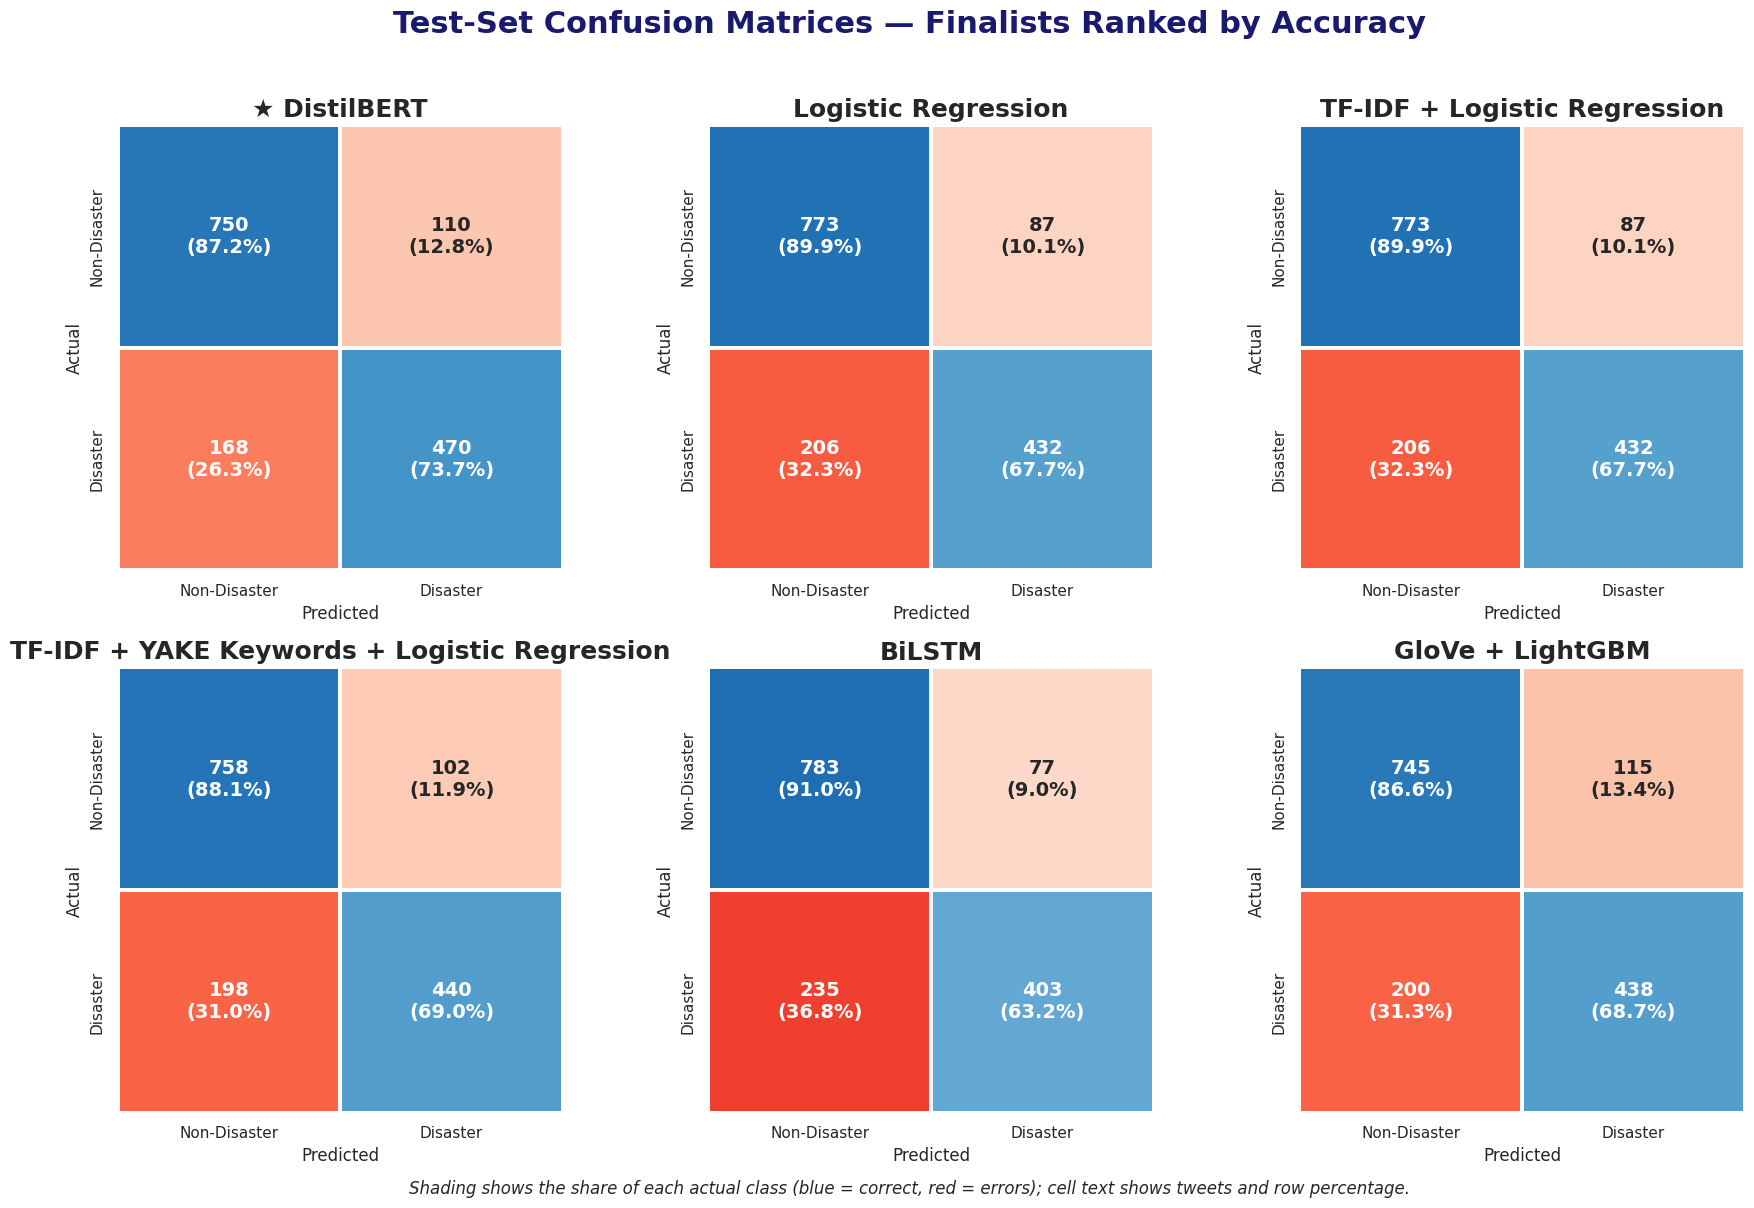

2026-10-12 23:14:30,283 - disaster_classification - INFO - Confusion matrices rendered — selected=DistilBERT, fn=168, fp=110


In [98]:
subsection_header("Confusion Matrices — All Finalists")

class_labels = ["Non-Disaster", "Disaster"]
ranked_finalists = test_metrics_df["Finalist"].tolist()
correct_cells = np.eye(2, dtype=bool)

fig, axes = plt.subplots(2, 3, figsize=(18, 11.5))
fig.suptitle("Test-Set Confusion Matrices — Finalists Ranked by Accuracy",fontsize=22, fontweight="bold", y=1.02, color=PLOT_COLOR)
fig.subplots_adjust(wspace=0.3, hspace=0.4)

confusion_counts = {}
for ax, name in zip(axes.ravel(), ranked_finalists):
    cm = confusion_matrix(y_true, test_predictions[name]["y_pred"], labels=[0, 1])
    confusion_counts[name] = cm
    row_share = cm / cm.sum(axis=1, keepdims=True)
    annotations = np.array([[f"{cm[i, j]:,}\n({row_share[i, j]:.1%})" for j in range(2)] for i in range(2)])
    common = dict(annot=annotations, fmt="", cbar=False, square=True, linewidths=1.5, linecolor="white",annot_kws={"size": 14, "weight": "bold"}, xticklabels=class_labels, yticklabels=class_labels, ax=ax)

    # Shade by share of each actual class: blue = correct, red = errors
    sns.heatmap(row_share, mask=~correct_cells, cmap="Blues", vmin=0, vmax=1.2, **common)
    sns.heatmap(row_share, mask=correct_cells, cmap="Reds", vmin=0, vmax=0.6, **common)
    star = "★ " if name == selected_model_name else ""
    ax.set_title(f"{star}{name}", fontweight="bold", fontsize=18)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

fig.text(0.5, -0.01, "Shading shows the share of each actual class (blue = correct, red = errors); cell text shows tweets and row percentage.", ha="center", fontsize=12, style="italic")
plt.tight_layout()
plt.savefig("Assets/evaluation_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

fn_counts = {name: int(cm[1, 0]) for name, cm in confusion_counts.items()}
fp_counts = {name: int(cm[0, 1]) for name, cm in confusion_counts.items()}
fewest_fn = min(fn_counts, key=fn_counts.get)
fewest_fp = min(fp_counts, key=fp_counts.get)
info_box(f"Fewest missed disasters (false negatives): <b>{fewest_fn}</b> ({fn_counts[fewest_fn]}).\nFewest false alarms (false positives): <b>{fewest_fp}</b> ({fp_counts[fewest_fp]}). Selected model: <b>{selected_model_name}</b> — {fn_counts[selected_model_name]} missed, {fp_counts[selected_model_name]} false alarms.")
logger.info(f"Confusion matrices rendered — selected={selected_model_name}, fn={fn_counts[selected_model_name]}, fp={fp_counts[selected_model_name]}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Confusion Matrices:**

* **DistilBERT** correctly identifies **470 of the 638** disaster tweets (**73.7%**) and misses **168**, the fewest of any finalist. The Logistic Regression models identify **432** (67.7%) and miss **206**, and the BiLSTM misses the most, **235** (36.8% of disasters).
* The gain has a cost. DistilBERT raises **110 false alarms** (12.8% of non-disaster tweets), against **87** for Logistic Regression and **77** for the BiLSTM, the fewest. Compared with Logistic Regression, DistilBERT catches **38 more real disasters** for **23 more false alarms**.
* For disaster monitoring, a missed event is usually costlier than a false alert, which supports the higher-Recall model, although DistilBERT's extra false alarms would add review work for a human operator.

<hr style="width:45%; margin:auto;">

</div>

### 📌 ROC Curves — All Finalists

<div style="margin-left: 20px; max-width: 90%">

ROC curves for the six finalists, computed from the saved test probabilities. Each curve shows how a model trades true positives against false alarms across all decision thresholds; the selected model is drawn thicker, and a zoomed panel separates the curves in the low false-positive region.

</div>

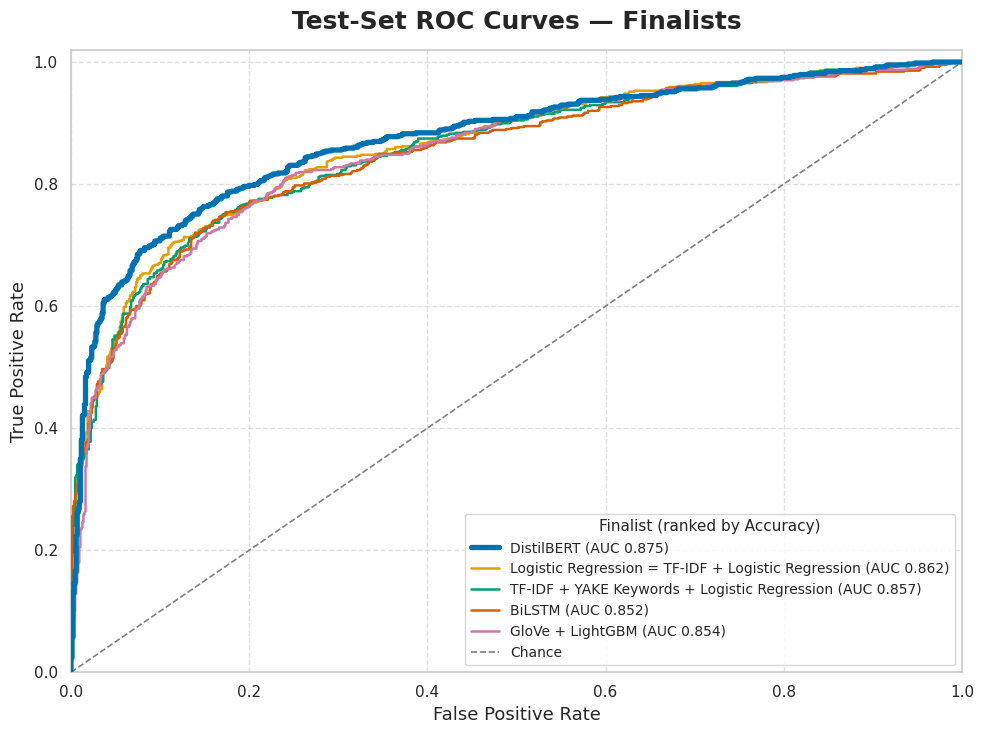

2026-10-12 23:19:45,638 - disaster_classification - INFO - ROC curves rendered — best_auc=DistilBERT


In [100]:
subsection_header("ROC Curves — All Finalists")

# Fixed colour per finalist, reused by every later comparison chart
finalist_colors = dict(zip(finalist_names, ["#E69F00", "#CC79A7", "#000000", "#009E73", "#D55E00", "#0072B2"]))
ranked_finalists = test_metrics_df["Finalist"].tolist()

roc_curves, roc_auc = {}, {}
for name in finalist_names:
    fpr, tpr, _ = roc_curve(y_true, test_predictions[name]["y_score"])
    roc_curves[name] = (fpr, tpr)
    roc_auc[name] = roc_auc_score(y_true, test_predictions[name]["y_score"])

# Merge finalists whose scores are identical (Logistic Regression and TF-IDF + Logistic Regression)
# so they are drawn once instead of one line hiding the other
score_groups = []
for name in ranked_finalists:
    scores = np.asarray(test_predictions[name]["y_score"])
    for group in score_groups:
        if np.allclose(scores, np.asarray(test_predictions[group[0]]["y_score"])):
            group.append(name)
            break
    else:
        score_groups.append([name])

fig, ax = plt.subplots(figsize=(10, 7.5))
for group in score_groups:
    lead = group[0]
    is_selected = selected_model_name in group
    sns.lineplot(x=roc_curves[lead][0], y=roc_curves[lead][1], sort=False, estimator=None,color=finalist_colors[lead], linestyle="-",linewidth=3.8 if is_selected else 1.8, zorder=10 if is_selected else 3,label=f"{' = '.join(group)} (AUC {roc_auc[lead]:.3f})", ax=ax)

sns.lineplot(x=[0, 1], y=[0, 1], color="grey", linestyle="--", linewidth=1.2, label="Chance", ax=ax)
ax.set_title("Test-Set ROC Curves — Finalists", fontweight="bold", fontsize=18,pad=15)
ax.set_xlabel("False Positive Rate", fontsize=13)
ax.set_ylabel("True Positive Rate", fontsize=13)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(linestyle="--", alpha=0.6)
ax.legend(title="Finalist (ranked by Accuracy)", loc="lower right", fontsize=10, title_fontsize=11)

plt.tight_layout()
plt.savefig("Assets/evaluation_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

best_auc = max(roc_auc, key=roc_auc.get)
info_box(f"Highest ROC AUC: <b>{best_auc}</b> ({roc_auc[best_auc]:.3f}). Selected model {selected_model_name}: AUC <b>{roc_auc[selected_model_name]:.3f}</b>. Lowest AUC: <b>{min(roc_auc, key=roc_auc.get)}</b> ({min(roc_auc.values()):.3f}).")
logger.info(f"ROC curves rendered — best_auc={best_auc}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — ROC Curves:**

* **DistilBERT has the highest ROC AUC (0.875)**, ahead of the Logistic Regression models (**0.862**), the YAKE-enhanced model (**0.857**), GloVe + LightGBM (**0.854**) and the BiLSTM (**0.852**).
* This matters because AUC does not depend on the 0.5 decision threshold. DistilBERT's advantage is therefore not just a threshold effect behind the **0.0100** Accuracy margin, which was only about 15 tweets.
* The two Logistic Regression finalists are indistinguishable, and the other three finalists fall within about **0.01** AUC of them, so most models rank disaster tweets above non-disaster tweets similarly well.

<hr style="width:45%; margin:auto;">

</div>

### 📌 Precision–Recall Curves — All Finalists

<div style="margin-left: 20px; max-width: 90%">

Precision–Recall curves for the six finalists, computed from the same saved test probabilities, with the same colors and line styles as the ROC chart. The dashed grey line marks the no-skill baseline, the Disaster share of the test set, and a zoomed panel separates the curves in the high-recall region.

</div>

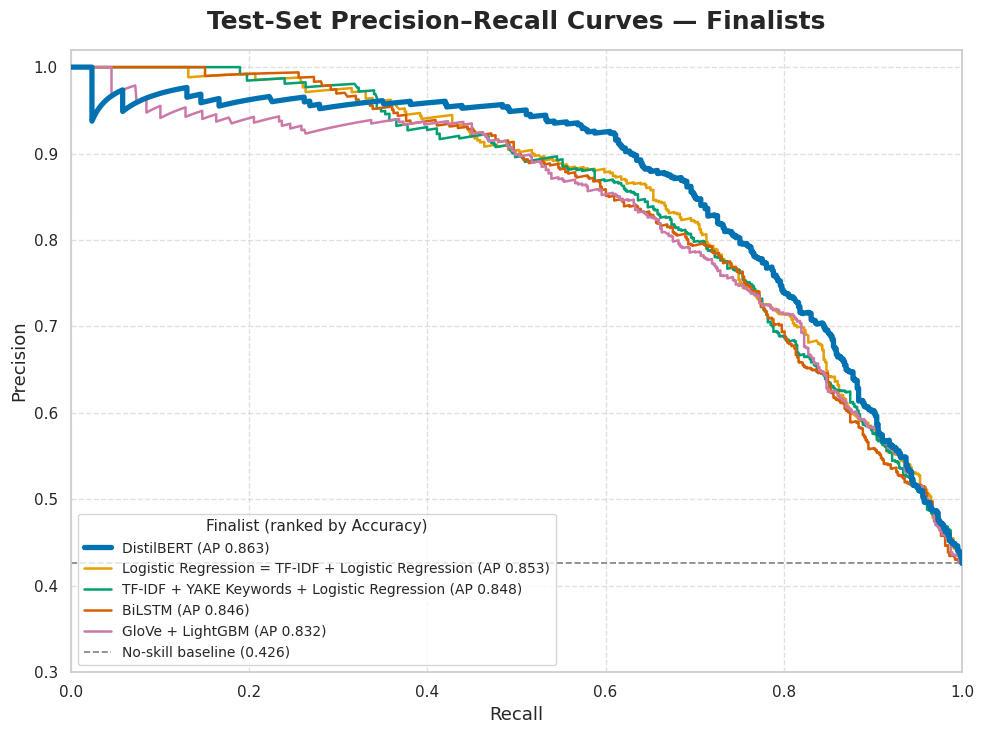

2026-10-12 23:22:23,509 - disaster_classification - INFO - PR curves rendered — best_ap=DistilBERT


In [101]:
subsection_header("Precision–Recall Curves — All Finalists")

pr_curves, pr_ap = {}, {}
for name in finalist_names:
    precision, recall, _ = precision_recall_curve(y_true, test_predictions[name]["y_score"])
    pr_curves[name] = (recall, precision)
    pr_ap[name] = average_precision_score(y_true, test_predictions[name]["y_score"])
prevalence = y_true.mean()

fig, ax = plt.subplots(figsize=(10, 7.5))
for group in score_groups:
    lead = group[0]
    is_selected = selected_model_name in group
    sns.lineplot(x=pr_curves[lead][0], y=pr_curves[lead][1], sort=False, estimator=None,color=finalist_colors[lead], linestyle="-",linewidth=3.8 if is_selected else 1.8, zorder=10 if is_selected else 3,label=f"{' = '.join(group)} (AP {pr_ap[lead]:.3f})", ax=ax)

sns.lineplot(x=[0, 1], y=[prevalence, prevalence], color="grey", linestyle="--", linewidth=1.2,label=f"No-skill baseline ({prevalence:.3f})", ax=ax)
ax.set_title("Test-Set Precision–Recall Curves — Finalists", fontweight="bold", fontsize=18, pad=15)
ax.set_xlabel("Recall", fontsize=13)
ax.set_ylabel("Precision", fontsize=13)
ax.set_xlim(0, 1)
ax.set_ylim(0.3, 1.02)
ax.grid(linestyle="--", alpha=0.6)
ax.legend(title="Finalist (ranked by Accuracy)", loc="lower left", fontsize=10, title_fontsize=11)

plt.tight_layout()
plt.savefig("Assets/evaluation_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

best_ap = max(pr_ap, key=pr_ap.get)
info_box(f"Highest Average Precision: <b>{best_ap}</b> ({pr_ap[best_ap]:.3f}).Selected model {selected_model_name}: AP <b>{pr_ap[selected_model_name]:.3f}</b>. Disaster share of test set (no-skill baseline): <b>{prevalence:.1%}</b>.")
logger.info(f"PR curves rendered — best_ap={best_ap}")

<div style="margin-left: 40px; max-width: 90%">

💡 **Interpretation — Precision–Recall Curves:**

* All finalists stay far above the no-skill baseline of **42.6%**, the Disaster share of the test set. **DistilBERT again has the highest Average Precision (0.863)**, ahead of the Logistic Regression models (**0.853**), the YAKE-enhanced model (**0.848**), the BiLSTM (**0.846**) and GloVe + LightGBM (**0.832**).
* The curves are closest at low recall, where every model's most confident predictions are mostly correct, and separate in the high-recall region, where DistilBERT keeps higher Precision as it captures more disasters. That is where a monitoring system pays for missed events with false alarms.

<hr style="width:45%; margin:auto;">

</div>

## 09. Model Validation

<div style="margin-left: 20px; max-width: 90%">

Evaluation reported how each finalist performs on the held-out test set. Validation asks whether the selected model's result can be trusted: whether it matches what selection predicted, whether training shows over- or under-fitting, how much uncertainty surrounds the number, and whether it holds up when the text is perturbed. The test set is reused here, so these checks assess reliability and do not count as a second selection. Any adjustment prompted by validation would use training data only.

</div>

### 📌 Selection vs. Test Performance

<div style="margin-left: 20px; max-width: 90%">

Comparing each finalist's selection-stage Accuracy and F1 (5-fold CV or internal validation split) with its test result. A large drop on the test set would mean the selection score was optimistic.

</div>

In [102]:
subsection_header("Selection vs. Test Performance")

GAP_TOLERANCE = 0.03   # a test Accuracy this far below the selection score is flagged
gap_df = (selection_reference_df[["Finalist", "Selection Accuracy", "Selection F1"]].merge(test_metrics_df[["Rank", "Finalist", "Test Accuracy", "Test F1"]], on="Finalist").sort_values("Rank").reset_index(drop=True))
gap_df["Accuracy Gap"] = gap_df["Test Accuracy"] - gap_df["Selection Accuracy"]
gap_df["F1 Gap"] = gap_df["Test F1"] - gap_df["Selection F1"]
gap_df["Reading"] = np.select([gap_df["Accuracy Gap"].isna(),gap_df["Accuracy Gap"].abs() <= GAP_TOLERANCE,gap_df["Accuracy Gap"] < 0],["Selection score unavailable", "Consistent", "Selection score optimistic"],default="Test higher than selection")
gap_display = gap_df[["Rank", "Finalist", "Selection Accuracy", "Test Accuracy", "Accuracy Gap","Selection F1", "Test F1", "F1 Gap", "Reading"]].copy()
for col in ["Selection Accuracy", "Test Accuracy", "Selection F1", "Test F1"]:
    gap_display[col] = gap_display[col].map(lambda v: f"{v:.4f}" if pd.notna(v) else "n/a")
for col in ["Accuracy Gap", "F1 Gap"]:
    gap_display[col] = gap_display[col].map(lambda v: f"{v:+.4f}" if pd.notna(v) else "n/a")
centered_table(gap_display)

selected_gap = gap_df.loc[gap_df["Finalist"] == selected_model_name, "Accuracy Gap"].iloc[0]
info_box(f"Selected model <b>{selected_model_name}</b>: test Accuracy differs from its selection score by <b>{selected_gap:+.4f}</b>.\nSelection scores come from 5-fold CV (classical-style models) or the internal 15% validation split (BiLSTM, DistilBERT), so the two columns are close but not identical in protocol.")
logger.info(f"Selection-vs-test gap computed — selected_gap={selected_gap:+.4f}")

Rank,Finalist,Selection Accuracy,Test Accuracy,Accuracy Gap,Selection F1,Test F1,F1 Gap,Reading
1,DistilBERT,0.8209,0.8144,-0.0065,0.7785,0.7718,-0.0068,Consistent
2,Logistic Regression,0.8041,0.8044,+0.0003,0.7462,0.7468,+0.0006,Consistent
3,TF-IDF + Logistic Regression,0.8034,0.8044,+0.0010,0.7400,0.7468,+0.0068,Consistent
4,TF-IDF + YAKE Keywords + Logistic Regression,0.7946,0.7997,+0.0052,0.7362,0.7458,+0.0096,Consistent
5,BiLSTM,0.7931,0.7917,-0.0014,0.7207,0.7209,+0.0002,Consistent
6,GloVe + LightGBM,0.7981,0.7897,-0.0083,0.7488,0.7355,-0.0133,Consistent


2026-10-12 23:27:38,718 - disaster_classification - INFO - Selection-vs-test gap computed — selected_gap=-0.0065


💡 **Interpretation — Selection vs. Test Performance:**

- All six finalists are marked **Consistent**: every test Accuracy lies within 0.01 of its selection score, well inside the 0.03 tolerance.
- The selected model, **DistilBERT**, moved from 0.8209 at selection to 0.8144 on the test set (−0.0065), a small drop with no sign that selection overfitted to the validation data.
- Logistic Regression and TF-IDF + Logistic Regression had slightly different selection scores (0.8041 and 0.8034) but identical test results, as expected from the same underlying model.
- The ranking was not reshuffled by the test set in any material way, which supports the selection stage having been sound.

### 📌 Training vs. Validation Loss — Deep Learning Finalists

<div style="margin-left: 20px; max-width: 90%">

Loss curves from the saved training histories of BiLSTM and DistilBERT. They show where validation loss bottomed out (the checkpoint kept) and whether it rose afterwards, which is the standard sign of overfitting. The classical-style finalists were validated through cross-validation instead and have no epoch history.

</div>

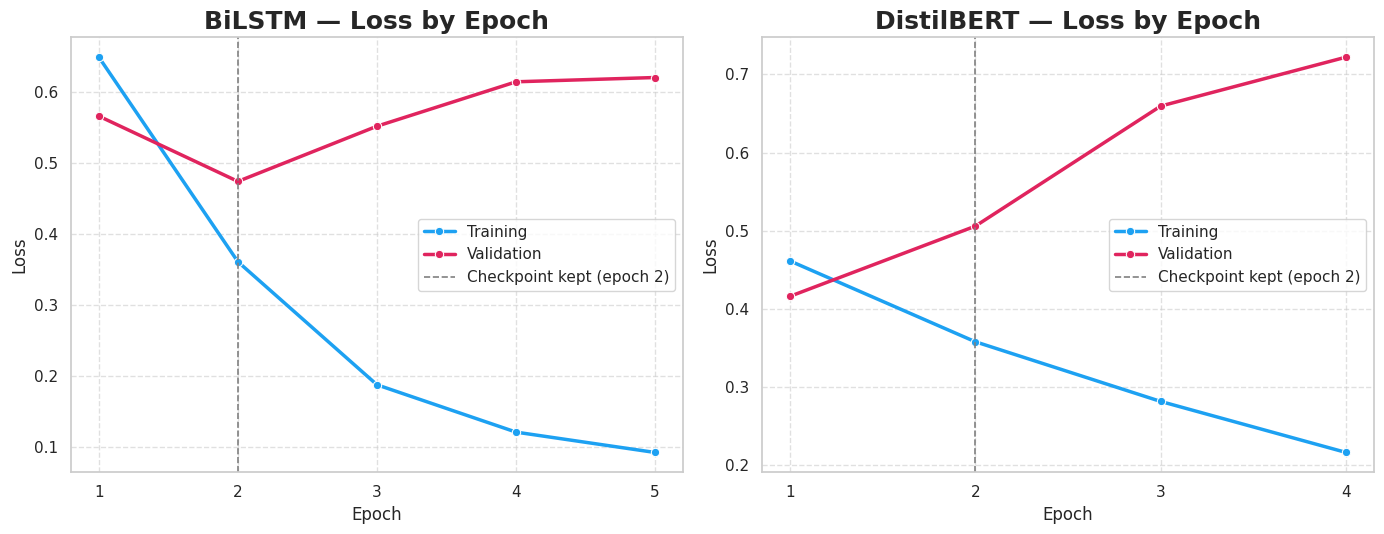

Model,Epochs trained,Checkpoint kept (epoch),Lowest validation loss (epoch),Training loss at kept epoch,Validation loss at kept epoch,"Validation loss rise, kept → final epoch"
BiLSTM,5,2,2,0.3612,0.4744,0.1464
DistilBERT,4,2,1,0.3580,0.5059,0.2163


2026-10-12 23:31:16,506 - disaster_classification - INFO - Loss curves rendered — models=['BiLSTM', 'DistilBERT']


In [103]:
subsection_header("Training vs. Validation Loss — Deep Learning Finalists")

loss_curves = {}
if globals().get("bilstm_history_data") is not None:
    n_ep = len(bilstm_history_data["loss"])
    loss_curves["BiLSTM"] = pd.DataFrame({"Epoch": np.arange(1, n_ep + 1),"Training": bilstm_history_data["loss"],"Validation": bilstm_history_data["val_loss"]})

if globals().get("distilbert_history_data") is not None:
    d_train = {int(round(h["epoch"])): h["loss"] for h in distilbert_history_data if "loss" in h}
    d_val = {int(round(h["epoch"])): h["eval_loss"] for h in distilbert_history_data if "eval_loss" in h}
    d_acc = {int(round(h["epoch"])): h["eval_accuracy"] for h in distilbert_history_data if "eval_accuracy" in h}
    d_epochs = sorted(set(d_train) & set(d_val) & set(d_acc))
    loss_curves["DistilBERT"] = pd.DataFrame({"Epoch": d_epochs,"Training": [d_train[e] for e in d_epochs],"Validation": [d_val[e] for e in d_epochs],"Val Accuracy": [d_acc[e] for e in d_epochs]})

def kept_epoch(name, curve):
    if name == "DistilBERT":
        return int(curve.loc[curve["Val Accuracy"].idxmax(), "Epoch"])
    return int(curve.loc[curve["Validation"].idxmin(), "Epoch"])

if not loss_curves:
    warning_box("Neither training history is in memory — rerun the history retrieval steps first.")
else:
    fig, axes = plt.subplots(1, len(loss_curves), figsize=(7 * len(loss_curves), 5.5), squeeze=False)
    loss_summary = []
    for ax, (name, curve) in zip(axes[0], loss_curves.items()):
        long_df = curve.melt(id_vars="Epoch", value_vars=["Training", "Validation"],var_name="Set", value_name="Loss")
        sns.lineplot(data=long_df, x="Epoch", y="Loss", hue="Set", marker="o", linewidth=2.5,palette={"Training": "#1DA1F2", "Validation": "#E0245E"}, ax=ax)
        low_loss = curve.loc[curve["Validation"].idxmin()]
        kept = kept_epoch(name, curve)
        kept_row = curve.loc[curve["Epoch"] == kept].iloc[0]
        ax.axvline(kept, color="grey", linestyle="--", linewidth=1.2, label=f"Checkpoint kept (epoch {kept})")
        ax.set_title(f"{name} — Loss by Epoch", fontweight="bold", fontsize=18)
        ax.set_xticks(curve["Epoch"])
        ax.grid(linestyle="--", alpha=0.6)
        ax.legend()
        loss_summary.append({
            "Model": name,
            "Epochs trained": len(curve),
            "Checkpoint kept (epoch)": kept,
            "Lowest validation loss (epoch)": int(low_loss["Epoch"]),
            "Training loss at kept epoch": round(kept_row["Training"], 4),
            "Validation loss at kept epoch": round(kept_row["Validation"], 4),
            "Validation loss rise, kept → final epoch": round(curve["Validation"].iloc[-1] - kept_row["Validation"], 4)})
    plt.tight_layout()
    plt.savefig("Assets/validation_loss_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

    loss_summary_df = pd.DataFrame(loss_summary)
    centered_table(loss_summary_df)
    info_box("The dashed line marks the checkpoint each deep model keeps: BiLSTM at its lowest validation loss, DistilBERT at its highest validation Accuracy (the project's primary metric).\n Validation loss rising while training loss keeps falling is the standard overfitting signal.")
    logger.info(f"Loss curves rendered — models={list(loss_curves)}")

💡 **Interpretation — Training vs. Validation Loss:**

- Both deep models **overfit if trained beyond the early epochs**.
- **BiLSTM:** the kept epoch is also its lowest-validation-loss epoch (0.4744). Validation loss then climbs by 0.1464 by epoch 5, a clear overfitting pattern that the restore-best-weights setting guards against.
- **DistilBERT:** the kept epoch (2) is the one with the highest validation Accuracy, the project's primary metric. Its lowest validation loss came a little earlier, at epoch 1 (0.4160), and loss rose by 0.2163 by epoch 4. Training beyond epoch 2 would have hurt, so the early-stopping and best-checkpoint setup was necessary and not just a precaution.
- At the kept epoch, validation loss sits above training loss by 0.1132 for BiLSTM and 0.1480 for DistilBERT.
- Validation loss at DistilBERT's kept epoch is higher than at epoch 1 even though Accuracy is better. This suggests its predicted probabilities are somewhat over-confident on the tweets it gets wrong. The Accuracy and F1 ranking is unaffected, but confidence scores in the dashboard should be described as model scores, not calibrated probabilities.

### 📌 Bootstrap 95% Confidence Interval — Selected Model

<div style="margin-left: 20px; max-width: 90%">

A single test Accuracy is one draw from a finite sample. Resampling the test tweets 2,000 times gives a 95% interval around the selected model's Accuracy and F1. A paired comparison against the runner-up, using the same resamples for both models, shows whether the lead is distinguishable from chance.

</div>

In [104]:
subsection_header("Bootstrap 95% Confidence Interval — Selected Model")

N_BOOT = 2000
rng = np.random.default_rng(42)
n_test = len(y_true)
boot_idx = rng.integers(0, n_test, size=(N_BOOT, n_test))
boot_true = y_true[boot_idx]

def boot_accuracy(pred):
    return (np.asarray(pred)[boot_idx] == boot_true).mean(axis=1)

def boot_f1(pred):
    p = np.asarray(pred)[boot_idx]
    tp = ((p == 1) & (boot_true == 1)).sum(axis=1)
    fp = ((p == 1) & (boot_true == 0)).sum(axis=1)
    fn = ((p == 0) & (boot_true == 1)).sum(axis=1)
    return 2 * tp / (2 * tp + fp + fn)

selected_pred = test_predictions[selected_model_name]["y_pred"]
runner_up_name = test_metrics_df["Finalist"].iloc[1]
runner_pred = test_predictions[runner_up_name]["y_pred"]

sel_acc, sel_f1 = boot_accuracy(selected_pred), boot_f1(selected_pred)
acc_diff = sel_acc - boot_accuracy(runner_pred)    # paired: same resamples for both models

acc_lo, acc_hi = np.percentile(sel_acc, [2.5, 97.5])
f1_lo, f1_hi = np.percentile(sel_f1, [2.5, 97.5])
diff_lo, diff_hi = np.percentile(acc_diff, [2.5, 97.5])
share_ge = float((acc_diff >= 0).mean())

point_acc = float((selected_pred == y_true).mean())
ci_table = pd.DataFrame([
    {"Quantity": f"{selected_model_name} — Accuracy", "Point estimate": f"{point_acc:.4f}","95% CI": f"[{acc_lo:.4f}, {acc_hi:.4f}]"},
    {"Quantity": f"{selected_model_name} — F1", "Point estimate": f"{test_metrics_df['Test F1'].iloc[0]:.4f}","95% CI": f"[{f1_lo:.4f}, {f1_hi:.4f}]"},
    {"Quantity": f"Accuracy difference vs {runner_up_name}","Point estimate": f"{point_acc - float((runner_pred == y_true).mean()):+.4f}","95% CI": f"[{diff_lo:+.4f}, {diff_hi:+.4f}]"}])
centered_table(ci_table)

excludes_zero = diff_lo > 0
info_box(f"{N_BOOT:,} bootstrap resamples of the {n_test:,} test tweets (seed 42). {selected_model_name} Accuracy 95% CI: <b>[{acc_lo:.4f}, {acc_hi:.4f}]</b>. Its lead over {runner_up_name} was positive in <b>{share_ge:.1%}</b> of paired resamples; the 95% interval for the difference <b>{'excludes' if excludes_zero else 'includes'}</b> zero.")
logger.info(f"Bootstrap CI — acc=[{acc_lo:.4f}, {acc_hi:.4f}], diff=[{diff_lo:+.4f}, {diff_hi:+.4f}], share_ge={share_ge:.3f}")

Quantity,Point estimate,95% CI
DistilBERT — Accuracy,0.8144,"[0.7937, 0.8344]"
DistilBERT — F1,0.7718,"[0.7441, 0.7971]"
Accuracy difference vs Logistic Regression,+0.0100,"[-0.0053, +0.0260]"


2026-10-12 23:34:41,908 - disaster_classification - INFO - Bootstrap CI — acc=[0.7937, 0.8344], diff=[-0.0053, +0.0260], share_ge=0.908


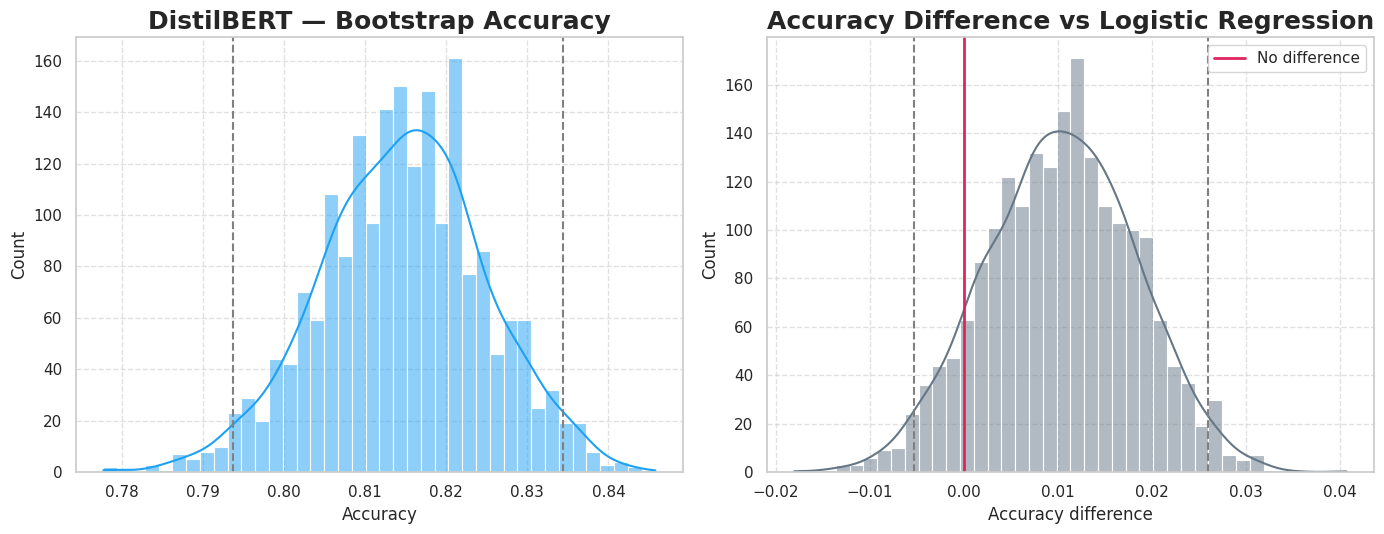

2026-10-12 23:41:59,565 - disaster_classification - INFO - Bootstrap accuracy plot rendered.


In [105]:
subsection_header("Bootstrap Accuracy Plot")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.histplot(sel_acc, bins=40, kde=True, color="#1DA1F2", ax=axes[0])
axes[0].axvline(acc_lo, color="grey", linestyle="--"); axes[0].axvline(acc_hi, color="grey", linestyle="--")
axes[0].set_title(f"{selected_model_name} — Bootstrap Accuracy", fontweight="bold", fontsize=18)
axes[0].set_xlabel("Accuracy")

sns.histplot(acc_diff, bins=40, kde=True, color="#657786", ax=axes[1])
axes[1].axvline(0, color="#E0245E", linewidth=2, label="No difference")
axes[1].axvline(diff_lo, color="grey", linestyle="--"); axes[1].axvline(diff_hi, color="grey", linestyle="--")
axes[1].set_title(f"Accuracy Difference vs {runner_up_name}", fontweight="bold", fontsize=18)
axes[1].set_xlabel("Accuracy difference"); axes[1].legend()
for ax in axes:
    ax.grid(linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("Assets/validation_bootstrap.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Bootstrap accuracy plot rendered.")

💡 **Interpretation — Bootstrap 95% Confidence Interval:**

- DistilBERT's test Accuracy of **0.8144** carries a 95% interval of **[0.7937, 0.8344]**, roughly ±2 percentage points. That is the sampling uncertainty of a 1,498-tweet test set.
- Its lead over Logistic Regression is **+0.0100**, with a 95% interval of **[−0.0053, +0.0260]** that includes zero. DistilBERT led in 90.8% of paired resamples, which is suggestive but short of the conventional 95% bar.
- The runner-up's Accuracy (0.8044) lies inside DistilBERT's own interval, so the two cannot be separated on Accuracy alone.
- DistilBERT is therefore the **highest-scoring** finalist, but the evidence for it being **better** than Logistic Regression is moderate, not conclusive. The final comparison will state this as a near-tie.

### 📌 Robustness Check — Selected Model

<div style="margin-left: 20px; max-width: 90%">

Re-scoring the selected model on noisier versions of the test text: 10% and 20% of words with swapped letters (typo noise), and 10% and 20% of words dropped. Uppercasing and hashtag/URL removal were not used as tests, because the model lowercases its input and the cleaned text already has those elements removed.

</div>

In [106]:
subsection_header("Robustness Check — Selected Model")

ROBUST_TOLERANCE = 0.02   # an Accuracy drop larger than this is flagged
def make_scorer(name, batch_size=32):
    """Return (score_fn, release_fn) for the selected model; score_fn maps a list of texts to P(Disaster)."""
    if name == "DistilBERT":
        local_ready = os.path.isfile(os.path.join(DISTILBERT_MODEL_DIR, "config.json"))
        source = DISTILBERT_MODEL_DIR if local_ready else DISTILBERT_HF_REPO_ID
        tokenizer = AutoTokenizer.from_pretrained(source)
        model = AutoModelForSequenceClassification.from_pretrained(source)
        device = "cuda" if torch.cuda.is_available() else "cpu"
        model.to(device).eval()

        def score(texts):
            out = []
            with torch.no_grad():
                for s in range(0, len(texts), batch_size):
                    enc = tokenizer(texts[s:s + batch_size], truncation=True, padding=True,max_length=DISTILBERT_MAX_LENGTH, return_tensors="pt").to(device)
                    out.append(torch.softmax(model(**enc).logits, dim=-1)[:, 1].cpu().numpy())
            return np.concatenate(out)

        def release():
            nonlocal model
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        return score, release

    for family, artifact in finalist_artifacts.items():
        if artifact["best_model_name"] == name and isinstance(test_inputs[family], pd.Series):
            pipe = artifact["best_model"]
            return (lambda texts: pipe.predict_proba(pd.Series(texts))[:, 1]), (lambda: None)
    raise NotImplementedError(f"No raw-text scorer is defined for {name}.")

# Text perturbations (applied to the model-input text)
def perturb_upper(t):
    return t.upper()

def perturb_strip(t):
    return re.sub(r"\s+", " ", re.sub(r"(#\w+|@\w+|https?://\S+|www\.\S+)", " ", t)).strip()

def perturb_typos(t, rate=0.10):
    words = t.split()
    for i, w in enumerate(words):
        if len(w) > 3 and noise_rng.random() < rate:
            j = int(noise_rng.integers(0, len(w) - 1))
            words[i] = w[:j] + w[j + 1] + w[j] + w[j + 2:]
    return " ".join(words)

def perturb_dropout(t, rate=0.10):
    words = t.split()
    kept = [w for w in words if noise_rng.random() >= rate]
    return " ".join(kept if kept else words)

original_texts = X_test["text_clean"].astype(str).tolist()
noise_rng = np.random.default_rng(42)
conditions = {
    "Original": original_texts,
    "Typo noise (10% of words)": [perturb_typos(t) for t in original_texts],
    "Word dropout (10% of words)": [perturb_dropout(t) for t in original_texts],
    "Typo noise (20% of words)": [perturb_typos(t, 0.20) for t in original_texts],
    "Word dropout (20% of words)": [perturb_dropout(t, 0.20) for t in original_texts]}

score_fn, release_fn = make_scorer(selected_model_name)
rows = []
for label, texts in conditions.items():
    pred = (score_fn(texts) >= 0.5).astype(int)
    rows.append({"Condition": label,"Tweets changed": sum(a != b for a, b in zip(texts, original_texts)),"Accuracy": accuracy_score(y_true, pred),"F1": f1_score(y_true, pred)})

release_fn()
robust_df = pd.DataFrame(rows)
baseline_acc = robust_df.loc[0, "Accuracy"]
robust_df["Δ Accuracy"] = robust_df["Accuracy"] - baseline_acc
recorded_acc = test_metrics_df["Test Accuracy"].iloc[0]
if abs(baseline_acc - recorded_acc) > 0.002:
    warning_box(f"Re-scored baseline Accuracy ({baseline_acc:.4f}) differs from the recorded test Accuracy ({recorded_acc:.4f}).")

robust_display = robust_df.copy()
robust_display["Accuracy"] = robust_display["Accuracy"].map("{:.4f}".format)
robust_display["F1"] = robust_display["F1"].map("{:.4f}".format)
robust_display["Δ Accuracy"] = robust_display["Δ Accuracy"].map("{:+.4f}".format)
centered_table(robust_display)

perturbed = robust_df.iloc[1:]
worst = perturbed.loc[perturbed["Δ Accuracy"].idxmin()]
info_box(f"Largest Accuracy change: <b>{worst['Condition']}</b> ({worst['Δ Accuracy']:+.4f}). Perturbations act on the cleaned model-input text, so <i>Tweets changed</i> shows how many tweets each one actually altered.")
logger.info(f"Robustness check — worst={worst['Condition']} ({worst['Δ Accuracy']:+.4f})")

Condition,Tweets changed,Accuracy,F1,Δ Accuracy
Original,0,0.8144,0.7718,+0.0000
Typo noise (10% of words),749,0.8138,0.7685,-0.0007
Word dropout (10% of words),846,0.8077,0.7600,-0.0067
Typo noise (20% of words),1089,0.8011,0.7487,-0.0134
Word dropout (20% of words),1191,0.8004,0.7402,-0.0140


2026-10-12 23:53:45,368 - disaster_classification - INFO - Robustness check — worst=Word dropout (20% of words) (-0.0140)


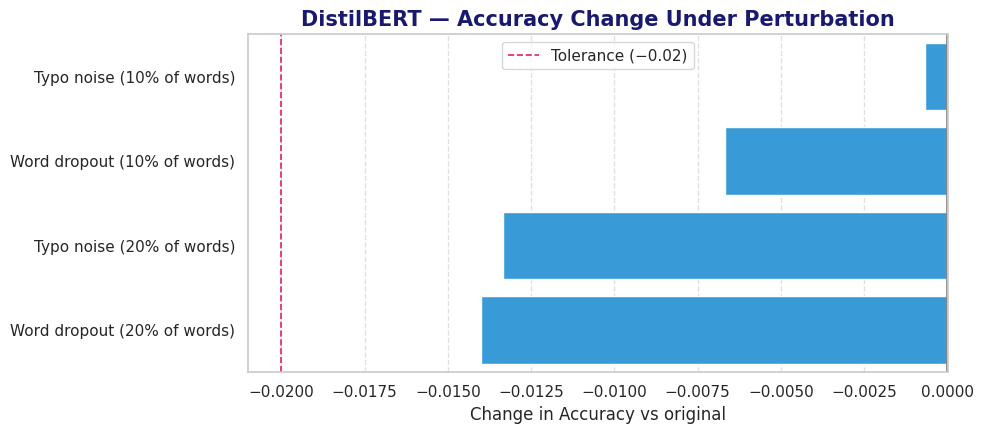

2026-10-12 23:53:45,823 - disaster_classification - INFO - Robustness plot rendered.


In [107]:
subsection_header("Robustness Plot")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=perturbed, y="Condition", x="Δ Accuracy", color="#1DA1F2", ax=ax)
ax.axvline(0, color="grey", linewidth=1.2)
ax.axvline(-ROBUST_TOLERANCE, color="#E0245E", linestyle="--", linewidth=1.2, label=f"Tolerance (−{ROBUST_TOLERANCE})")
ax.set_title(f"{selected_model_name} — Accuracy Change Under Perturbation", fontweight="bold", fontsize=15, color=PLOT_COLOR)
ax.set_xlabel("Change in Accuracy vs original"); ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.6); ax.legend()
plt.tight_layout()
plt.savefig("Assets/validation_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

logger.info("Robustness plot rendered.")

💡 **Interpretation — Robustness Check:**

- DistilBERT is **stable under realistic text noise**. At 10% noise the Accuracy changes by only −0.0007 (typo noise) and −0.0067 (word dropout); at 20% noise the drops are −0.0134 and −0.0140. Every drop stays within the 0.02 tolerance.
- Accuracy degrades gradually as noise increases and does not fall off a cliff. At 20% word dropout, about 21 more tweets are misclassified than in the original, out of 1,498.
- Typos hurt less than dropped words at the lighter level, which is expected.
- Two further perturbations were considered and dropped because they would not have tested anything: uppercasing (the model lowercases its input) and removing hashtags, URLs and mentions (the cleaned text has already had them removed).
- The 20% drops (about 0.014) are larger than DistilBERT's 0.0100 Accuracy lead over Logistic Regression.

### 📌 Validation Verdict

<div style="margin-left: 20px; max-width: 90%">

Three pass/review checks summarise the section: the selection-to-test gap, the paired bootstrap lead over the runner-up, and the worst-case perturbation drop. No model or data change is made on the strength of test-set results; if a check calls for adjustment, only training data may be used.

</div>

In [108]:
subsection_header("Validation Verdict")

gap_ok = abs(selected_gap) <= GAP_TOLERANCE
lead_clear = diff_lo > 0                       # 95% CI of the paired Accuracy difference excludes zero
robust_ok = bool((robust_df["Δ Accuracy"].iloc[1:] >= -ROBUST_TOLERANCE).all())

verdict_df = pd.DataFrame([
    {"Check": "Selection-to-test gap within tolerance", "Result": "Pass" if gap_ok else "Review"},
    {"Check": f"Lead over {runner_up_name} statistically clear (95% CI excludes zero)","Result": "Pass" if lead_clear else "Near-tie"},
    {"Check": f"Accuracy drop under every perturbation within {ROBUST_TOLERANCE}","Result": "Pass" if robust_ok else "Review"}])
centered_table(verdict_df)

if gap_ok and robust_ok and lead_clear:
    success_box(f"<b>{selected_model_name}</b> passed every validation check. No model or data change was made as a result of validation; any future adjustment would use training data only.")

elif gap_ok and robust_ok:
    info_box(f"<b>{selected_model_name}</b> is consistent with its selection score and stable under perturbation, but its Accuracy lead over {runner_up_name} is not statistically clear (95% CI [{diff_lo:+.4f}, {diff_hi:+.4f}]).<br>It is retained as the highest-scoring model on the primary metric and the result is reported as a near-tie.<br>No model or data change was made; any future adjustment would use training data only.")
else:
    warning_box(f"<b>{selected_model_name}</b> has at least one check marked Review.<br>Read the corresponding table above; any adjustment must use training data only, never the test set.")
logger.info(f"Validation verdict — {dict(zip(verdict_df['Check'], verdict_df['Result']))}")

Check,Result
Selection-to-test gap within tolerance,Pass
Lead over Logistic Regression statistically clear (95% CI excludes zero),Near-tie
Accuracy drop under every perturbation within 0.02,Pass


2026-10-12 23:53:45,873 - disaster_classification - INFO - Validation verdict — {'Selection-to-test gap within tolerance': 'Pass', 'Lead over Logistic Regression statistically clear (95% CI excludes zero)': 'Near-tie', 'Accuracy drop under every perturbation within 0.02': 'Pass'}


💡 **Interpretation — Validation Verdict:**

- **Selection gap: Pass.** Test Accuracy is within 0.0065 of the selection score, so the model was not chosen on a lucky validation result.
- **Lead over the runner-up: Near-tie.** The 95% interval for DistilBERT's Accuracy lead over Logistic Regression ([−0.0053, +0.0260]) includes zero, so the lead is suggestive but not statistically established.
- **Robustness: Pass.** All perturbation drops are within 0.02.
- **Conclusion:** DistilBERT is retained as the selected model because it is highest on the primary metric (Accuracy) and the secondary metric (F1), and ranks first on ROC AUC and Average Precision as well. It is reported with an explicit near-tie caveat. No change was made to the model or data on the basis of validation.

## 10. Final Model Comparison

<div style="margin-left: 20px; max-width: 90%">

This section brings the six finalists together on the held-out test set: one chart of Accuracy (primary) and F1 (secondary), a consolidated table of every metric produced in the evaluation and validation sections, and the formal declaration of the winning model, including the caveat from the validation checks.

</div>

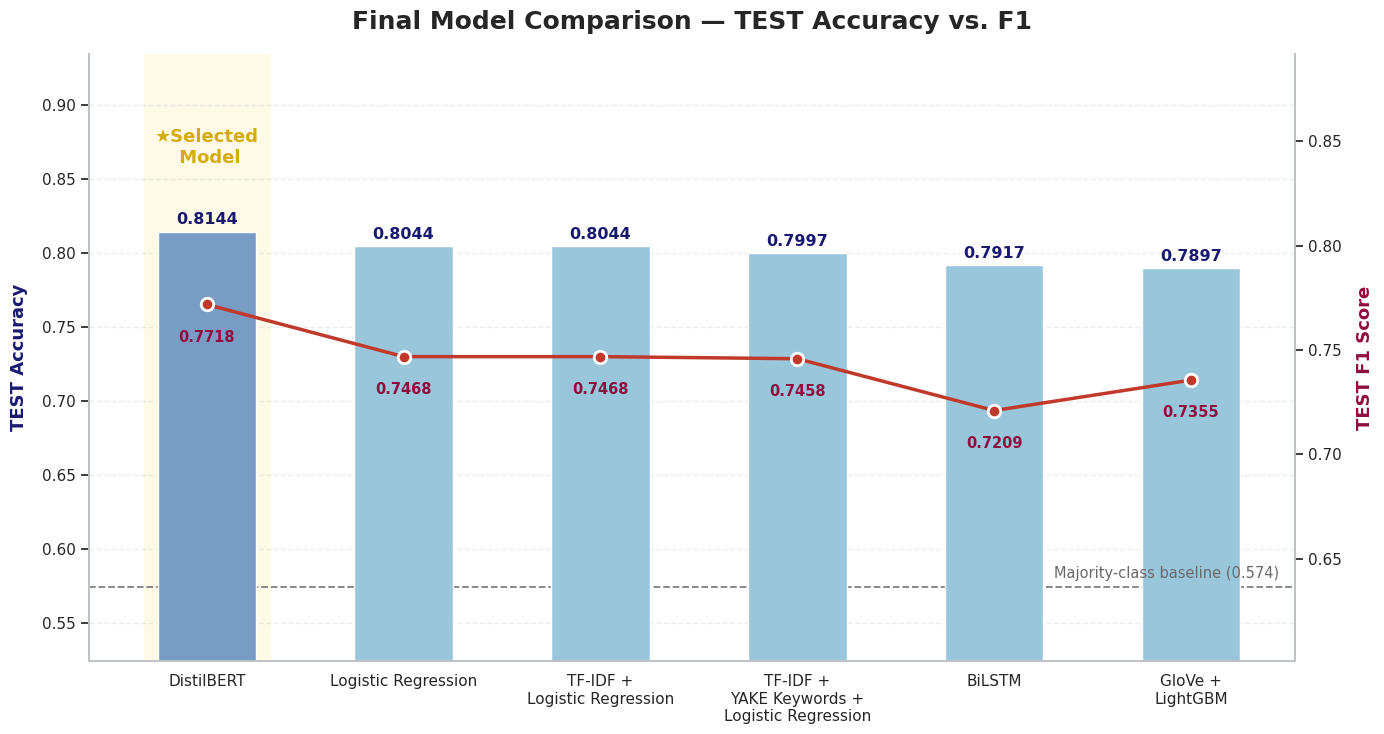

2026-10-13 00:31:57,521 - disaster_classification - INFO - Final comparison generated — selected=DistilBERT, test_accuracy=0.8144, test_f1=0.7718


In [112]:
section_header("Final Model Comparison")
subsection_header("Test Metrics - Accuracy & F1 score")

final_viz_data = test_metrics_df.sort_values("Rank").reset_index(drop=True)
best_index = final_viz_data.index[final_viz_data["Finalist"] == selected_model_name][0]
majority_accuracy = max(float(np.mean(y_true)), 1 - float(np.mean(y_true)))

fig, ax1 = plt.subplots(figsize=(14, 7.5))
ax1.axvspan(best_index - 0.32,best_index + 0.32,color="#FFF9E6",alpha=0.9,zorder=0)

# PRIMARY: TEST Accuracy
bar_colors = ["#6C9BD2" if model == selected_model_name else "#8ECAE6" for model in final_viz_data["Finalist"]]
sns.barplot(data=final_viz_data,x="Finalist",y="Test Accuracy",ax=ax1,palette=bar_colors,hue="Finalist",legend=False,width=0.50,zorder=2)
ax1.set_ylabel("TEST Accuracy",fontweight="bold",fontsize=13,color="midnightblue",labelpad=10)
accuracy_max = final_viz_data["Test Accuracy"].max()
ax1.set_ylim(max(0.0, majority_accuracy - 0.05),min(1.0, accuracy_max + 0.12))
ax1.axhline(majority_accuracy,color="grey",linestyle="--",linewidth=1.3,zorder=1)
ax1.text(len(final_viz_data) - 0.55,majority_accuracy + 0.004,f"Majority-class baseline ({majority_accuracy:.3f})",ha="right",va="bottom",fontsize=10.5,color="dimgrey",zorder=5)

for i, val in enumerate(final_viz_data["Test Accuracy"]):
    ax1.text(i,val + 0.013,f"{val:.4f}",ha="center",va="top",fontweight="bold",fontsize=11.5,color="midnightblue",zorder=5)

ax1.text(best_index,ax1.get_ylim()[1] - 0.05,"★Selected\n Model",ha="center",va="top",fontweight="bold",fontsize=13,color="#D4AC0D",zorder=5)
ax1.set_xticks(range(len(final_viz_data)))
ax1.set_xticklabels(final_viz_data["Finalist"].str.replace(" + ", " +\n", regex=False),fontsize=11)

# SECONDARY: TEST F1
ax2 = ax1.twinx()
sns.lineplot(data=final_viz_data,x="Finalist",y="Test F1",ax=ax2,color="#C0392B",marker="o",markersize=9,markeredgecolor="white",markeredgewidth=2,linewidth=2.5,sort=False,zorder=4)
ax2.set_ylabel("TEST F1 Score",fontweight="bold",fontsize=13,color="#900C3F",labelpad=10)

f1_min = final_viz_data["Test F1"].min()
f1_max = final_viz_data["Test F1"].max()
ax2.set_ylim(max(0.0, f1_min - 0.12),min(1.0, f1_max + 0.12))
ax2.grid(False)

# F1 labels
for i, val in enumerate(final_viz_data["Test F1"]):
    ax2.text(i,val - 0.012,f"{val:.4f}",ha="center",va="top",color="#900C3F",fontweight="bold",fontsize=10.5,zorder=5)

ax1.set_title("Final Model Comparison — TEST Accuracy vs. F1",fontweight="bold",fontsize=18,pad=18)
ax1.set_xlabel("")
ax1.grid(True,linestyle="--",alpha=0.35,axis="y",zorder=0)
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["left"].set_color("#BDC3C7")
    ax.spines["right"].set_color("#BDC3C7")
    ax.spines["bottom"].set_color("#BDC3C7")

plt.tight_layout()
final_comparison_path = "Assets/final_model_comparison.png"
plt.savefig(final_comparison_path,dpi=150,bbox_inches="tight")
plt.show()
info_box(f"Bars show test Accuracy (primary metric, left axis) and the line shows F1 (secondary, right axis); the two axes use different scales, so compare the values printed on the chart.<br>The dashed line is the Accuracy of always predicting the larger class (<b>{majority_accuracy:.3f}</b>).<br>Logistic Regression and TF-IDF + Logistic Regression are the same model and score identically.")
logger.info(f"Final comparison generated — selected={selected_model_name}, test_accuracy={final_viz_data.loc[best_index, 'Test Accuracy']:.4f}, test_f1={final_viz_data.loc[best_index, 'Test F1']:.4f}")

In [113]:
subsection_header("Consolidated Results Table")

consolidated_df = test_metrics_df.sort_values("Rank").reset_index(drop=True).copy()
consolidated_df["ROC AUC"] = consolidated_df["Finalist"].map(roc_auc)
consolidated_df["Avg Precision"] = consolidated_df["Finalist"].map(pr_ap)
consolidated_display = consolidated_df[["Rank", "Finalist", "Test Accuracy", "Test F1", "Test Precision", "Test Recall", "ROC AUC"]].copy()
metric_cols = ["Test Accuracy", "Test F1", "Test Precision", "Test Recall", "ROC AUC"]
pill_style = ("background-color: #1B5E20; color: #FFFFFF; font-weight: bold; padding: 3px 10px; border-radius: 12px; display: inline-block; white-space: nowrap;")

for col in metric_cols:
    max_val = consolidated_display[col].max()
    consolidated_display[col] = consolidated_display[col].apply(lambda v, mv=max_val: (f'<span style="{pill_style}">{v:.4f}</span>' if pd.notna(v) and v == mv else (f"{v:.4f}" if pd.notna(v) else "n/a")))

centered_table(consolidated_display)
logger.info(f"Consolidated table ready — rows={len(consolidated_df)}")

Rank,Finalist,Test Accuracy,Test F1,Test Precision,Test Recall,ROC AUC
1,DistilBERT,0.8144,0.7718,0.8103,0.7367,0.8749
2,Logistic Regression,0.8044,0.7468,0.8324,0.6771,0.8618
3,TF-IDF + Logistic Regression,0.8044,0.7468,0.8324,0.6771,0.8618
4,TF-IDF + YAKE Keywords + Logistic Regression,0.7997,0.7458,0.8118,0.6897,0.8568
5,BiLSTM,0.7917,0.7209,0.8396,0.6317,0.8525
6,GloVe + LightGBM,0.7897,0.7355,0.7920,0.6865,0.8535


2026-10-13 00:34:31,236 - disaster_classification - INFO - Consolidated table ready — rows=6


In [114]:
subsection_header("Winner Declaration")

lead_metrics = []
for label, col in [("Accuracy", "Test Accuracy"), ("F1", "Test F1"), ("Precision", "Test Precision"),("Recall", "Test Recall"), ("ROC AUC", "ROC AUC"), ("Average Precision", "Avg Precision")]:
    if consolidated_df.loc[consolidated_df[col].idxmax(), "Finalist"] == selected_model_name:
        lead_metrics.append(label)

winner_row = consolidated_df.loc[consolidated_df["Finalist"] == selected_model_name].iloc[0]
runner_row = consolidated_df.iloc[1]
margin = winner_row["Test Accuracy"] - runner_row["Test Accuracy"]
success_box(f"<b>Selected model: {selected_model_name}</b> ({winner_row['Family']}) — test Accuracy <b>{winner_row['Test Accuracy']:.4f}</b>, F1 <b>{winner_row['Test F1']:.4f}</b>.<br>It leads on: {', '.join(lead_metrics) if lead_metrics else 'no metric'}.")

if diff_lo > 0:
    info_box(f"Its Accuracy lead of <b>{margin:+.4f}</b> over <b>{runner_row['Finalist']}</b> is statistically clear (95% bootstrap CI [{diff_lo:+.4f}, {diff_hi:+.4f}]).")
else:
    warning_box(f"<b>Close result:</b> the Accuracy lead of <b>{margin:+.4f}</b> over <b>{runner_row['Finalist']}</b> is not statistically clear (95% bootstrap CI [{diff_lo:+.4f}, {diff_hi:+.4f}]).<br><b>{selected_model_name}</b> is declared the winner on the pre-agreed rule (highest test Accuracy, then F1), and the simpler {runner_row['Finalist']} remains a close alternative.")
logger.info(f"Winner declared — {selected_model_name}, leads={lead_metrics}")

2026-10-13 00:38:45,449 - disaster_classification - INFO - Winner declared — DistilBERT, leads=['Accuracy', 'F1', 'Recall', 'ROC AUC', 'Average Precision']


💡 **Interpretation — Final Model Comparison:**

- **DistilBERT is the best finalist.** It has the highest Accuracy (**0.8144**) and F1 (**0.7718**), and it also leads on Recall, ROC AUC and Average Precision. Only BiLSTM beats it on Precision (0.8396).
- **All six models learned real patterns.** Every finalist is well above the majority-class baseline of 0.574, which is the score you get by always guessing the larger class.
- **The race is close.** The five other finalists sit within 0.015 Accuracy of each other. DistilBERT's lead over the runner-up, Logistic Regression, is only +0.0100 (about 15 tweets out of 1,498).
- **Its F1 lead is bigger than its Accuracy lead** (+0.0250 over Logistic Regression), because DistilBERT finds more of the real disaster tweets (Recall 0.7367 against 0.6771). BiLSTM and the Logistic Regression models are more cautious: fewer false alarms, but more missed disasters. For disaster monitoring, a missed report usually costs more than a false alarm.
- **The lead is too small to be certain.** Re-testing on 2,000 random resamples of the test tweets, the gap in Accuracy ranged from slightly negative to clearly positive (−0.0053 to +0.0260), so we cannot be sure DistilBERT would win on a different set of tweets. Its higher ROC AUC (0.8749 against 0.8618) points the same way, which adds some support.
- **"Not sure" band:** The 45–55% “Not sure” band holds only 1.1% of test tweets, and accuracy inside it (0.41) is far below accuracy outside it (0.82), so flagging those answers as uncertain is justified.
- **Decision:** DistilBERT is selected under the agreed rule (highest Accuracy, then F1) and is the recommended model. Logistic Regression remains a simple, lightweight alternative.

## 11. Deployment Readiness Checks

<div style="margin-left: 20px; max-width: 90%">

The model is selected and its test results are final. Before it is placed behind a dashboard, this section checks how it behaves in the situations real users will create: how often it should answer "Not sure", and how it handles messages that use disaster words in an everyday way. The first two checks do not change any reported result. The third tests a possible improvement to the model itself.

</div>

### 📌 The "Not Sure" Band

<div style="margin-left: 20px; max-width: 90%">

The dashboard shows "Not sure" when the model's chance of disaster is between 45% and 55%, instead of forcing a yes or no. This check counts how many test tweets fall inside that band and compares the model's Accuracy inside and outside it, so the band is backed by evidence. It only changes how an answer is shown; the reported test Accuracy is unchanged.

</div>

In [115]:
section_header("Deployment Readiness Checks")
subsection_header("Check — The 'Not Sure' Band Used by the Dashboard")

UNSURE_LOW, UNSURE_HIGH = 0.45, 0.55     # same band as the dashboard
band_scores = np.asarray(test_predictions[selected_model_name]["y_score"])
band_preds = np.asarray(test_predictions[selected_model_name]["y_pred"])
in_band = (band_scores >= UNSURE_LOW) & (band_scores <= UNSURE_HIGH)
band_correct = band_preds == y_true
band_table = pd.DataFrame([
    {"Group": f"Inside the {UNSURE_LOW:.0%}–{UNSURE_HIGH:.0%} band ('Not sure')", "Tweets": int(in_band.sum()),"Share of test set": f"{in_band.mean():.1%}","Accuracy": f"{band_correct[in_band].mean():.4f}" if in_band.any() else "n/a"},
    {"Group": "Outside the band (clear answer)", "Tweets": int((~in_band).sum()),"Share of test set": f"{(~in_band).mean():.1%}","Accuracy": f"{band_correct[~in_band].mean():.4f}"}])
centered_table(band_table)
info_box(f"The <b>'Not sure'</b> band covers <b>{in_band.mean():.1%}</b> of the test tweets.<br>Accuracy is <b>{band_correct[~in_band].mean():.4f}</b> on the tweets outside it.<br>The band only changes how an answer is <i>shown</i>; the model's reported Accuracy is unchanged.")
logger.info(f"Unsure-band check — share={in_band.mean():.3f}")

Group,Tweets,Share of test set,Accuracy
Inside the 45%–55% band ('Not sure'),17,1.1%,0.4118
Outside the band (clear answer),1481,98.9%,0.8190


2026-10-13 00:41:05,835 - disaster_classification - INFO - Unsure-band check — share=0.011


### 📌 Figurative-Language Stress Test

<div style="margin-left: 20px; max-width: 90%">

Words such as "fire" and "flood" usually point to a real emergency in tweets, but people also use them as figures of speech. This check runs a few hand-written sentences, some figurative and some genuine, through the selected model to show where it can be misled. Five sentences are an illustration, not a score.

</div>

In [116]:
subsection_header("Check — Figurative-Language Stress Test")

stress_sentences = [
    "The students dance performance rocked the atmosphere",
    "The mob flood the residency gates for the protest",
    "She danced like a fire",
    "Wildfire spreading fast near the highway, evacuations ordered",
    "FATALITY!"]
stress_inputs = [" ".join(clean_and_tokenize(s)) for s in stress_sentences]
stress_score_fn, stress_release_fn = make_scorer("DistilBERT")
stress_scores = stress_score_fn(stress_inputs)
stress_release_fn()

centered_table(pd.DataFrame({"Sentence": stress_sentences,"Disaster chance": [f"{s:.0%}" for s in stress_scores],"Model answer": np.where(stress_scores >= 0.5, "Disaster", "Not a disaster")}))
warning_box(f"<b>Known limitation:</b> the model learns from the words in its training tweets, where words such as <i>fire</i> and <i>flood</i> mostly appear in real disasters. Figurative uses can therefore be misread.<br>This is a limit of the training data, not an error in the deployment.")

Sentence,Disaster chance,Model answer
The students dance performance rocked the atmosphere,4%,Not a disaster
The mob flood the residency gates for the protest,99%,Disaster
She danced like a fire,18%,Not a disaster
"Wildfire spreading fast near the highway, evacuations ordered",99%,Disaster
FATALITY!,54%,Disaster


### 📌 Trial — DistilBERT on Lightly Cleaned Original Text

<div style="margin-left: 20px; max-width: 90%">

The saved DistilBERT learned from tweets with common words (such as "the", "on" and "with") removed, which may hide the context that separates a figure of speech from a real emergency. This trial fine-tunes a second DistilBERT on the original text, lightly cleaned (links, @mentions and hashtag symbols removed), using the same training rows, validation rows and settings.

Only the validation set is used to compare the two models; the test set is not touched. The trial model is saved separately and replaces the current model only if its validation Accuracy matches or beats the saved model's.

</div>

In [117]:
subsection_header("Trial — DistilBERT on Lightly Cleaned Original Text")

# Everything for this trial is stored under its own names, so the saved DistilBERT is never overwritten.
TRIAL_MODEL_DIR = "Assets/models/distilbert_raw_model"
TRIAL_CHECKPOINT_DIR = "Assets/models/distilbert_raw_checkpoints"
TRIAL_HF_REPO_ID = DISTILBERT_HF_REPO_ID + "-raw"
TRIAL_HISTORY_NAME = "distilbert_raw_training_history"
TRIAL_DRIVE_DIR = os.path.join(DRIVE_PATH, "models_raw_trial") if DRIVE_PATH else None

def light_clean(text):
    t = html.unescape(str(text))
    t = URL_PATTERN.sub("", t)
    t = MENTION_PATTERN.sub("", t)
    t = t.replace("#", " ")
    return re.sub(r"\s+", " ", t).strip()

# Same rows and seed as the saved model's split, so validation Accuracy is comparable
X_tr, X_va, y_tr, y_va = train_test_split(X_train["text"].map(light_clean), y_train,test_size=DISTILBERT_VALIDATION_SIZE, stratify=y_train, random_state=DISTILBERT_RANDOM_STATE)

# Reuse the trial model if it was already trained and saved (Local -> Drive -> Hugging Face)
trial_existing = load_distilbert_artifact(local_dir=TRIAL_MODEL_DIR, drive_dir=TRIAL_DRIVE_DIR, huggingface_repo_id=TRIAL_HF_REPO_ID,tokenizer_class=AutoTokenizer, model_class=AutoModelForSequenceClassification)

if trial_existing is not None:
    trial_model, trial_tokenizer = trial_existing
    logger.info("Trial DistilBERT restored from a saved artifact. Training skipped.")
else:
    from transformers import DataCollatorWithPadding
    trial_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_MODEL_NAME)

    def encode(texts):
        # No padding here: each batch is padded to its own longest tweet, which is much faster on CPU
        return trial_tokenizer(texts.tolist(), truncation=True, max_length=DISTILBERT_MAX_LENGTH)

    trial_train_ds = DistilBERTDataset(encode(X_tr), np.asarray(y_tr).astype("int64"))
    trial_val_ds = DistilBERTDataset(encode(X_va), np.asarray(y_va).astype("int64"))
    trial_model = AutoModelForSequenceClassification.from_pretrained(DISTILBERT_MODEL_NAME, num_labels=2)
    trial_args = TrainingArguments(
        output_dir=TRIAL_CHECKPOINT_DIR,eval_strategy="epoch", save_strategy="epoch",learning_rate=DISTILBERT_LEARNING_RATE, fp16=torch.cuda.is_available(),
        per_device_train_batch_size=DISTILBERT_BATCH_SIZE, per_device_eval_batch_size=DISTILBERT_BATCH_SIZE,num_train_epochs=DISTILBERT_EPOCHS, weight_decay=0.01,
        load_best_model_at_end=True, metric_for_best_model="accuracy", greater_is_better=True,logging_strategy="epoch", save_total_limit=1, report_to="none",seed=DISTILBERT_RANDOM_STATE, push_to_hub=False)

    trial_trainer = Trainer(
        model=trial_model, args=trial_args, train_dataset=trial_train_ds, eval_dataset=trial_val_ds,
        data_collator=DataCollatorWithPadding(trial_tokenizer),compute_metrics=compute_distilbert_metrics, callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])

    logger.info("Trial DistilBERT training started (a CPU run can take a long time; it is saved when finished).")
    trial_trainer.train()
    trial_model = trial_trainer.model

    save_distilbert_artifact(model=trial_model, tokenizer=trial_tokenizer, model_dir=TRIAL_MODEL_DIR,drive_dir=TRIAL_DRIVE_DIR, huggingface_repo_id=TRIAL_HF_REPO_ID)
    save_model_artifact({"history": trial_trainer.state.log_history}, TRIAL_HISTORY_NAME,local_dir="Assets/models", drive_dir=(os.path.join(DRIVE_PATH, "models") if DRIVE_PATH else None),framework="joblib")

# Score text with the trial model (works the same whether it was just trained or restored)
trial_model.eval()
trial_device = next(trial_model.parameters()).device

def trial_scores_for(texts, batch_size=32):
    out = []
    with torch.no_grad():
        for s in range(0, len(texts), batch_size):
            enc = trial_tokenizer(texts[s:s + batch_size], truncation=True, padding=True,max_length=DISTILBERT_MAX_LENGTH, return_tensors="pt").to(trial_device)
            out.append(torch.softmax(trial_model(**enc).logits, dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(out)

trial_val_accuracy = accuracy_score(y_va, (trial_scores_for(X_va.tolist()) >= 0.5).astype(int))
trial_scores = trial_scores_for([light_clean(s) for s in stress_sentences])

centered_table(pd.DataFrame({"Sentence": stress_sentences,"Saved model": [f"{s:.0%}" for s in stress_scores],"Trial model": [f"{s:.0%}" for s in trial_scores]}))
info_box(f"Validation Accuracy — saved model: <b>{reference_accuracy['DistilBERT']:.4f}</b>; trial model: <b>{trial_val_accuracy:.4f}</b>.")

2026-10-13 00:49:30,780 - disaster_classification - INFO - No complete DistilBERT artifact at the local directory root; skipping local restoration.
2026-10-13 00:49:30,781 - disaster_classification - INFO - Loading DistilBERT from Hugging Face Hub: ysakkaf/nhis-project7-distilbert-raw


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/563 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

2026-10-13 00:49:38,440 - disaster_classification - INFO - Trial DistilBERT restored from a saved artifact. Training skipped.


Sentence,Saved model,Trial model
The students dance performance rocked the atmosphere,4%,6%
The mob flood the residency gates for the protest,99%,92%
She danced like a fire,18%,7%
"Wildfire spreading fast near the highway, evacuations ordered",99%,100%
FATALITY!,54%,4%


💡 **Interpretation — Deployment Readiness Checks:**

- **The "Not sure" band is small and justified.** Only 17 of 1,498 test tweets (1.1%) fall between 45% and 55%. Accuracy inside the band is 0.4118, against 0.8190 outside it, so showing "Not sure" there avoids presenting a confident answer where the model is close to guessing. It only changes how an answer is shown; the reported Accuracy is unchanged.
- **Figurative language is a known weakness.** Genuine reports and a simple simile were handled well ("Wildfire spreading fast…" 99%, "She danced like a fire" 18%), but "The mob flood the residency gates…" (99%) was called disaster. In the training tweets, words such as "flood" mostly appear in real disaster reports, so the model learned them as signals.
- **Removing common words was not the cause.** A second DistilBERT trained on the original, lightly cleaned text reached a validation Accuracy of 0.8309 against 0.8209, a gain within the sampling noise of about 900 validation tweets (roughly ±1.3 points). It still called the two figurative sentences disasters (88% and 92%).
- **Decision.** The saved DistilBERT stays as the selected model. The trial is documented but not adopted, because it did not remove the weakness and would have required re-running the whole evaluation.
- **Confidence scores are estimates, not guarantees.** Short messages such as "Heavy rain" received 96–99%, which is overconfident. The dashboard presents these as the model's estimate and states the limitation in its sidebar.
- **Future work:** add training examples that use disaster words figuratively, clearly labelled as such, then re-evaluate on the same untouched test set

## 12. Serialisation

<div style="margin-left: 20px; max-width: 90%">

The final evaluation results are saved as one artifact through the same Local → Drive → GitHub cascade used earlier, then reloaded to confirm it round-trips unchanged. The Streamlit dashboard reads this bundle for its results pages and loads the selected model's weights separately.

</div>

In [118]:
subsection_header("Serialisation — Final Evaluation Bundle")

FINAL_BUNDLE_NAME = "final_evaluation_bundle"
def confusion_counts(y_pred):
    return {
        "TN": int(((y_true == 0) & (y_pred == 0)).sum()), "FP": int(((y_true == 0) & (y_pred == 1)).sum()),
        "FN": int(((y_true == 1) & (y_pred == 0)).sum()), "TP": int(((y_true == 1) & (y_pred == 1)).sum())}

final_bundle = {
    "selected_model_name": selected_model_name,
    "selected_model_family": selected_model_family,
    "finalist_names": list(finalist_names),
    "n_test": int(len(y_true)),
    "majority_accuracy": float(majority_accuracy),
    "test_metrics": test_metrics_df,
    "consolidated_results": consolidated_df,
    "selection_vs_test": gap_df,
    "roc_auc": dict(roc_auc),
    "average_precision": dict(pr_ap),
    "confusion_counts": {name: confusion_counts(test_predictions[name]["y_pred"]) for name in finalist_names},
    "bootstrap": {"accuracy_ci": (float(acc_lo), float(acc_hi)), "f1_ci": (float(f1_lo), float(f1_hi)),"runner_up": runner_up_name, "difference_ci": (float(diff_lo), float(diff_hi)),"share_selected_ahead": float(share_ge), "n_resamples": int(N_BOOT)},
    "robustness": robust_df,
    "loss_summary": loss_summary_df}

save_model_artifact(final_bundle, FINAL_BUNDLE_NAME,local_dir=MODELS_LOCAL_DIR, drive_dir=MODELS_DRIVE_DIR, framework="joblib")

# Reload through the same cascade and confirm it round-trips
reloaded = load_latest_model_artifact(FINAL_BUNDLE_NAME, local_dir=MODELS_LOCAL_DIR, drive_dir=MODELS_DRIVE_DIR, framework="joblib")
bundle_ok = (
    isinstance(reloaded, dict)
    and reloaded["selected_model_name"] == selected_model_name
    and reloaded["finalist_names"] == list(finalist_names)
    and reloaded["test_metrics"].equals(test_metrics_df)
    and reloaded["confusion_counts"] == final_bundle["confusion_counts"])

distilbert_local_ready = os.path.isfile(os.path.join(DISTILBERT_MODEL_DIR, "config.json"))
deployment_check = pd.DataFrame([
    {"Deployment asset": "Final evaluation bundle", "Status": "Saved and reloaded" if bundle_ok else "FAILED"},
    {"Deployment asset": "Test predictions (all finalists)", "Status": "Saved (test_predictions artifact)"},
    {"Deployment asset": f"{selected_model_name} weights","Status": "Local folder" if distilbert_local_ready else f"Hugging Face Hub ({DISTILBERT_HF_REPO_ID})"}])
centered_table(deployment_check)

if bundle_ok:
    success_box("Final evaluation bundle saved and reloaded successfully; it holds everything the dashboard needs to display results.")
else:
    warning_box("The reloaded bundle does not match what was saved — do not rely on it until this is resolved.")
logger.info(f"Final bundle serialised — verified={bundle_ok}")

2026-10-13 00:51:46,484 - disaster_classification - INFO - Saved model artifact locally: Assets/models/final_evaluation_bundle_20261013_005146.pkl
2026-10-13 00:51:46,486 - disaster_classification - INFO - Found existing local artifact: Assets/models/final_evaluation_bundle_20261013_005146.pkl


Deployment asset,Status
Final evaluation bundle,Saved and reloaded
Test predictions (all finalists),Saved (test_predictions artifact)
DistilBERT weights,Hugging Face Hub (ysakkaf/nhis-project7-distilbert)


2026-10-13 00:51:46,499 - disaster_classification - INFO - Final bundle serialised — verified=True


## 13. Final Summary

<div style="margin-left: 20px; max-width: 90%">

This notebook built and compared disaster-tweet classifiers end to end, from raw tweets to a selected, saved model ready for deployment. Key milestones:

*   **Data Preparation:** The dataset was audited for duplicate and conflicting records, missing `keyword` values were handled, and missing `location` values (about 33% of rows) were recovered through named-entity recognition. Scalar feature engineering then expanded the dataset from 7 to 24 columns, and outliers in four features were capped at the 99th percentile.
*   **Exploratory Analysis:** Univariate, bivariate and multivariate analysis examined tweet length, keywords, hashtags/URLs/mentions, sentiment, disaster type, correlations and n-grams, to understand which signals separate genuine disaster tweets from the rest.
*   **Text Representations:** Bag of Words, TF-IDF (with and without n-grams), Word2Vec, GloVe, FastText and YAKE keyword features were built and compared, so that each model family could be paired with a suitable representation.
*   **Modelling Protocol:** The 7,490 tweets were split 80/20 (5,992 training, 1,498 test) with a fixed random state, with all learned representations fitted on training data only. The test set stayed untouched until final evaluation.
*   **Model Selection:** Six model families competed, and one finalist from each was chosen on training data: Logistic Regression, TF-IDF + Logistic Regression, TF-IDF + YAKE + Logistic Regression, GloVe + LightGBM, BiLSTM and DistilBERT. The classical-style models used stratified 5-fold cross-validation, and the two deep models used an internal 15% validation split. Accuracy was the primary metric, with F1 as the secondary.
*   **Test Results:** **DistilBERT** was best, with Accuracy **0.8144**, F1 **0.7718**, Precision 0.8103, Recall 0.7367 and ROC AUC 0.8749. The best classical alternative, Logistic Regression, scored Accuracy 0.8044 and F1 0.7468. All six finalists were far above the majority-class baseline (0.574).
*   **Validation:** Every finalist's test Accuracy was within 0.01 of its selection score, so the selection process did not overfit. Both deep models overfit if trained past epoch 2, so the checkpoint kept for each was chosen with early stopping. DistilBERT's Accuracy fell by at most 0.014 under heavy text noise (20% of words altered or dropped).
*   **A Close Result:** DistilBERT's Accuracy lead over Logistic Regression (+0.0100) is too small to be certain it would hold on a different set of tweets. DistilBERT is recommended on the agreed rule and on its better Recall and ROC AUC, with Logistic Regression as a simple, lightweight alternative.
*   **Reproducibility Note:** All trained artifacts and the final evaluation bundle are saved and reloaded through a Local → Drive → GitHub cascade, and the DistilBERT weights are hosted on Hugging Face. Reloaded deep models were checked against their recorded validation scores before any test result was reported.

</div>

<div style="text-align: center; margin: 30px 0;">
    <hr style="width: 45%; border: none; border-top: 3px solid #444;">
</div>

In [120]:
display(HTML(f"""
<div style="text-align:center;">
    <h3 style="color:#2E8B57;">✅ Checkpoint: End of Notebook</h3>
    <p style="font-style:italic;">
        Disaster tweet classification complete — six finalists were selected, evaluated on the held-out
        test set and validated, with <b>DistilBERT</b> chosen as the recommended model
        (Accuracy <b>{test_metrics_df['Test Accuracy'].iloc[0]:.4f}</b>, F1 <b>{test_metrics_df['Test F1'].iloc[0]:.4f}</b>).
        All results are serialized and ready for deployment.
        Next: the Streamlit dashboard, built separately.
    </p>
    <hr style="width:45%;margin:auto;">
</div>
"""))